# MVA WGS — VEP HIGH/MODERATE Variant Evidence Enrichment & Interpretation

**Primary input:** `vep_all_high_moderate.csv`

This notebook is designed to do two things at the same time:

1. **Run a reproducible enrichment / prioritization pipeline**
2. **Answer explicit analytic questions** so every step produces an interpretable result, not just another file

The notebook keeps evidence domains separate before combining them:

- **Population rarity** — gnomAD / existing `AF_POPULATION`
- **Clinical evidence** — ClinVar / `CLIN_SIG`, ACMG annotations
- **Protein / missense evidence** — SIFT, PolyPhen, CADD, REVEL, AlphaMissense
- **Splicing evidence** — SpliceAI
- **Regulatory / molecular evidence** — AlphaGenome
- **Inheritance evidence** — genotype / gene-level multi-hit patterns
- **Phenotype evidence** — phenotype panel / Exomiser or HPO-based ranking if later available

> Important: the final integrated score in this notebook is a **research prioritization score**, not a clinical ACMG classification. Computational predictors are correlated and should not be counted as independent clinical evidence.

## Pipeline map

```text
vep_all_high_moderate.csv
        │
        ├── baseline QC + descriptive analysis
        │
        ├── population rarity
        │     └── existing AF_POPULATION + optional gnomAD enrichment
        │
        ├── protein/function evidence
        │     ├── SIFT / PolyPhen
        │     ├── CADD
        │     ├── REVEL
        │     └── AlphaMissense
        │
        ├── splice evidence
        │     └── SpliceAI
        │
        ├── regulatory/molecular evidence
        │     └── AlphaGenome
        │
        ├── clinical evidence
        │     ├── CLIN_SIG
        │     └── ACMG annotations already present
        │
        ├── inheritance / phenotype context
        │
        ▼
Evidence matrix
        │
        ├── rare + protein-damaging candidates
        ├── splice-driven candidates
        ├── regulatory candidates
        ├── phenotype-focused candidates
        └── recessive / multi-hit gene candidates
        │
        ▼
Integrated ranking → 10–30 variants → manual mechanism analysis
```

## 0. Configuration

Change only the paths in this cell first.

Optional enrichment files can be left as `None`. The notebook will still run with the VEP table alone.

Expected optional enrichment files are explained in later sections.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
from pathlib import Path

# ============================================================
# REQUIRED INPUT
# ============================================================
VEP_CSV = Path("/content/drive/MyDrive/MVA-codes/analysis/mva_patient00/Results_MVA - vep_all_high_moderate.csv.csv")
PROJECT = Path("/content/drive/MyDrive/MVA-codes")
REF_ROOT = PROJECT / "database" / "refs"

# ============================================================
# OPTIONAL PRECOMPUTED ENRICHMENTS
# Set to Path("...") when available, otherwise keep None.
# ============================================================
GNOMAD_FILE = None
CADD_FILE = None
REVEL_FILE = None
SPLICEAI_FILE = None
ALPHAMISSENSE_FILE = None
ALPHAGENOME_FILE = None

ALPHAMISSENSE_TSV = REF_ROOT / "alphamissense" / "AlphaMissense_hg38.tsv.gz" # <-- EDIT
REVEL_TSV = REF_ROOT / "revel" / "revel-v1.3_all_chromosomes.zip"                        # <-- EDIT
SPLICEAI_SNV = REF_ROOT / "spliceai" / "hg38.fa.gz" # <-- EDIT

# Optional future phenotype / Exomiser table
EXOMISER_FILE = None

EXOMISER_DATA_DIR = REF_ROOT / "exomiser"
EXOMISER_DATA_VERSION = "2602"
EXOMISER_USE_FINAL_CANDIDATES = False


# Output directory
OUTDIR = PROJECT / "analysis" / "mva_patient00"
OUTDIR.mkdir(parents=True, exist_ok=True)


# MVA genes used for focused analysis.
MVA_CORE_GENES = {"BUB1B", "CEP57", "TRIP13"}
MVA_RELATED_GENES = MVA_CORE_GENES | {
    "BUB1", "MAD2L1", "CDC20", "CENPE", "KNL1",
    "NDC80", "PLK1", "AURKB"
}

print("Output directory:", OUTDIR)

## 1. Setup and helper functions

**Question answered:**  
*Can the input table be loaded consistently and can its numeric / categorical fields be normalized before interpretation?*

In [ ]:
import math
import re
import json
import warnings
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

def normalize_colname(c):
    return str(c).strip()

def safe_numeric(s):
    return pd.to_numeric(s, errors="coerce")

def pct(n, d):
    return 100 * n / d if d else np.nan

def print_question(title, answer=None):
    print("\n" + "=" * 88)
    print("QUESTION:", title)
    if answer is not None:
        print("ANSWER:", answer)
    print("=" * 88)

def show_top(series, n=15, name=None):
    x = series.value_counts(dropna=False).head(n)
    if name:
        x.name = name
    return x.to_frame("count")

def canonical_chrom(x):
    if pd.isna(x):
        return np.nan
    x = str(x).strip()
    return x[3:] if x.lower().startswith("chr") else x

def build_variant_id(chrom, pos, ref, alt):
    return (
        canonical_chrom(chrom) + ":" +
        str(int(pos)) + ":" +
        str(ref).upper() + ":" +
        str(alt).upper()
    )

def bool_from_text(series, pattern):
    return series.fillna("").astype(str).str.contains(pattern, case=False, regex=True)

def plot_counts(series, title, top_n=15):
    counts = series.fillna("NA").astype(str).value_counts().head(top_n).sort_values()
    ax = counts.plot(kind="barh", figsize=(8, max(4, len(counts) * 0.35)))
    ax.set_title(title)
    ax.set_xlabel("Variant count")
    plt.tight_layout()
    plt.show()

## 2. Load the VEP HIGH/MODERATE catalog

Expected columns:

`PRIORITY_SCORE, SYMBOL, HGVS_P, HGVS_C, ACMG_CLASSIFICATION, ACMG_CRITERIA, INHERITANCE_MODEL, PHENOTYPE_PANEL, CHROM, POS, REF, ALT, CONSEQUENCE, IMPACT, CLIN_SIG, SIFT_PRED, SIFT_SCORE, POLYPHEN_PRED, POLYPHEN_SCORE, AF_POPULATION, EXISTING_VARIATION, FEATURE_TRANSCRIPT, CANONICAL, PROTEIN_POS, AMINO_ACIDS, CODONS, CDS_POS, CDNA_POS, GENE_ID, VARIANT_ID`

The code checks the schema instead of assuming it is correct.

In [ ]:
df = pd.read_csv(VEP_CSV, low_memory=False)
df.columns = [normalize_colname(c) for c in df.columns]

EXPECTED = [
    "PRIORITY_SCORE","SYMBOL","HGVS_P","HGVS_C","ACMG_CLASSIFICATION",
    "ACMG_CRITERIA","INHERITANCE_MODEL","PHENOTYPE_PANEL","CHROM","POS",
    "REF","ALT","CONSEQUENCE","IMPACT","CLIN_SIG","SIFT_PRED","SIFT_SCORE",
    "POLYPHEN_PRED","POLYPHEN_SCORE","AF_POPULATION","EXISTING_VARIATION",
    "FEATURE_TRANSCRIPT","CANONICAL","PROTEIN_POS","AMINO_ACIDS","CODONS",
    "CDS_POS","CDNA_POS","GENE_ID","VARIANT_ID"
]

missing = [c for c in EXPECTED if c not in df.columns]
extra = [c for c in df.columns if c not in EXPECTED]

print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")
print("Missing expected columns:", missing if missing else "None")
print("Extra columns:", extra if extra else "None")

display(df.head())

## 3. Data cleaning and one stable variant key

**Question answered:**  
*Are duplicate transcript rows making the variant count look larger than the number of unique genomic variants?*

VEP can create multiple rows for the same genomic variant because one variant may affect multiple transcripts.  
For variant-level interpretation, we create a normalized genomic key:

`CHROM:POS:REF:ALT`

We keep the original transcript rows, but also create a **one-row-per-variant table** using a transparent transcript selection rule.

In [ ]:
# Numeric conversion
for c in ["PRIORITY_SCORE", "POS", "SIFT_SCORE", "POLYPHEN_SCORE", "AF_POPULATION"]:
    if c in df.columns:
        df[c] = safe_numeric(df[c])

# Normalize chromosome names
df["CHROM_NORM"] = df["CHROM"].map(canonical_chrom)

# Stable genomic key
df["VARIANT_KEY"] = [
    build_variant_id(c, p, r, a)
    if pd.notna(c) and pd.notna(p) and pd.notna(r) and pd.notna(a)
    else np.nan
    for c, p, r, a in zip(df["CHROM"], df["POS"], df["REF"], df["ALT"])
]

# Transcript preference:
# 1) CANONICAL transcript first
# 2) higher VEP priority score
# 3) retain first row if otherwise tied
df["_canonical_rank"] = (
    df["CANONICAL"].fillna("").astype(str)
      .str.upper().isin(["YES", "Y", "TRUE", "1"])
      .astype(int)
)

df_variant = (
    df.sort_values(
        ["VARIANT_KEY", "_canonical_rank", "PRIORITY_SCORE"],
        ascending=[True, False, False],
        na_position="last"
    )
    .drop_duplicates("VARIANT_KEY", keep="first")
    .drop(columns=["_canonical_rank"])
    .reset_index(drop=True)
)

n_rows = len(df)
n_unique = df["VARIANT_KEY"].nunique()
print_question(
    "Are transcript duplicates inflating the apparent variant count?",
    f"{n_rows:,} transcript-level rows collapse to {n_unique:,} unique genomic variants "
    f"({pct(n_unique, n_rows):.1f}% of rows are unique variants)."
)

display(df_variant.head())

In [ ]:
candidate_vcf = OUTDIR / "candidates.vcf"

with open(candidate_vcf, "w") as f:

    f.write("##fileformat=VCFv4.2\n")
    f.write("##reference=GRCh38\n")

    for chrom in sorted(
        df_variant["CHROM"].unique(),
        key=lambda x: (
            100 if x not in [str(i) for i in range(1,23)]
            else int(x)
        )
    ):
        f.write(f"##contig=<ID={chrom}>\n")

    f.write("#CHROM\tPOS\tID\tREF\tALT\tQUAL\tFILTER\tINFO\n")

    for r in df_variant.itertuples(index=False):
        f.write(
            f"{r.CHROM}\t"
            f"{int(r.POS)}\t"
            f".\t"
            f"{r.REF}\t"
            f"{r.ALT}\t"
            f".\tPASS\t.\n"
        )

print(candidate_vcf)

## 4. Baseline analytical questions before adding new predictors

This section establishes what the existing VEP table already says.

### Questions
1. How many unique variants and genes are present?
2. Which consequences dominate?
3. How many variants already have clinical annotations?
4. How many are rare based on the existing population AF?
5. Which genes repeatedly appear?
6. Are known MVA genes already present?
7. Which phenotype panels dominate?
8. Which variants already look protein-damaging from SIFT / PolyPhen?

In [ ]:
n_variants = len(df_variant)
n_genes = df_variant["SYMBOL"].dropna().nunique()

print_question(
    "How broad is the current candidate space?",
    f"{n_variants:,} unique HIGH/MODERATE variants across {n_genes:,} genes."
)

summary = pd.DataFrame({
    "metric": [
        "Unique variants",
        "Unique genes",
        "HIGH impact",
        "MODERATE impact",
        "Has ClinVar/clinical significance text",
        "Has population AF",
        "AF <= 1%",
        "AF <= 0.1%",
        "AF <= 0.01%"
    ],
    "value": [
        n_variants,
        n_genes,
        (df_variant["IMPACT"].astype(str).str.upper() == "HIGH").sum(),
        (df_variant["IMPACT"].astype(str).str.upper() == "MODERATE").sum(),
        df_variant["CLIN_SIG"].notna().sum(),
        df_variant["AF_POPULATION"].notna().sum(),
        (df_variant["AF_POPULATION"] <= 0.01).sum(),
        (df_variant["AF_POPULATION"] <= 0.001).sum(),
        (df_variant["AF_POPULATION"] <= 0.0001).sum(),
    ]
})
display(summary)

In [ ]:
print_question("Which VEP consequences dominate the HIGH/MODERATE catalog?")
display(show_top(df_variant["CONSEQUENCE"], 20))
plot_counts(df_variant["CONSEQUENCE"], "Top VEP consequences", top_n=20)

In [ ]:
print_question("Which genes carry the largest number of HIGH/MODERATE variants?")
gene_counts = df_variant["SYMBOL"].value_counts().head(30).to_frame("variant_count")
display(gene_counts)

In [ ]:
print_question("Are known MVA / chromosome-segregation genes already present?")
mva_hits = df_variant[df_variant["SYMBOL"].isin(MVA_RELATED_GENES)].copy()
mva_hits = mva_hits.sort_values("PRIORITY_SCORE", ascending=False, na_position="last")

print(f"MVA-related unique variants: {len(mva_hits):,}")
print(f"MVA-related genes present: {sorted(mva_hits['SYMBOL'].dropna().unique())}")
display(
    mva_hits[
        ["VARIANT_KEY","SYMBOL","HGVS_C","HGVS_P","CONSEQUENCE","IMPACT",
         "ACMG_CLASSIFICATION","CLIN_SIG","AF_POPULATION","PRIORITY_SCORE"]
    ].head(50)
)

In [ ]:
print_question("What phenotype panels are represented?")
# Filter out "Genome-wide" from PHENOTYPE_PANEL
filtered_phenotype_panel = df_variant[df_variant["PHENOTYPE_PANEL"] != "Genome-wide"]["PHENOTYPE_PANEL"]
display(show_top(filtered_phenotype_panel, 30))
plot_counts(filtered_phenotype_panel, "Phenotype panel distribution", top_n=20)

In [ ]:
# Existing protein predictor flags
df_variant["SIFT_DAMAGING"] = bool_from_text(df_variant["SIFT_PRED"], r"deleterious|damaging")
df_variant["POLYPHEN_DAMAGING"] = bool_from_text(
    df_variant["POLYPHEN_PRED"], r"probably_damaging|possibly_damaging|damaging"
)

print_question(
    "How many variants are already predicted damaging by SIFT / PolyPhen?",
    f"SIFT damaging: {df_variant['SIFT_DAMAGING'].sum():,}; "
    f"PolyPhen damaging: {df_variant['POLYPHEN_DAMAGING'].sum():,}; "
    f"both: {(df_variant['SIFT_DAMAGING'] & df_variant['POLYPHEN_DAMAGING']).sum():,}."
)

## 5. Population rarity analysis

**Interpretive question:**  
*Which variants are plausible for a rare Mendelian disorder based on population frequency?*

Existing `AF_POPULATION` is used immediately. If you later add gnomAD data, the notebook will prefer the more informative gnomAD AF fields.

Suggested descriptive bins:

- `ultra_rare`: AF ≤ 0.0001
- `very_rare`: 0.0001 < AF ≤ 0.001
- `rare`: 0.001 < AF ≤ 0.01
- `commoner`: AF > 0.01
- `unknown`: missing

These are **triage bins**, not disease-specific pathogenicity cutoffs.

In [ ]:
def rarity_bin(af):
    if pd.isna(af):
        return "unknown"
    if af <= 1e-4:
        return "ultra_rare"
    if af <= 1e-3:
        return "very_rare"
    if af <= 1e-2:
        return "rare"
    return "commoner"

df_variant["RARITY_BIN"] = df_variant["AF_POPULATION"].map(rarity_bin)

print_question("How rare are the current variants?")
display(df_variant["RARITY_BIN"].value_counts(dropna=False).to_frame("variant_count"))
plot_counts(df_variant["RARITY_BIN"], "Population rarity bins", top_n=10)

## 6. Optional enrichment-file merger

Each external tool can be run separately, then merged here.

The safest join key is:

`CHROM:POS:REF:ALT`

The helper below accepts common column aliases and standardizes them.

### Recommended minimal schemas

| Source | Required key | Useful fields |
|---|---|---|
| gnomAD | CHROM, POS, REF, ALT | AF, popmax_AF, AC, AN, nhomalt |
| CADD | CHROM, POS, REF, ALT | RawScore, PHRED |
| REVEL | CHROM, POS, REF, ALT | REVEL |
| SpliceAI | CHROM, POS, REF, ALT | DS_AG, DS_AL, DS_DG, DS_DL |
| AlphaMissense | CHROM, POS, REF, ALT | AM_PATHOGENICITY, AM_CLASS |
| AlphaGenome | CHROM, POS, REF, ALT | one or more summarized effect scores / modalities |
| Exomiser | variant key or gene | variant_score, gene_score, phenotype_score, rank |

If your real files use different names, edit the rename dictionary in the relevant cell.

In [ ]:
def load_optional_table(path, rename=None, sep=None):
    if path is None:
        return None

    path = Path(path)
    if not path.exists():
        print(f"[SKIP] File not found: {path}")
        return None

    if sep is None:
        sep = "\t" if path.suffix.lower() in [".tsv", ".txt"] else ","

    x = pd.read_csv(path, sep=sep, low_memory=False)
    x.columns = [normalize_colname(c) for c in x.columns]

    if rename:
        x = x.rename(columns=rename)

    # Build a key if the table contains genomic coordinates.
    needed = {"CHROM","POS","REF","ALT"}
    if needed.issubset(x.columns):
        x["POS"] = safe_numeric(x["POS"])
        x["VARIANT_KEY"] = [
            build_variant_id(c, p, r, a)
            if pd.notna(c) and pd.notna(p) and pd.notna(r) and pd.notna(a)
            else np.nan
            for c, p, r, a in zip(x["CHROM"], x["POS"], x["REF"], x["ALT"])
        ]

    print(f"[LOAD] {path.name}: {len(x):,} rows, {len(x.columns)} columns")
    return x

def merge_by_variant(base, enrichment, columns=None, label="enrichment"):
    if enrichment is None:
        print(f"[SKIP] {label}: no file supplied")
        return base

    if "VARIANT_KEY" not in enrichment.columns:
        raise ValueError(f"{label} table has no VARIANT_KEY and no usable CHROM/POS/REF/ALT.")

    e = enrichment.copy()

    if columns is not None:
        keep = ["VARIANT_KEY"] + [c for c in columns if c in e.columns]
        e = e[keep]

    # Avoid row multiplication from duplicate records.
    e = e.drop_duplicates("VARIANT_KEY", keep="first")

    before = len(base)
    merged = base.merge(e, on="VARIANT_KEY", how="left", suffixes=("", f"_{label}"))
    assert len(merged) == before, f"{label} merge unexpectedly changed row count."

    matched = merged[
        [c for c in merged.columns if c not in base.columns]
    ].notna().any(axis=1).sum() if len(set(merged.columns) - set(base.columns)) else 0

    print(f"[MERGE] {label}: matched approximately {matched:,}/{before:,} variants")
    return merged

## 7. gnomAD enrichment

**New evidence:** population frequency and homozygote occurrence.

**Question answered:**  
*Is the variant too common in human populations to be a plausible highly penetrant rare-disease allele?*

The notebook keeps the original `AF_POPULATION` and creates `BEST_AF`.

In [ ]:
gnomad = load_optional_table(
    GNOMAD_FILE,
    rename={
        "chrom": "CHROM", "#CHROM": "CHROM",
        "pos": "POS", "position": "POS",
        "ref": "REF", "alt": "ALT",
        "af": "GNOMAD_AF", "AF": "GNOMAD_AF",
        "popmax_af": "GNOMAD_POPMAX_AF",
        "nhomalt": "GNOMAD_NHOMALT",
        "AC": "GNOMAD_AC", "AN": "GNOMAD_AN",
    }
)

df_e = merge_by_variant(
    df_variant,
    gnomad,
    columns=["GNOMAD_AF","GNOMAD_POPMAX_AF","GNOMAD_NHOMALT","GNOMAD_AC","GNOMAD_AN"],
    label="gnomad"
)

for c in ["GNOMAD_AF","GNOMAD_POPMAX_AF","GNOMAD_NHOMALT","GNOMAD_AC","GNOMAD_AN"]:
    if c in df_e.columns:
        df_e[c] = safe_numeric(df_e[c])

if "GNOMAD_POPMAX_AF" in df_e.columns:
    df_e["BEST_AF"] = df_e["GNOMAD_POPMAX_AF"].combine_first(
        df_e.get("GNOMAD_AF", pd.Series(index=df_e.index, dtype=float))
    ).combine_first(df_e["AF_POPULATION"])
elif "GNOMAD_AF" in df_e.columns:
    df_e["BEST_AF"] = df_e["GNOMAD_AF"].combine_first(df_e["AF_POPULATION"])
else:
    df_e["BEST_AF"] = df_e["AF_POPULATION"]

df_e["BEST_RARITY_BIN"] = df_e["BEST_AF"].map(rarity_bin)

print_question("After gnomAD enrichment, how many candidates remain rare?")
display(df_e["BEST_RARITY_BIN"].value_counts(dropna=False).to_frame("variant_count"))

## 8. CADD enrichment

**New evidence:** general genome-wide deleteriousness.

**Question answered:**  
*Does the variant look unusually deleterious when many annotations are integrated together?*

CADD is broad, but not mechanism-specific. It should not be treated as an independent vote from every other in-silico predictor.

In [ ]:
from pathlib import Path
import requests
import pandas as pd
import time

CADD = REF_ROOT / "cadd"
CADD.mkdir(exist_ok=True)

CADD_CACHE = CADD / "cadd_candidate_scores.csv"

# Candidate-only CADD API.
CADD_API = "https://cadd.gs.washington.edu/api/v1.0/GRCh38-v1.7"


def clean_chrom(chrom):
    """CADD API wants 1,2,...,X,Y rather than chr1,chr2."""
    chrom = str(chrom)
    if chrom.lower().startswith("chr"):
        chrom = chrom[3:]
    return chrom


def query_cadd_snv(chrom, pos, ref, alt, session=None):
    """
    Query CADD v1.7 for ONE GRCh38 SNV.

    Returns:
        CADD_RAW
        CADD_PHRED

    Indels are intentionally skipped here.
    """
    ref = str(ref).upper()
    alt = str(alt).upper()

    # API lookup is for SNVs.
    if len(ref) != 1 or len(alt) != 1:
        return {
            "CADD_RAW": None,
            "CADD_PHRED": None,
            "CADD_STATUS": "indel_not_queried",
        }

    chrom = clean_chrom(chrom)

    url = (
        f"{CADD_API}/"
        f"{chrom}:{int(pos)}_{ref}_{alt}"
    )

    session = session or requests.Session()

    try:
        r = session.get(url, timeout=60)

        if r.status_code != 200:
            return {
                "CADD_RAW": None,
                "CADD_PHRED": None,
                "CADD_STATUS": f"http_{r.status_code}",
            }

        data = r.json()

        if not data:
            return {
                "CADD_RAW": None,
                "CADD_PHRED": None,
                "CADD_STATUS": "not_found",
            }

        hit = data[0]

        return {
            "CADD_RAW": pd.to_numeric(
                hit.get("RawScore"),
                errors="coerce",
            ),
            "CADD_PHRED": pd.to_numeric(
                hit.get("PHRED"),
                errors="coerce",
            ),
            "CADD_STATUS": "matched",
        }

    except Exception as e:
        return {
            "CADD_RAW": None,
            "CADD_PHRED": None,
            "CADD_STATUS": f"error:{e}",
        }

In [ ]:
# df_variant = your one-row-per-variant VEP table
# Required columns:
# CHROM, POS, REF, ALT, VARIANT_KEY
# DONE
if CADD_CACHE.exists():

    print("[CACHE] Loading existing CADD results")

    cadd_df = pd.read_csv(CADD_CACHE)

else:

    session = requests.Session()
    results = []

    candidates = df_variant[
        ["VARIANT_KEY", "CHROM", "POS", "REF", "ALT"]
    ].drop_duplicates("VARIANT_KEY")

    print("Variants to inspect:", len(candidates))

    for i, row in enumerate(candidates.itertuples(index=False), 1):

        result = query_cadd_snv(
            row.CHROM,
            row.POS,
            row.REF,
            row.ALT,
            session=session,
        )

        result["VARIANT_KEY"] = row.VARIANT_KEY
        results.append(result)

        # Save progress every 50 variants.
        if i % 50 == 0:
            pd.DataFrame(results).to_csv(
                CADD_CACHE,
                index=False,
            )

            print(
                f"[CADD] {i:,}/{len(candidates):,}"
            )

        # Avoid hammering the public API.
        time.sleep(0.5)

    cadd_df = pd.DataFrame(results)

    cadd_df.to_csv(
        CADD_CACHE,
        index=False,
    )

print(cadd_df["CADD_STATUS"].value_counts(dropna=False))

display(cadd_df.head())

In [ ]:
import requests
import time
from tqdm.auto import tqdm

CADD_API = "https://cadd.gs.washington.edu/api/v1.0/GRCh38-v1.7"

session = requests.Session()

results = []

for r in tqdm(df_variant.itertuples(index=False), total=len(df_variant)):

    # SNV only
    if len(r.REF) != 1 or len(r.ALT) != 1:
        continue

    url = (
        f"{CADD_API}/"
        f"{r.CHROM}:{int(r.POS)}_{r.REF}_{r.ALT}"
    )

    try:
        response = session.get(url, timeout=60)

        if response.ok:
            data = response.json()

            if data:
                hit = data[0]

                results.append({
                    "VARIANT_KEY": r.VARIANT_KEY,
                    "CADD_RAW": hit.get("RawScore"),
                    "CADD_PHRED": hit.get("PHRED"),
                })

    except Exception as e:
        print("CADD failed:", r.VARIANT_KEY, e)

    time.sleep(0.3)

cadd_snv = pd.DataFrame(results)

cadd_snv.to_csv(
    OUTDIR / "cadd_snv.csv",
    index=False
)

In [ ]:
# 1. Whether the SNV lookup actually worked
print("SNVs requested:",
      ((df_variant["REF"].str.len() == 1) &
       (df_variant["ALT"].str.len() == 1)).sum())

print("CADD SNVs returned:", len(cadd_snv))

display(cadd_snv.head())

if len(cadd_snv):
    print(cadd_snv[["CADD_RAW", "CADD_PHRED"]].describe())

In [ ]:
import subprocess, sys
##installation
packages = [
    "pysam",
    "cyvcf2",
    "requests",
    "tqdm",
]

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", *packages],
    check=True
)

# # SpliceAI model
# subprocess.run(
#     [sys.executable, "-m", "pip", "install", "-q", "spliceai"],
#     check=True
# )

# # AlphaGenome Python client
# subprocess.run(
#     [sys.executable, "-m", "pip", "install", "-q", "-U", "alphagenome"],
#     check=True
# )

In [ ]:
# 2. score indels from local CADD file (...indel.tsv.gz and ..indel.tsv.gz.tbi)
import pysam
import pandas as pd
from tqdm.auto import tqdm
REFS = Path("/content/drive/MyDrive/MVA-codes/database/refs")
CADD_INDEL = REFS / "cadd" / "gnomad.genomes.r4.0.indel.tsv.gz"

tb = pysam.TabixFile(str(CADD_INDEL))

indels = df_variant[
    (df_variant["REF"].str.len() != 1) |
    (df_variant["ALT"].str.len() != 1)
].copy()

print("Indels to lookup:", len(indels))

results = []

for r in tqdm(indels.itertuples(index=False), total=len(indels)):

    chrom = str(r.CHROM).replace("chr", "")

    try:
        records = tb.fetch(
            chrom,
            int(r.POS) - 1,
            int(r.POS)
        )
    except ValueError:
        # Try chr-prefixed chromosome if necessary
        try:
            records = tb.fetch(
                f"chr{chrom}",
                int(r.POS) - 1,
                int(r.POS)
            )
        except Exception:
            continue

    for line in records:

        fields = line.rstrip().split("\t")

        # CADD precomputed format:
        # Chrom Pos Ref Alt RawScore PHRED
        if len(fields) < 6:
            continue

        c, pos, ref, alt, raw, phred = fields[:6]

        if (
            int(pos) == int(r.POS)
            and ref.upper() == str(r.REF).upper()
            and alt.upper() == str(r.ALT).upper()
        ):
            results.append({
                "VARIANT_KEY": r.VARIANT_KEY,
                "CADD_RAW": float(raw),
                "CADD_PHRED": float(phred),
                "CADD_SOURCE": "local_indel"
            })

            break

tb.close()

cadd_indel = pd.DataFrame(results)

cadd_indel.to_csv(
    OUTDIR / "cadd_indel.csv",
    index=False
)

print("Indels requested:", len(indels))
print("Indels matched:", len(cadd_indel))

display(cadd_indel.head())

In [ ]:
cadd.describe()

In [ ]:
# 3. combine SNV + indel CADD results
cadd_snv["CADD_SOURCE"] = "api_snv"

cadd = pd.concat(
    [
        cadd_snv,
        cadd_indel
    ],
    ignore_index=True
)

# Convert to numeric BEFORE sorting to resolve mixed types (strings from API vs floats from local)
cadd["CADD_RAW"] = pd.to_numeric(
    cadd["CADD_RAW"],
    errors="coerce"
)

cadd["CADD_PHRED"] = pd.to_numeric(
    cadd["CADD_PHRED"],
    errors="coerce"
)

# Avoid duplicate variant rows
cadd = (
    cadd
    .sort_values("CADD_PHRED", ascending=False)
    .drop_duplicates("VARIANT_KEY")
)

print("Total CADD annotations:", len(cadd))

display(cadd.head(10))

cadd.to_csv(
    OUTDIR / "cadd_all.csv",
    index=False
)

# 4. merge CADD back into your VEP table

df_cadd = df_variant.merge(
    cadd,
    on="VARIANT_KEY",
    how="left"
)

print("Total variants:", len(df_cadd))

print(
    "CADD annotated:",
    df_cadd["CADD_PHRED"].notna().sum()
)

print(
    "CADD missing:",
    df_cadd["CADD_PHRED"].isna().sum()
)

print(
    "Coverage:",
    f"{df_cadd['CADD_PHRED'].notna().mean():.1%}"
)

df_cadd.to_csv(
    OUTDIR / "variants_with_cadd.csv",
    index=False
)

In [ ]:
# QC the cadd results
print(df_cadd["CADD_PHRED"].describe(percentiles=[.5, .75, .9, .95, .99]))

print("CADD >= 10:",
      (df_cadd["CADD_PHRED"] >= 10).sum())

print("CADD >= 20:",
      (df_cadd["CADD_PHRED"] >= 20).sum())

print("CADD >= 30:",
      (df_cadd["CADD_PHRED"] >= 30).sum())

df_cadd["CADD_GE_20"] = (df_cadd["CADD_PHRED"] >= 20)

df_cadd["CADD_GE_30"] = (df_cadd["CADD_PHRED"] >= 30)

**Which HIGH/MODERATE variants have unusually high predicted deleteriousness?**

In [ ]:
top_cadd = (
    df_cadd[
        df_cadd["CADD_PHRED"].notna()
    ]
    .sort_values(
        "CADD_PHRED",
        ascending=False
    )
)

cols = ["SYMBOL","VARIANT_KEY","CONSEQUENCE","IMPACT","HGVS_C","HGVS_P","AF_POPULATION","CLIN_SIG","CADD_RAW","CADD_PHRED"
]

display(
    top_cadd[
        [c for c in cols if c in top_cadd.columns]].head(30))

In [ ]:
MVA_GENES = {
    "BUB1B", "CEP57", "TRIP13",
    "BUB1", "MAD2L1", "CDC20",
    "CENPE", "KNL1", "NDC80",
    "PLK1", "AURKB"}

mva_cadd = (df_cadd[df_cadd["SYMBOL"].isin(MVA_GENES)].sort_values(
        "CADD_PHRED",
        ascending=False))

display(mva_cadd[[c for c in cols if c in mva_cadd.columns]])

Output expectation: cadd_snv.csv+ cadd_indel.csv --> cadd_all.csv --> merge with VEP --> variants_with_cadd.csv

And your conclusion at this point should not be “these are the causal variants.” It should be:
“Among the VEP HIGH/MODERATE variants, these variants receive the strongest general deleteriousness evidence from CADD.”

## 9. REVEL enrichment

**New evidence:** ensemble pathogenicity evidence for **missense variants**.

**Question answered:**  
*Among missense substitutions, which variants receive stronger pathogenicity support from a dedicated missense ensemble?*

In [ ]:
revel = load_optional_table(
    REVEL_FILE,
    rename={
        "chr": "CHROM", "chrom": "CHROM",
        "pos": "POS", "position": "POS",
        "ref": "REF", "alt": "ALT",
        "REVEL_score": "REVEL", "score": "REVEL",
    }
)

df_e = merge_by_variant(df_e, revel, columns=["REVEL"], label="revel")

if "REVEL" in df_e.columns:
    df_e["REVEL"] = safe_numeric(df_e["REVEL"])
    print_question(
        "How many variants have strong REVEL support?",
        f"REVEL >= 0.5: {(df_e['REVEL'] >= 0.5).sum():,}; "
        f"REVEL >= 0.75: {(df_e['REVEL'] >= 0.75).sum():,}."
    )

## 10. SpliceAI enrichment

**New evidence:** predicted splice donor / acceptor gain or loss.

**Question answered:**  
*Could a variant be damaging primarily through splicing, even if its protein-coding annotation looks moderate?*

The strongest delta score across:

- `DS_AG` — acceptor gain
- `DS_AL` — acceptor loss
- `DS_DG` — donor gain
- `DS_DL` — donor loss

is summarized as `SPLICEAI_MAX_DS`.

In [ ]:
spliceai = load_optional_table(
    SPLICEAI_FILE,
    rename={
        "chrom": "CHROM", "#CHROM": "CHROM",
        "pos": "POS",
        "ref": "REF", "alt": "ALT",
        "DS_AG": "SPLICEAI_DS_AG",
        "DS_AL": "SPLICEAI_DS_AL",
        "DS_DG": "SPLICEAI_DS_DG",
        "DS_DL": "SPLICEAI_DS_DL",
    }
)

splice_cols = [
    "SPLICEAI_DS_AG","SPLICEAI_DS_AL",
    "SPLICEAI_DS_DG","SPLICEAI_DS_DL"
]

df_e = merge_by_variant(df_e, spliceai, columns=splice_cols, label="spliceai")

present = [c for c in splice_cols if c in df_e.columns]
if present:
    for c in present:
        df_e[c] = safe_numeric(df_e[c])
    df_e["SPLICEAI_MAX_DS"] = df_e[present].max(axis=1, skipna=True)

    print_question(
        "How many variants have notable predicted splice effects?",
        f"max DS >= 0.20: {(df_e['SPLICEAI_MAX_DS'] >= 0.20).sum():,}; "
        f">= 0.50: {(df_e['SPLICEAI_MAX_DS'] >= 0.50).sum():,}; "
        f">= 0.80: {(df_e['SPLICEAI_MAX_DS'] >= 0.80).sum():,}."
    )

## 11. AlphaMissense enrichment

**New evidence:** protein-level pathogenicity prediction for amino-acid substitutions.

**Question answered:**  
*Does the amino-acid substitution look structurally / evolutionarily incompatible with normal protein function?*

This is most informative for missense variants. It should not be applied as if it were equally informative for stop-gain, frameshift, or noncoding variants.

In [ ]:
alphamissense = load_optional_table(
    ALPHAMISSENSE_FILE,
    rename={
        "chrom": "CHROM", "#CHROM": "CHROM",
        "pos": "POS",
        "ref": "REF", "alt": "ALT",
        "am_pathogenicity": "AM_PATHOGENICITY",
        "pathogenicity": "AM_PATHOGENICITY",
        "am_class": "AM_CLASS",
        "classification": "AM_CLASS",
    }
)

df_e = merge_by_variant(
    df_e,
    alphamissense,
    columns=["AM_PATHOGENICITY","AM_CLASS"],
    label="alphamissense"
)

if "AM_PATHOGENICITY" in df_e.columns:
    df_e["AM_PATHOGENICITY"] = safe_numeric(df_e["AM_PATHOGENICITY"])

if "AM_CLASS" in df_e.columns:
    print_question("What AlphaMissense classes are represented?")
    display(df_e["AM_CLASS"].value_counts(dropna=False).to_frame("variant_count"))

## 12. AlphaGenome enrichment

**New evidence:** predicted molecular consequences that can extend beyond protein sequence.

AlphaGenome is most valuable when it provides evidence about **regulatory, expression, chromatin, or splicing-related effects** that are not captured well by conventional protein-only scores.

Because AlphaGenome outputs may differ depending on how you query / summarize them, this notebook intentionally does **not** hard-code one single score.

### Recommended approach

Your preprocessing step should create a compact per-variant table such as:

- `ALPHAGENOME_SCORE` — your primary normalized effect magnitude
- `ALPHAGENOME_MODALITY` — e.g. expression / splice / chromatin / regulatory
- `ALPHAGENOME_TARGET` — gene or transcript receiving strongest predicted effect
- `ALPHAGENOME_DIRECTION` — gain / loss / increase / decrease if meaningful
- `ALPHAGENOME_SUMMARY` — short human-readable interpretation

**Question answered:**  
*Does this variant have a plausible molecular effect not already explained by a protein-coding consequence?*

In [ ]:
alphagenome = load_optional_table(
    ALPHAGENOME_FILE,
    rename={
        "chrom": "CHROM", "#CHROM": "CHROM",
        "pos": "POS",
        "ref": "REF", "alt": "ALT",
        "score": "ALPHAGENOME_SCORE",
        "modality": "ALPHAGENOME_MODALITY",
        "target": "ALPHAGENOME_TARGET",
        "direction": "ALPHAGENOME_DIRECTION",
        "summary": "ALPHAGENOME_SUMMARY",
    }
)

ag_cols = [
    "ALPHAGENOME_SCORE",
    "ALPHAGENOME_MODALITY",
    "ALPHAGENOME_TARGET",
    "ALPHAGENOME_DIRECTION",
    "ALPHAGENOME_SUMMARY",
]

df_e = merge_by_variant(df_e, alphagenome, columns=ag_cols, label="alphagenome")

if "ALPHAGENOME_SCORE" in df_e.columns:
    df_e["ALPHAGENOME_SCORE"] = safe_numeric(df_e["ALPHAGENOME_SCORE"])
    print_question(
        "Which variants receive the strongest AlphaGenome effect scores?",
        "See the ranked table below; interpretation should also inspect modality and target."
    )
    display(
        df_e.sort_values("ALPHAGENOME_SCORE", ascending=False)[
            [c for c in [
                "VARIANT_KEY","SYMBOL","HGVS_C","HGVS_P",
                "ALPHAGENOME_SCORE","ALPHAGENOME_MODALITY",
                "ALPHAGENOME_TARGET","ALPHAGENOME_DIRECTION",
                "ALPHAGENOME_SUMMARY"
            ] if c in df_e.columns]
        ].head(30)
    )

## 13. Optional Exomiser / phenotype enrichment

This notebook can merge an Exomiser-style table if you produce one later.

**New evidence:** phenotype and disease-model compatibility.

**Question answered:**  
*Does the gene / variant plausibly explain the patient's observed phenotype rather than merely looking damaging?*

In [ ]:
exomiser = load_optional_table(
    EXOMISER_FILE,
    rename={
        "variantScore": "EXOMISER_VARIANT_SCORE",
        "geneScore": "EXOMISER_GENE_SCORE",
        "phenotypeScore": "EXOMISER_PHENOTYPE_SCORE",
        "rank": "EXOMISER_RANK",
        "geneSymbol": "SYMBOL",
    }
)

if exomiser is not None:
    # Prefer genomic merge if VARIANT_KEY exists.
    if "VARIANT_KEY" in exomiser.columns:
        df_e = merge_by_variant(
            df_e,
            exomiser,
            columns=[
                "EXOMISER_VARIANT_SCORE",
                "EXOMISER_GENE_SCORE",
                "EXOMISER_PHENOTYPE_SCORE",
                "EXOMISER_RANK",
            ],
            label="exomiser"
        )
    elif "SYMBOL" in exomiser.columns:
        gene_e = exomiser.drop_duplicates("SYMBOL", keep="first")
        keep = ["SYMBOL"] + [
            c for c in [
                "EXOMISER_VARIANT_SCORE","EXOMISER_GENE_SCORE",
                "EXOMISER_PHENOTYPE_SCORE","EXOMISER_RANK"
            ] if c in gene_e.columns
        ]
        df_e = df_e.merge(gene_e[keep], on="SYMBOL", how="left")
        print("[MERGE] Exomiser merged at gene level.")
else:
    print("[SKIP] No Exomiser file supplied.")

# 14. Build interpretable evidence domains

Instead of summing every predictor independently, we group related signals.

This reduces accidental double-counting.

### Evidence domains

1. **Rarity**
2. **Clinical**
3. **Protein / coding**
4. **Splicing**
5. **Regulatory / molecular**
6. **Inheritance**
7. **Phenotype**

Each domain is kept visible so a candidate can be explained in words.

In [ ]:
# -------------------------
# Rarity evidence
# -------------------------
df_e["EVID_RARE"] = np.where(
    df_e["BEST_AF"].isna(), np.nan,
    (df_e["BEST_AF"] <= 0.001).astype(int)
)

# -------------------------
# Clinical evidence
# -------------------------
clinical_text = (
    df_e["CLIN_SIG"].fillna("").astype(str) + " " +
    df_e["ACMG_CLASSIFICATION"].fillna("").astype(str)
)

df_e["EVID_CLINICAL"] = clinical_text.str.contains(
    r"pathogenic|likely pathogenic|\bP\b|\bLP\b",
    case=False, regex=True
).astype(int)

# -------------------------
# Protein / coding evidence
# Aggregate correlated predictors into ONE domain.
# -------------------------
protein_votes = pd.DataFrame(index=df_e.index)

protein_votes["sift"] = df_e["SIFT_DAMAGING"].astype(float)
protein_votes["polyphen"] = df_e["POLYPHEN_DAMAGING"].astype(float)

if "CADD_PHRED" in df_e.columns:
    protein_votes["cadd"] = (df_e["CADD_PHRED"] >= 20).astype(float)

if "REVEL" in df_e.columns:
    protein_votes["revel"] = (df_e["REVEL"] >= 0.5).astype(float)

if "AM_PATHOGENICITY" in df_e.columns:
    # This is a pragmatic research threshold only.
    protein_votes["alphamissense"] = (df_e["AM_PATHOGENICITY"] >= 0.5).astype(float)

df_e["PROTEIN_SUPPORT_COUNT"] = protein_votes.sum(axis=1, skipna=True)
df_e["PROTEIN_SUPPORT_AVAILABLE"] = protein_votes.notna().sum(axis=1)
df_e["EVID_PROTEIN"] = (
    df_e["PROTEIN_SUPPORT_COUNT"] >= 2
).astype(int)

# -------------------------
# Splice evidence
# -------------------------
if "SPLICEAI_MAX_DS" in df_e.columns:
    df_e["EVID_SPLICE"] = (df_e["SPLICEAI_MAX_DS"] >= 0.20).astype(int)
else:
    df_e["EVID_SPLICE"] = 0

# -------------------------
# AlphaGenome / molecular-regulatory evidence
# We avoid imposing a universal cutoff if scale is unknown.
# If scores exist, use top 5% as a discovery flag.
# -------------------------
if "ALPHAGENOME_SCORE" in df_e.columns and df_e["ALPHAGENOME_SCORE"].notna().sum() >= 20:
    ag_cut = df_e["ALPHAGENOME_SCORE"].quantile(0.95)
    df_e["EVID_ALPHAGENOME"] = (df_e["ALPHAGENOME_SCORE"] >= ag_cut).astype(int)
    print("AlphaGenome discovery cutoff (95th percentile):", ag_cut)
else:
    df_e["EVID_ALPHAGENOME"] = 0

# -------------------------
# Inheritance evidence
# -------------------------
inh = df_e["INHERITANCE_MODEL"].fillna("").astype(str)
df_e["EVID_INHERITANCE"] = inh.str.contains(
    r"recessive|compound|biallelic|homozyg",
    case=False, regex=True
).astype(int)

# -------------------------
# Phenotype evidence
# -------------------------
phen = df_e["PHENOTYPE_PANEL"].fillna("").astype(str)
df_e["EVID_PHENOTYPE"] = (
    phen.str.strip().ne("") & ~phen.str.lower().isin(["nan","none","na"])
).astype(int)

if "EXOMISER_PHENOTYPE_SCORE" in df_e.columns:
    # Preserve both manual-panel evidence and Exomiser evidence.
    df_e["EVID_PHENOTYPE"] = np.maximum(
        df_e["EVID_PHENOTYPE"],
        (safe_numeric(df_e["EXOMISER_PHENOTYPE_SCORE"]) > 0).astype(int)
    )

evidence_cols = [
    "EVID_RARE",
    "EVID_CLINICAL",
    "EVID_PROTEIN",
    "EVID_SPLICE",
    "EVID_ALPHAGENOME",
    "EVID_INHERITANCE",
    "EVID_PHENOTYPE",
]

display(df_e[evidence_cols].sum().to_frame("variants_with_evidence"))

## 15. Transparent research prioritization score

The score below is intentionally simple.

It rewards **different evidence domains**, not every individual predictor.

Suggested weights:

- Rare population frequency: **2**
- Clinical pathogenic evidence: **3**
- Protein/coding support: **2**
- Splicing evidence: **2**
- AlphaGenome molecular/regulatory evidence: **2**
- Inheritance compatibility: **3**
- Phenotype compatibility: **3**

Existing `PRIORITY_SCORE` is retained separately rather than silently mixed in.

This creates a score that is easier to explain than a black-box total.

In [ ]:
DOMAIN_WEIGHTS = {
    "EVID_RARE": 2,
    "EVID_CLINICAL": 3,
    "EVID_PROTEIN": 2,
    "EVID_SPLICE": 2,
    "EVID_ALPHAGENOME": 2,
    "EVID_INHERITANCE": 3,
    "EVID_PHENOTYPE": 3,
}

df_e["EVIDENCE_SCORE"] = 0.0
for col, weight in DOMAIN_WEIGHTS.items():
    df_e["EVIDENCE_SCORE"] += df_e[col].fillna(0) * weight

df_e["EVIDENCE_DOMAIN_COUNT"] = (
    df_e[evidence_cols].fillna(0).astype(float).gt(0).sum(axis=1)
)

rank_cols = [
    "EVIDENCE_SCORE",
    "EVIDENCE_DOMAIN_COUNT",
    "PRIORITY_SCORE"
]

df_ranked = df_e.sort_values(
    rank_cols,
    ascending=[False, False, False],
    na_position="last"
).reset_index(drop=True)

print_question(
    "Which variants are supported by the broadest independent evidence?",
    "Rank by EVIDENCE_SCORE and inspect the individual domain columns rather than trusting the total alone."
)

show_cols = [
    "VARIANT_KEY","SYMBOL","HGVS_C","HGVS_P","CONSEQUENCE","IMPACT",
    "BEST_AF","CLIN_SIG","ACMG_CLASSIFICATION",
    "CADD_PHRED","REVEL","AM_PATHOGENICITY","SPLICEAI_MAX_DS",
    "ALPHAGENOME_SCORE","INHERITANCE_MODEL","PHENOTYPE_PANEL",
    "EVIDENCE_DOMAIN_COUNT","EVIDENCE_SCORE","PRIORITY_SCORE"
]
show_cols = [c for c in show_cols if c in df_ranked.columns]
display(df_ranked[show_cols].head(50))

# 16. Analytical interpretation questions

These cells are designed to answer the kinds of questions you will likely need in a report or presentation.

---

### Q1. Which variants are rare AND damaging?

This is the central rare-disease triage question.

A candidate is flagged when:
- `BEST_AF <= 0.001`
- and at least one major functional domain is positive:
  - protein
  - splice
  - AlphaGenome

In [ ]:
rare_damaging = df_e[
    (df_e["BEST_AF"].isna() | (df_e["BEST_AF"] <= 0.001))
    &
    (
        (df_e["EVID_PROTEIN"] == 1) |
        (df_e["EVID_SPLICE"] == 1) |
        (df_e["EVID_ALPHAGENOME"] == 1) |
        (df_e["IMPACT"].astype(str).str.upper() == "HIGH")
    )
].copy()

rare_damaging = rare_damaging.sort_values(
    ["EVIDENCE_SCORE","PRIORITY_SCORE"],
    ascending=False,
    na_position="last"
)

print_question(
    "How many variants are rare/unknown-frequency and functionally concerning?",
    f"{len(rare_damaging):,} variants."
)

display(rare_damaging[[c for c in show_cols if c in rare_damaging.columns]].head(50))

### Q2. Which variants are primarily splice-driven?

These are especially important because they may not rank highly from missense predictors.

In [ ]:
if "SPLICEAI_MAX_DS" in df_e.columns:
    splice_driven = df_e[
        df_e["SPLICEAI_MAX_DS"].fillna(0) >= 0.20
    ].sort_values("SPLICEAI_MAX_DS", ascending=False)

    print_question(
        "Which variants may act mainly through splice disruption?",
        f"{len(splice_driven):,} variants have SpliceAI max delta >= 0.20."
    )
    display(
        splice_driven[[c for c in [
            "VARIANT_KEY","SYMBOL","HGVS_C","HGVS_P","CONSEQUENCE",
            "BEST_AF","SPLICEAI_MAX_DS",
            "SPLICEAI_DS_AG","SPLICEAI_DS_AL","SPLICEAI_DS_DG","SPLICEAI_DS_DL",
            "EVIDENCE_SCORE"
        ] if c in splice_driven.columns]].head(50)
    )
else:
    print("[SKIP] No SpliceAI scores available.")

### Q3. Which variants are primarily protein / missense-driven?

This view compares SIFT, PolyPhen, CADD, REVEL, and AlphaMissense while still avoiding treating them as five independent clinical votes.

In [ ]:
protein_driven = df_e[
    df_e["EVID_PROTEIN"] == 1
].sort_values(
    ["PROTEIN_SUPPORT_COUNT","EVIDENCE_SCORE"],
    ascending=False
)

print_question(
    "Which variants have convergent protein-level damaging predictions?",
    f"{len(protein_driven):,} variants have support from at least 2 protein/coding predictors."
)

display(
    protein_driven[[c for c in [
        "VARIANT_KEY","SYMBOL","HGVS_C","HGVS_P","CONSEQUENCE",
        "SIFT_PRED","SIFT_SCORE","POLYPHEN_PRED","POLYPHEN_SCORE",
        "CADD_PHRED","REVEL","AM_PATHOGENICITY","AM_CLASS",
        "BEST_AF","EVIDENCE_SCORE"
    ] if c in protein_driven.columns]].head(50)
)

### Q4. Which variants gain new evidence specifically from AlphaGenome?

This is the key question for identifying candidates that may be overlooked by protein-centric annotation.

A particularly interesting pattern is:

- weak or absent protein-predictor support
- but strong AlphaGenome molecular/regulatory signal

In [ ]:
if "ALPHAGENOME_SCORE" in df_e.columns:
    ag_novel = df_e[
        (df_e["EVID_ALPHAGENOME"] == 1) &
        (df_e["EVID_PROTEIN"] == 0)
    ].sort_values("ALPHAGENOME_SCORE", ascending=False)

    print_question(
        "Which variants gain potentially novel evidence from AlphaGenome?",
        f"{len(ag_novel):,} top AlphaGenome variants lack convergent protein-predictor support."
    )

    display(
        ag_novel[[c for c in [
            "VARIANT_KEY","SYMBOL","HGVS_C","HGVS_P","CONSEQUENCE",
            "BEST_AF","ALPHAGENOME_SCORE","ALPHAGENOME_MODALITY",
            "ALPHAGENOME_TARGET","ALPHAGENOME_DIRECTION",
            "ALPHAGENOME_SUMMARY","EVIDENCE_SCORE"
        ] if c in ag_novel.columns]].head(50)
    )
else:
    print("[SKIP] No AlphaGenome scores available.")

### Q5. Are there variants with conflicting clinical vs computational evidence?

Examples worth manual review:

- ClinVar pathogenic / likely pathogenic but weak computational support
- computationally strong but ClinVar benign / likely benign
- no ClinVar entry but multiple independent evidence domains

In [ ]:
clin_path = bool_from_text(df_e["CLIN_SIG"], r"pathogenic")
clin_benign = bool_from_text(df_e["CLIN_SIG"], r"benign")

strong_comp = (
    (df_e["EVID_PROTEIN"] == 1) |
    (df_e["EVID_SPLICE"] == 1) |
    (df_e["EVID_ALPHAGENOME"] == 1)
)

conflict_a = df_e[clin_path & ~strong_comp]
conflict_b = df_e[clin_benign & strong_comp]
novel_support = df_e[
    df_e["CLIN_SIG"].fillna("").astype(str).str.strip().eq("") &
    (df_e["EVIDENCE_DOMAIN_COUNT"] >= 3)
]

print_question(
    "Where do clinical and computational evidence disagree?",
    f"ClinVar pathogenic but weak computational support: {len(conflict_a):,}; "
    f"ClinVar benign but computationally concerning: {len(conflict_b):,}; "
    f"no clinical significance text but >=3 evidence domains: {len(novel_support):,}."
)

### Q6. Which genes have multiple potentially damaging variants?

This is especially relevant for a recessive MVA hypothesis.

**Caution:** two variants in the same gene are only a **candidate compound-heterozygous pattern** until phase / parental data establish whether they are in trans.

In [ ]:
damaging_for_multihit = df_e[
    (df_e["BEST_AF"].isna() | (df_e["BEST_AF"] <= 0.01))
    &
    (
        (df_e["IMPACT"].astype(str).str.upper() == "HIGH") |
        (df_e["EVID_PROTEIN"] == 1) |
        (df_e["EVID_SPLICE"] == 1) |
        (df_e["EVID_ALPHAGENOME"] == 1)
    )
].copy()

gene_multihit = (
    damaging_for_multihit.groupby("SYMBOL", dropna=True)
    .agg(
        n_candidate_variants=("VARIANT_KEY","nunique"),
        max_evidence_score=("EVIDENCE_SCORE","max"),
        min_af=("BEST_AF","min"),
    )
    .query("n_candidate_variants >= 2")
    .sort_values(
        ["n_candidate_variants","max_evidence_score"],
        ascending=False
    )
)

print_question(
    "Which genes contain >=2 rare/damaging candidate variants?",
    f"{len(gene_multihit):,} genes meet the heuristic multi-hit criterion."
)
display(gene_multihit.head(50))

### Q7. What is the focused result for BUB1B / CEP57 / TRIP13 and related spindle-checkpoint genes?

In [ ]:
mva_focus = df_e[df_e["SYMBOL"].isin(MVA_RELATED_GENES)].copy()
mva_focus = mva_focus.sort_values(
    ["EVIDENCE_SCORE","PRIORITY_SCORE"],
    ascending=False,
    na_position="last"
)

print_question(
    "What does the complete evidence stack look like for known MVA-related genes?",
    f"{len(mva_focus):,} variants across {mva_focus['SYMBOL'].nunique():,} MVA-related genes."
)

display(mva_focus[[c for c in show_cols if c in mva_focus.columns]].head(100))

### Q8. Are there phenotype-driven candidates outside the known MVA gene list?

This guards against tunnel vision.

The purpose is not to discard MVA genes, but to retain candidates that may explain:
- secondary phenotypes
- dual diagnosis
- atypical presentation

In [ ]:
phenotype_external = df_e[
    (df_e["EVID_PHENOTYPE"] == 1) &
    (~df_e["SYMBOL"].isin(MVA_RELATED_GENES))
].sort_values(
    ["EVIDENCE_SCORE","PRIORITY_SCORE"],
    ascending=False,
    na_position="last"
)

print_question(
    "Which phenotype-supported candidates lie outside the known MVA gene set?",
    f"{len(phenotype_external):,} variants."
)

display(phenotype_external[[c for c in show_cols if c in phenotype_external.columns]].head(50))

# 17. Candidate buckets for mechanistic follow-up

Instead of producing only one ranked list, create mechanistically distinct shortlists:

1. **Clinical / known pathogenic**
2. **Rare protein-damaging**
3. **Splice-driven**
4. **AlphaGenome / regulatory-driven**
5. **Recessive / multi-hit genes**
6. **MVA-core / spindle-checkpoint**
7. **Phenotype-supported outside MVA genes**

This makes the downstream literature / pathway analysis more defensible.

In [ ]:
buckets = {}

buckets["clinical"] = df_e[
    (df_e["EVID_CLINICAL"] == 1)
].sort_values("EVIDENCE_SCORE", ascending=False)

buckets["rare_protein"] = df_e[
    (df_e["BEST_AF"].isna() | (df_e["BEST_AF"] <= 0.001)) &
    (df_e["EVID_PROTEIN"] == 1)
].sort_values("EVIDENCE_SCORE", ascending=False)

buckets["splice"] = df_e[
    df_e["EVID_SPLICE"] == 1
].sort_values("EVIDENCE_SCORE", ascending=False)

buckets["alphagenome"] = df_e[
    df_e["EVID_ALPHAGENOME"] == 1
].sort_values("EVIDENCE_SCORE", ascending=False)

buckets["mva_related"] = df_e[
    df_e["SYMBOL"].isin(MVA_RELATED_GENES)
].sort_values("EVIDENCE_SCORE", ascending=False)

buckets["phenotype_external"] = phenotype_external

bucket_summary = pd.DataFrame({
    "bucket": list(buckets.keys()),
    "n_variants": [len(x) for x in buckets.values()],
    "n_genes": [x["SYMBOL"].nunique() for x in buckets.values()],
})
display(bucket_summary)

# 18. Visual diagnostics

These plots are meant to reveal patterns, not decorate the report.

### Plot A — rarity vs integrated evidence
- upper-left = rare + strongly supported
- lower-right = common + weak evidence

### Plot B — evidence-domain count distribution
- helps estimate how many variants are supported by multiple evidence types

In [ ]:
plot_df = df_e.copy()
plot_df["NEG_LOG10_AF"] = -np.log10(plot_df["BEST_AF"].clip(lower=1e-8))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    plot_df["NEG_LOG10_AF"],
    plot_df["EVIDENCE_SCORE"],
    alpha=0.4,
    s=18
)
ax.set_xlabel("-log10(BEST_AF)")
ax.set_ylabel("Evidence score")
ax.set_title("Population rarity vs integrated evidence")
plt.tight_layout()
plt.show()

In [ ]:
ax = df_e["EVIDENCE_DOMAIN_COUNT"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(7, 4)
)
ax.set_xlabel("Number of positive evidence domains")
ax.set_ylabel("Variant count")
ax.set_title("How many evidence domains support each variant?")
plt.tight_layout()
plt.show()

# 19. Final shortlist construction

The notebook creates a **broad top-30 research shortlist** using the integrated domain score.

Do not remove the individual evidence columns from the final table.  
A reviewer should be able to see *why* each variant ranked highly.

In [ ]:
TOP_N = 30

final_shortlist = df_ranked.head(TOP_N).copy()

final_cols = [
    # Identity
    "VARIANT_KEY","CHROM","POS","REF","ALT","SYMBOL","GENE_ID",
    "HGVS_C","HGVS_P","FEATURE_TRANSCRIPT","CONSEQUENCE","IMPACT",

    # Existing evidence
    "PRIORITY_SCORE","ACMG_CLASSIFICATION","ACMG_CRITERIA",
    "CLIN_SIG","INHERITANCE_MODEL","PHENOTYPE_PANEL",

    # Population
    "AF_POPULATION","GNOMAD_AF","GNOMAD_POPMAX_AF","GNOMAD_NHOMALT",
    "BEST_AF","BEST_RARITY_BIN",

    # Protein / coding
    "SIFT_PRED","SIFT_SCORE","POLYPHEN_PRED","POLYPHEN_SCORE",
    "CADD_RAW","CADD_PHRED","REVEL","AM_PATHOGENICITY","AM_CLASS",
    "PROTEIN_SUPPORT_COUNT",

    # Splice
    "SPLICEAI_DS_AG","SPLICEAI_DS_AL","SPLICEAI_DS_DG","SPLICEAI_DS_DL",
    "SPLICEAI_MAX_DS",

    # AlphaGenome
    "ALPHAGENOME_SCORE","ALPHAGENOME_MODALITY","ALPHAGENOME_TARGET",
    "ALPHAGENOME_DIRECTION","ALPHAGENOME_SUMMARY",

    # Phenotype / Exomiser
    "EXOMISER_VARIANT_SCORE","EXOMISER_GENE_SCORE",
    "EXOMISER_PHENOTYPE_SCORE","EXOMISER_RANK",

    # Evidence domains + final score
    *evidence_cols,
    "EVIDENCE_DOMAIN_COUNT","EVIDENCE_SCORE",
]

final_cols = [c for c in final_cols if c in final_shortlist.columns]

display(final_shortlist[final_cols])

# 20. Auto-generated interpretation summary

This cell converts the analysis into short statements that can be copied into a report.

It deliberately reports **counts and evidence patterns** rather than making a clinical diagnosis.

In [ ]:
summary_lines = []

summary_lines.append(
    f"Input contained {len(df):,} transcript-level rows representing "
    f"{len(df_variant):,} unique HIGH/MODERATE genomic variants across "
    f"{df_variant['SYMBOL'].nunique():,} genes."
)

summary_lines.append(
    f"{(df_e['BEST_AF'] <= 0.001).sum():,} variants had BEST_AF <= 0.1%; "
    f"{df_e['BEST_AF'].isna().sum():,} variants lacked usable population AF."
)

summary_lines.append(
    f"{(df_e['EVID_PROTEIN'] == 1).sum():,} variants had convergent protein/coding support."
)

summary_lines.append(
    f"{(df_e['EVID_SPLICE'] == 1).sum():,} variants had notable splice evidence."
)

summary_lines.append(
    f"{(df_e['EVID_ALPHAGENOME'] == 1).sum():,} variants were flagged by the "
    f"AlphaGenome discovery rule."
)

summary_lines.append(
    f"{len(gene_multihit):,} genes contained >=2 rare/damaging candidate variants "
    f"and therefore warrant recessive / phase-aware review."
)

summary_lines.append(
    f"{len(mva_focus):,} variants occurred in the predefined MVA / spindle-checkpoint gene set."
)

summary_lines.append(
    f"The final shortlist contains {min(TOP_N, len(df_ranked))} variants ranked by "
    f"distinct evidence domains rather than by raw predictor count."
)

print("\n".join("• " + x for x in summary_lines))

# 21. Export all reproducible outputs

Outputs:

- `variant_evidence_master.csv`
- `variant_evidence_master.parquet`
- `variant_ranked.csv`
- `variant_top30_shortlist.csv`
- one CSV per evidence bucket
- `gene_multihit_candidates.csv`
- `mva_related_candidates.csv`
- `analysis_summary.txt`

These files are intended as the handoff to the next stage:

**variant → gene → mechanism → pathway → drug-repurposing hypothesis**

In [ ]:
# Full enriched master table
df_e.to_csv(OUTDIR / "variant_evidence_master.csv", index=False)

try:
    df_e.to_parquet(OUTDIR / "variant_evidence_master.parquet", index=False)
except Exception as e:
    print("[WARN] Parquet export failed:", e)

# Ranked table
df_ranked.to_csv(OUTDIR / "variant_ranked.csv", index=False)

# Top shortlist
final_shortlist[final_cols].to_csv(
    OUTDIR / "variant_top30_shortlist.csv",
    index=False
)

# Mechanistic buckets
for name, table in buckets.items():
    table.to_csv(OUTDIR / f"bucket_{name}.csv", index=False)

gene_multihit.to_csv(OUTDIR / "gene_multihit_candidates.csv")
mva_focus.to_csv(OUTDIR / "mva_related_candidates.csv", index=False)

(OUTDIR / "analysis_summary.txt").write_text(
    "\n".join("• " + x for x in summary_lines),
    encoding="utf-8"
)

print("Saved outputs:")
for p in sorted(OUTDIR.iterdir()):
    print(" -", p.name)

# 22. How to interpret a top candidate manually

For every top variant, answer these questions before moving to mechanism / drug analysis:

### A. Variant identity
- What gene?
- What transcript?
- What exact HGVS c. and p. change?
- Is it HIGH or MODERATE consequence?

### B. Population plausibility
- Is it absent or extremely rare in gnomAD?
- Are homozygotes observed?
- Is it unusually common in one ancestry?

### C. Clinical evidence
- Does ClinVar contain it?
- What is the review status?
- Is there conflicting interpretation?
- Which ACMG criteria were actually applied?

### D. Functional mechanism
- Protein-damaging consensus?
- Strong splice prediction?
- AlphaGenome regulatory/molecular effect?
- Are multiple predictors merely repeating the same underlying information?

### E. Inheritance
- Is the patient heterozygous or homozygous?
- Is there a second damaging allele in the same gene?
- If two variants exist, are they proven to be **in trans**?
- Does the expected disease inheritance match?

### F. Phenotype
- Does the gene explain the core MVA phenotype?
- Does it explain secondary features?
- Could it represent a dual diagnosis?

### G. Biological mechanism
- What cellular process is altered?
- For MVA: spindle assembly checkpoint, chromosome segregation, centrosome biology, cohesion, etc.
- Does the direction of dysfunction make biological sense?

Only after this stage should the analysis proceed to:

`gene → mechanism → pathway → actionable target → approved-drug hypothesis`

# 23. Recommended next notebook

After this evidence notebook is complete, the next analysis should be:

**`03_candidate_mechanism_and_drug_repurposing.ipynb`**

Input:
- `variant_top30_shortlist.csv`
- `gene_multihit_candidates.csv`
- `mva_related_candidates.csv`

Main tasks:
1. literature evidence per candidate gene
2. gene → pathway mapping
3. LoF / GoF / dosage mechanism
4. pathway directionality
5. Open Targets / drug-target evidence
6. distinguish symptomatic treatment from mechanism-reversing hypotheses
7. rank only hypotheses that have a biologically coherent variant → mechanism → drug chain

---

# Standalone analysis of `variant_evidence_master.csv`

> **Safe execution:** restart the kernel, select this appendix, and execute **only these new cells in order**. Do not use **Run All**: earlier cells mount drives, install packages, call remote services, and write files.
>
> This appendix is display-only. It makes no network requests and writes no outputs. The default input is `data/processed/variant_evidence_master.csv` relative to the directory from which Jupyter was launched. If Jupyter was launched elsewhere, edit `ma_project_root` explicitly. Do not search for or upload patient data. Executed notebook outputs may contain sensitive coordinates and annotations; clear all outputs before sharing.

This is a research triage report, not a diagnosis or clinical classification. It claims GRCh38 only because the upstream workflow does; the reference build is not verified here. Genotype, phase, allele depth, sample metadata, observed HPO terms, cytogenetics, AlphaGenome, and Exomiser results are absent from the supplied schema. `DP_AG`, `DP_AL`, `DP_DG`, and `DP_DL` are SpliceAI position offsets—not read depth. `INHERITANCE_MODEL` and `PHENOTYPE_PANEL` are imported annotations, not patient observations.

In [1]:
from pathlib import Path as ma_Path
import csv as ma_csv
import platform as ma_platform

import numpy as ma_np
import pandas as ma_pd
import matplotlib.pyplot as ma_plt
from IPython.display import display as ma_display, Markdown as ma_Markdown

ma_project_root = ma_Path.cwd()
ma_csv_path = ma_project_root / "data" / "processed" / "variant_evidence_master.csv"
ma_top_n = 30

ma_expected_columns = [
    "PRIORITY_SCORE", "SYMBOL", "HGVS_P", "HGVS_C", "ACMG_CLASSIFICATION",
    "ACMG_CRITERIA", "INHERITANCE_MODEL", "PHENOTYPE_PANEL", "CHROM", "POS",
    "REF", "ALT", "CONSEQUENCE", "IMPACT", "CLIN_SIG", "SIFT_PRED",
    "SIFT_SCORE", "POLYPHEN_PRED", "POLYPHEN_SCORE", "AF_POPULATION",
    "EXISTING_VARIATION", "FEATURE_TRANSCRIPT", "CANONICAL", "PROTEIN_POS",
    "AMINO_ACIDS", "CODONS", "CDS_POS", "CDNA_POS", "GENE_ID", "VARIANT_ID",
    "CHROM_NORM", "VARIANT_KEY", "CADD_RAW", "CADD_PHRED", "CADD_SOURCE",
    "GNOMAD_STATUS", "GNOMAD_AF", "GNOMAD_AC", "GNOMAD_AN", "GNOMAD_NHOMALT",
    "GNOMAD_GRPMAX_AF", "GNOMAD_RARITY", "GNOMAD_RARE_FLAG",
    "RARE_AND_CADD_HIGH", "REVEL_SCORE", "AM_SCORE", "AM_CLASS", "AM_UNIPROT",
    "AM_TRANSCRIPT", "AM_PROTEIN_VARIANT", "SPLICEAI_GENE", "DS_AG", "DS_AL",
    "DS_DG", "DS_DL", "DP_AG", "DP_AL", "DP_DG", "DP_DL", "SPLICEAI_MAX_DS",
]
ma_required_columns = {
    "CHROM", "POS", "REF", "ALT", "VARIANT_KEY", "SYMBOL", "CONSEQUENCE", "IMPACT"
}
ma_missing_tokens = {"", "na", "nan", "none", "."}
ma_numeric_rules = {
    "PRIORITY_SCORE": "number", "SIFT_SCORE": "unit", "POLYPHEN_SCORE": "unit",
    "AF_POPULATION": "unit", "CADD_RAW": "number", "CADD_PHRED": "nonnegative",
    "GNOMAD_AF": "unit", "GNOMAD_AC": "count", "GNOMAD_AN": "count",
    "GNOMAD_NHOMALT": "count", "GNOMAD_GRPMAX_AF": "unit",
    "REVEL_SCORE": "unit", "AM_SCORE": "unit", "DS_AG": "unit", "DS_AL": "unit",
    "DS_DG": "unit", "DS_DL": "unit", "DP_AG": "integer", "DP_AL": "integer",
    "DP_DG": "integer", "DP_DL": "integer", "SPLICEAI_MAX_DS": "unit",
}
ma_focal_groups = {
    "Canonical MVA": ["BUB1B", "CEP57", "TRIP13"],
    "Additional reported MVA/chromosomal-instability associations": ["CENATAC", "MAD1L1"],
    "Related overlapping Atelis syndrome": ["SLF2", "SMC5"],
    "Mechanism-context genes": ["BUB1", "MAD2L1", "CDC20", "CENPE", "KNL1", "NDC80", "PLK1", "AURKB"],
}
ma_focal_genes = {ma_gene for ma_group in ma_focal_groups.values() for ma_gene in ma_group}

## Input contract and uncertainty-preserving preparation

The loader opens only the configured path at execution time. It first checks the raw CSV header for duplicate names, then reads every token as a string so malformed values are not silently coerced. Required identity fields fail loudly. Optional malformed numeric values remain visible in `ma_issues` and become missing only in the cleaned working copy; `ma_raw` retains their original tokens.

Coordinates must be complete, `POS` must be a positive integer, `ALT` must contain one allele, and the supplied normalized key must match `CHROM:POS:REF:ALT` after case-insensitive `chr` removal, 23→X, 24→Y, and allele uppercasing. The code does **not** left-normalize without a reference. Transcript rows are retained. One variant representative is chosen by canonical status, then numeric priority, then original order; no predictor maxima are combined across transcripts.

In [2]:
def ma_is_missing(value):
    return ma_pd.isna(value) or str(value).strip().lower() in ma_missing_tokens


def ma_boolean(series):
    ma_text = series.astype("string").str.strip().str.lower()
    ma_result = ma_pd.Series(ma_pd.NA, index=series.index, dtype="boolean")
    ma_result.loc[ma_text.isin(["true", "1"])] = True
    ma_result.loc[ma_text.isin(["false", "0"])] = False
    return ma_result


def ma_normalize_chrom(value):
    if ma_is_missing(value):
        return ma_pd.NA
    ma_value = str(value).strip()
    if ma_value.lower().startswith("chr"):
        ma_value = ma_value[3:]
    ma_value = {"23": "X", "24": "Y"}.get(ma_value.upper(), ma_value.upper())
    return ma_value

def ma_normalize_key(value):
    if ma_is_missing(value):
        return ma_pd.NA
    ma_parts = str(value).strip().split(":")
    if len(ma_parts) != 4:
        return str(value).strip()
    ma_chrom, ma_pos, ma_ref, ma_alt = ma_parts
    return f"{ma_normalize_chrom(ma_chrom)}:{ma_pos.strip()}:{ma_ref.strip().upper()}:{ma_alt.strip().upper()}"


def ma_clinical_category(value):
    if ma_is_missing(value):
        return "missing"
    ma_text = str(value).strip().lower().replace("_", " ").replace("-", " ")
    ma_tokens = {
        ma_token.strip()
        for ma_token in ma_text.replace("|", ";").replace("/", ";").replace(",", ";").split(";")
    }
    ma_conflict = "conflict" in ma_text
    ma_path = bool(ma_tokens & {"p", "lp", "pathogenic", "likely pathogenic"})
    ma_vus = bool(ma_tokens & {"vus", "uncertain significance", "uncertain"})
    ma_benign = bool(ma_tokens & {"b", "lb", "benign", "likely benign"})
    if ma_conflict:
        return "conflict"
    if ma_path and (ma_benign or ma_vus):
        return "mixed P/LP with benign/VUS"
    if ma_path:
        return "P/LP"
    if ma_vus:
        return "VUS"
    if ma_benign:
        return "B/LB"
    return "other"


def ma_show_table(frame, title, n=30):
    ma_display(ma_Markdown(f"**{title}** — showing {min(len(frame), n):,} of {len(frame):,} rows."))
    if frame.empty:
        ma_display(ma_Markdown("_No rows meet this definition._"))
    else:
        ma_display(frame.head(n))


def ma_plot_counts(series, title):
    ma_counts = series.dropna().astype("string").value_counts()
    if ma_counts.empty:
        ma_display(ma_Markdown(f"**{title}:** no non-missing values to plot."))
        return
    ma_ax = ma_counts.sort_values().plot.barh(figsize=(9, max(3, min(12, len(ma_counts) * 0.35))))
    ma_ax.set_title(title)
    ma_ax.set_xlabel("Distinct variant count")
    ma_ax.set_ylabel("")
    ma_plt.tight_layout()
    ma_plt.show()


def ma_prepare(frame) -> tuple:
    ma_rows_local = frame.copy(deep=True)
    ma_rows_local.columns = [str(ma_col).strip() for ma_col in ma_rows_local.columns]
    ma_duplicate_columns = ma_pd.Index(ma_rows_local.columns)[ma_pd.Index(ma_rows_local.columns).duplicated()].tolist()
    if ma_duplicate_columns:
        raise ValueError(f"Duplicate column names after trimming: {sorted(set(ma_duplicate_columns))}")
    ma_missing_required = sorted(ma_required_columns - set(ma_rows_local.columns))
    if ma_missing_required:
        raise ValueError(f"Missing required columns: {ma_missing_required}")

    ma_issues_local = []
    ma_missing_optional = [ma_col for ma_col in ma_expected_columns if ma_col not in ma_rows_local.columns]
    ma_extra_columns = [ma_col for ma_col in ma_rows_local.columns if ma_col not in ma_expected_columns]
    for ma_col in ma_missing_optional:
        ma_rows_local[ma_col] = ma_pd.NA
    ma_issues_local.extend(
        {"source_row": ma_pd.NA, "column": ma_col, "raw_token": ma_pd.NA, "reason": "optional column missing"}
        for ma_col in ma_missing_optional
    )
    ma_issues_local.extend(
        {"source_row": ma_pd.NA, "column": ma_col, "raw_token": ma_pd.NA, "reason": "unexpected extra column retained"}
        for ma_col in ma_extra_columns
    )
    ma_rows_local["_ma_source_row"] = ma_np.arange(2, len(ma_rows_local) + 2)
    ma_rows_local["_ma_order"] = ma_np.arange(len(ma_rows_local))

    ma_invalid_identity = []
    ma_positions = {}
    for ma_index, ma_record in ma_rows_local.iterrows():
        ma_source_row = int(ma_record["_ma_source_row"])
        ma_chrom = ma_normalize_chrom(ma_record["CHROM"])
        ma_pos_token = ma_record["POS"]
        ma_ref = "" if ma_is_missing(ma_record["REF"]) else str(ma_record["REF"]).strip().upper()
        ma_alt = "" if ma_is_missing(ma_record["ALT"]) else str(ma_record["ALT"]).strip().upper()
        try:
            ma_pos_number = float(str(ma_pos_token).strip())
            ma_pos = int(ma_pos_number)
            ma_pos_valid = ma_np.isfinite(ma_pos_number) and ma_pos_number == ma_pos and ma_pos > 0
        except (TypeError, ValueError):
            ma_pos, ma_pos_valid = None, False
        if ma_is_missing(ma_chrom) or not ma_pos_valid or not ma_ref or not ma_alt or "," in ma_alt:
            ma_invalid_identity.append(ma_source_row)
            continue
        ma_key = f"{ma_chrom}:{ma_pos}:{ma_ref}:{ma_alt}"
        if ma_normalize_key(ma_record["VARIANT_KEY"]) != ma_key:
            ma_invalid_identity.append(ma_source_row)
            continue
        ma_rows_local.at[ma_index, "CHROM_NORM"] = ma_chrom
        ma_positions[ma_index] = ma_pos
        ma_rows_local.at[ma_index, "REF"] = ma_ref
        ma_rows_local.at[ma_index, "ALT"] = ma_alt
        ma_rows_local.at[ma_index, "VARIANT_KEY"] = ma_key
    if ma_invalid_identity:
        raise ValueError(f"Invalid or inconsistent variant identity at CSV source rows: {ma_invalid_identity}")
    ma_rows_local["POS"] = ma_pd.Series(ma_positions, dtype="int64")

    for ma_col, ma_rule in ma_numeric_rules.items():
        ma_clean = []
        for ma_index, ma_value in ma_rows_local[ma_col].items():
            if ma_is_missing(ma_value):
                ma_clean.append(ma_np.nan)
                continue
            try:
                ma_number = float(str(ma_value).strip())
            except (TypeError, ValueError):
                ma_number = ma_np.nan
            ma_reason = None
            if not ma_np.isfinite(ma_number):
                ma_reason = "not a finite number"
            elif ma_rule == "unit" and not 0 <= ma_number <= 1:
                ma_reason = "outside [0, 1]"
            elif ma_rule == "nonnegative" and ma_number < 0:
                ma_reason = "negative"
            elif ma_rule == "count" and (ma_number < 0 or not ma_number.is_integer()):
                ma_reason = "not a nonnegative integer"
            elif ma_rule == "integer" and not ma_number.is_integer():
                ma_reason = "not an integer"
            if ma_reason:
                ma_issues_local.append({
                    "source_row": int(ma_rows_local.at[ma_index, "_ma_source_row"]),
                    "column": ma_col, "raw_token": ma_value, "reason": ma_reason,
                })
                ma_clean.append(ma_np.nan)
            else:
                ma_clean.append(int(ma_number) if ma_rule in {"count", "integer"} else ma_number)
        ma_rows_local[ma_col] = ma_clean

    for ma_col in ["GNOMAD_RARE_FLAG", "RARE_AND_CADD_HIGH"]:
        ma_parsed = ma_boolean(ma_rows_local[ma_col])
        ma_bad = ma_rows_local[ma_col].notna() & ma_parsed.isna() & ~ma_rows_local[ma_col].astype("string").str.strip().str.lower().isin(ma_missing_tokens)
        for ma_index in ma_rows_local.index[ma_bad]:
            ma_issues_local.append({
                "source_row": int(ma_rows_local.at[ma_index, "_ma_source_row"]),
                "column": ma_col, "raw_token": ma_rows_local.at[ma_index, ma_col],
                "reason": "not true/false/1/0",
            })
        ma_rows_local[ma_col] = ma_parsed

    for ma_index, ma_record in ma_rows_local.iterrows():
        ma_ac, ma_an, ma_nhom, ma_af = (
            ma_record["GNOMAD_AC"], ma_record["GNOMAD_AN"],
            ma_record["GNOMAD_NHOMALT"], ma_record["GNOMAD_AF"],
        )
        ma_checks = []
        if ma_pd.notna(ma_ac) and ma_pd.notna(ma_an) and ma_ac > ma_an:
            ma_checks.append(("GNOMAD_AC", "AC exceeds AN"))
        if ma_pd.notna(ma_nhom) and ma_pd.notna(ma_ac) and 2 * ma_nhom > ma_ac:
            ma_checks.append(("GNOMAD_NHOMALT", "2*NHOMALT exceeds AC"))
        if ma_pd.notna(ma_an) and ma_an == 0:
            ma_checks.append(("GNOMAD_AN", "AN is zero"))
        if ma_pd.notna(ma_af) and ma_pd.notna(ma_ac) and ma_pd.notna(ma_an) and ma_an > 0 and abs(ma_af - ma_ac / ma_an) > 1e-6:
            ma_checks.append(("GNOMAD_AF", "AF differs from AC/AN by >1e-6"))
        for ma_col, ma_reason in ma_checks:
            ma_issues_local.append({
                "source_row": int(ma_record["_ma_source_row"]), "column": ma_col,
                "raw_token": ma_record[ma_col], "reason": ma_reason,
            })

    ma_rows_local["_ma_canonical"] = ma_rows_local["CANONICAL"].astype("string").str.strip().str.upper().isin(["YES", "Y", "TRUE", "1"])
    ma_rows_local["_ma_priority"] = ma_pd.to_numeric(ma_rows_local["PRIORITY_SCORE"], errors="coerce")
    ma_sorted = ma_rows_local.sort_values(
        ["_ma_canonical", "_ma_priority", "_ma_order"],
        ascending=[False, False, True], kind="stable", na_position="last",
    )
    ma_variants_local = ma_sorted.drop_duplicates("VARIANT_KEY", keep="first").sort_values("_ma_order")
    ma_gene_rows_local = (
        ma_sorted.loc[ma_sorted["SYMBOL"].notna() & ma_sorted["SYMBOL"].astype("string").str.strip().ne("")]
        .drop_duplicates(["VARIANT_KEY", "SYMBOL"], keep="first")
        .sort_values("_ma_order")
    )
    ma_duplicate_count = int(len(ma_rows_local) - ma_rows_local["VARIANT_KEY"].nunique())
    if ma_duplicate_count:
        ma_issues_local.append({
            "source_row": ma_pd.NA, "column": "VARIANT_KEY", "raw_token": ma_duplicate_count,
            "reason": "duplicate annotation rows beyond distinct genomic keys",
        })
    ma_conflicts = (
        ma_rows_local.groupby("VARIANT_KEY", dropna=False)[
            ["SYMBOL", "CONSEQUENCE", "IMPACT", "FEATURE_TRANSCRIPT", "CLIN_SIG", "ACMG_CLASSIFICATION"]
        ].nunique(dropna=True).gt(1).any(axis=1)
    )
    for ma_key in ma_conflicts.index[ma_conflicts]:
        ma_issues_local.append({
            "source_row": ma_pd.NA, "column": "VARIANT_KEY", "raw_token": ma_key,
            "reason": "conflicting annotations across rows",
        })
    return (
        ma_rows_local.reset_index(drop=True),
        ma_variants_local.reset_index(drop=True),
        ma_gene_rows_local.reset_index(drop=True),
        ma_pd.DataFrame(ma_issues_local, columns=["source_row", "column", "raw_token", "reason"]),
    )

In [3]:
if not ma_csv_path.is_file():
    raise FileNotFoundError(
        f"Configured master CSV not found: {ma_csv_path}. "
        "Launch Jupyter from the repository root or edit ma_project_root explicitly."
    )

with ma_csv_path.open("r", encoding="utf-8-sig", newline="") as ma_handle:
    ma_header = next(ma_csv.reader(ma_handle), None)
    if ma_header is None:
        raise ValueError(f"CSV is empty: {ma_csv_path}")
    ma_trimmed_header = [ma_name.strip() for ma_name in ma_header]
    ma_duplicate_header = sorted({ma_name for ma_name in ma_trimmed_header if ma_trimmed_header.count(ma_name) > 1})
    if ma_duplicate_header:
        raise ValueError(f"Duplicate CSV header names after trimming: {ma_duplicate_header}")
    ma_handle.seek(0)
    ma_raw = ma_pd.read_csv(ma_handle, dtype="string", keep_default_na=False)

ma_rows, ma_variants, ma_gene_rows, ma_issues = ma_prepare(ma_raw)
ma_missing_optional_columns = [ma_col for ma_col in ma_expected_columns if ma_col not in ma_trimmed_header]
ma_extra_columns = [ma_col for ma_col in ma_trimmed_header if ma_col not in ma_expected_columns]

ma_display(ma_Markdown(
    f"Loaded **{len(ma_raw):,} annotation rows**, **{len(ma_variants):,} distinct genomic variants**, "
    f"and **{len(ma_gene_rows):,} distinct variant–gene associations** from `{ma_csv_path}`."
))

Loaded **18,252 annotation rows**, **18,252 distinct genomic variants**, and **18,252 distinct variant–gene associations** from `/Users/macbookpro/Documents/RA/mva-hackathon/data/processed/variant_evidence_master.csv`.

## 1. Integrity and annotation coverage

**Question.** Is the table structurally trustworthy, and where is annotation available? Inputs are source rows, distinct normalized keys, variant–gene associations, preparation issues, and predictor columns. Bars show distinct variants with a non-missing value; the heatmap shows missing (light) versus present (dark) for a display sample, not score magnitude. Denominators are printed explicitly.

High coverage means a predictor is available often; it does not mean variants are benign or pathogenic. Missing prediction is **unknown, not benign**. For example, low AlphaMissense coverage outside missense variants is expected; low coverage within missense variants warrants provenance review. Follow up duplicate/conflicting annotations and malformed optional values at their source rather than silently dropping records.

/var/folders/kd/60d16wd1309b3n63310hvnw00000gn/T/ipykernel_86337/4128472454.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  ma_missense_mask = ma_variants["CONSEQUENCE"].astype("string").str.lower().str.contains(


**Integrity summary** — showing 7 of 7 rows.

,metric,value
0,source annotation rows,18252
1,distinct normalized variants,18252
2,distinct variant–gene associations,18252
3,represented gene symbols,8876
4,preparation issues,0
5,missing optional columns,0
6,extra columns,0


**Preparation issues** — showing 0 of 0 rows.

_No rows meet this definition._

**Predictor availability** — showing 7 of 7 rows.

,predictor,overall_available,overall_denominator,missense_available,missense_denominator,overall_percent,missense_percent
0,CADD_RAW,1218,18252,750,13758,6.673241,5.451374
1,CADD_PHRED,1218,18252,750,13758,6.673241,5.451374
2,SIFT_SCORE,14428,18252,13120,13758,79.048871,95.362698
3,POLYPHEN_SCORE,12393,18252,11664,13758,67.899408,84.779765
4,REVEL_SCORE,110,18252,105,13758,0.602674,0.763192
5,AM_SCORE,105,18252,101,13758,0.575279,0.734118
6,SPLICEAI_MAX_DS,158,18252,108,13758,0.865659,0.784998


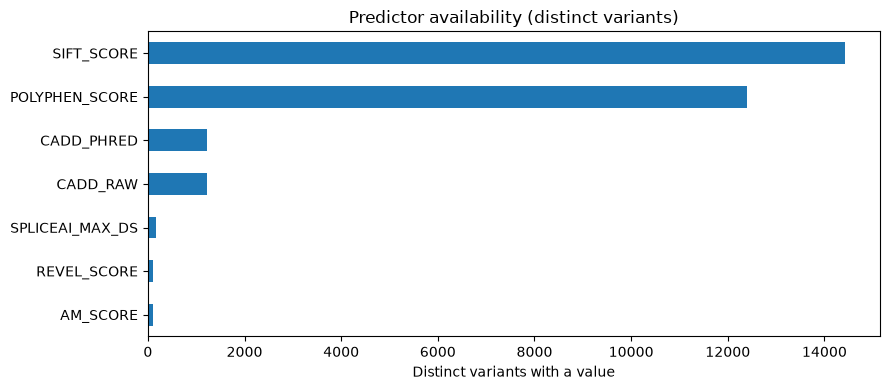

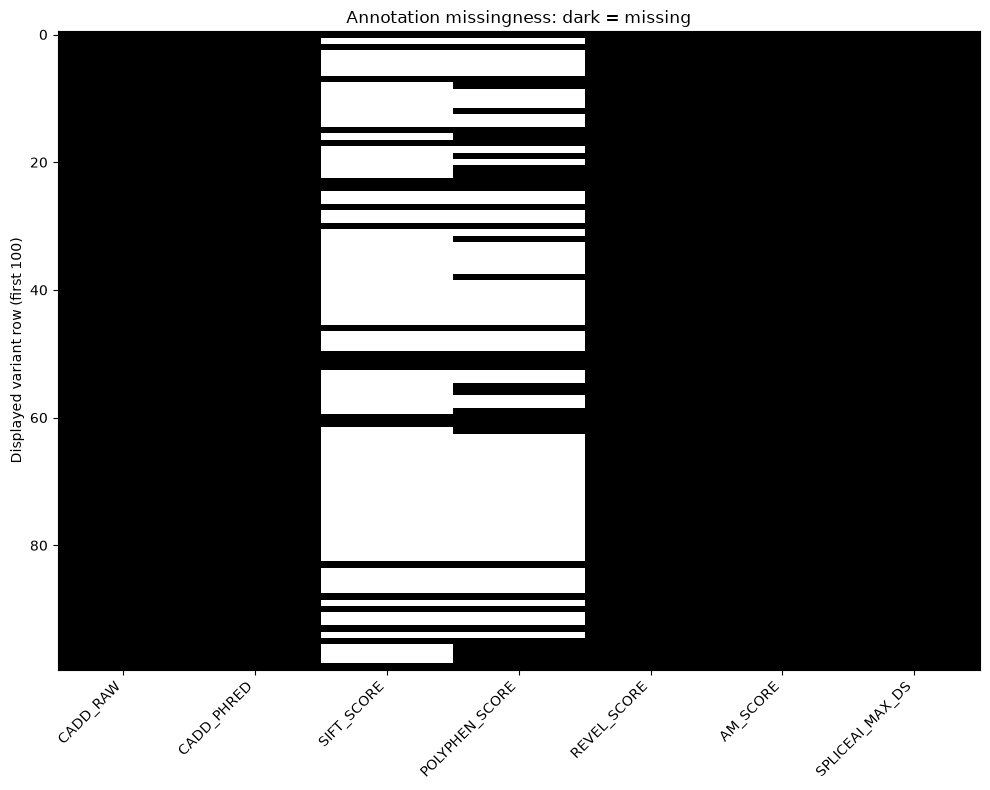

In [4]:
ma_predictor_columns = [
    "CADD_RAW", "CADD_PHRED", "SIFT_SCORE", "POLYPHEN_SCORE",
    "REVEL_SCORE", "AM_SCORE", "SPLICEAI_MAX_DS",
]
ma_missense_mask = ma_variants["CONSEQUENCE"].astype("string").str.lower().str.contains(
    r"(^|&)missense_variant(&|$)", regex=True, na=False
)
ma_integrity_summary = ma_pd.DataFrame({
    "metric": [
        "source annotation rows", "distinct normalized variants",
        "distinct variant–gene associations", "represented gene symbols",
        "preparation issues", "missing optional columns", "extra columns",
    ],
    "value": [
        len(ma_rows), len(ma_variants), len(ma_gene_rows),
        ma_gene_rows["SYMBOL"].nunique(), len(ma_issues),
        len(ma_missing_optional_columns), len(ma_extra_columns),
    ],
})
ma_show_table(ma_integrity_summary, "Integrity summary", n=len(ma_integrity_summary))
ma_show_table(ma_issues, "Preparation issues", n=ma_top_n)

ma_coverage = ma_pd.DataFrame({
    "overall_available": ma_variants[ma_predictor_columns].notna().sum(),
    "overall_denominator": len(ma_variants),
    "missense_available": ma_variants.loc[ma_missense_mask, ma_predictor_columns].notna().sum(),
    "missense_denominator": int(ma_missense_mask.sum()),
})
ma_coverage["overall_percent"] = 100 * ma_coverage["overall_available"] / max(len(ma_variants), 1)
ma_coverage["missense_percent"] = 100 * ma_coverage["missense_available"] / max(int(ma_missense_mask.sum()), 1)
ma_show_table(ma_coverage.reset_index(names="predictor"), "Predictor availability", n=len(ma_coverage))
ma_coverage_counts = ma_variants[ma_predictor_columns].notna().sum().sort_values()
if ma_coverage_counts.empty:
    ma_display(ma_Markdown("**Predictor availability:** no predictor columns available."))
else:
    ma_ax = ma_coverage_counts.plot.barh(figsize=(9, 4))
    ma_ax.set_title("Predictor availability (distinct variants)")
    ma_ax.set_xlabel("Distinct variants with a value")
    ma_ax.set_ylabel("")
    ma_plt.tight_layout()
    ma_plt.show()

ma_missing_matrix = ma_variants[ma_predictor_columns].head(100).isna().astype(int)
if ma_missing_matrix.empty:
    ma_display(ma_Markdown("**Missingness heatmap:** no variants available."))
else:
    ma_fig, ma_ax = ma_plt.subplots(figsize=(10, max(2, len(ma_missing_matrix) * 0.08)))
    ma_ax.imshow(ma_missing_matrix, aspect="auto", interpolation="nearest", cmap="Greys")
    ma_ax.set_xticks(range(len(ma_predictor_columns)), ma_predictor_columns, rotation=45, ha="right")
    ma_ax.set_ylabel("Displayed variant row (first 100)")
    ma_ax.set_title("Annotation missingness: dark = missing")
    ma_plt.tight_layout()
    ma_plt.show()

**Interpretation after execution.** Review issue counts before interpreting plots. Duplicate transcript rows explain why source-row totals can exceed unique-key totals; conflicting annotations require transcript-aware review. Availability percentages use distinct variants globally and missense variants for the missense denominator. No imputation is performed.

## 2. Variant landscape

**Question.** What molecular forms, impacts, chromosomes, and consequence terms are represented? Counts use distinct genomic keys. Variant type is defined from normalized REF/ALT lengths: SNV, insertion, deletion, equal-length multi-base, or symbolic/other. Consequences separated by `&` count a key once per term.

High counts describe this prefiltered table—not genome-wide burden. Chromosome counts are descriptive and cannot establish aneuploidy. HIGH/MODERATE enrichment reflects upstream selection, so there is no unfiltered-genome denominator. A dominant missense bar, for example, may reflect annotation and prefiltering rather than biology; compare against the upstream filter before follow-up.

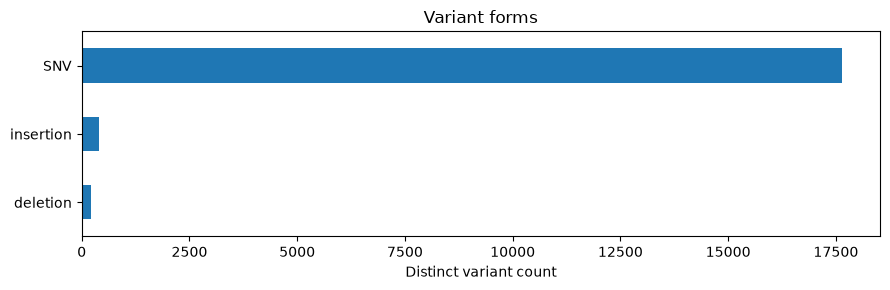

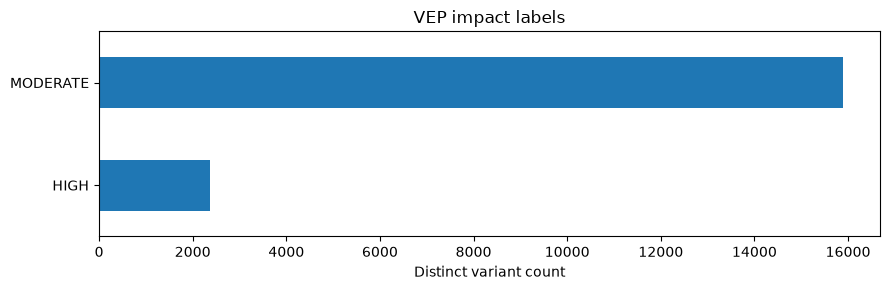

**Consequence terms** — showing 30 of 78 rows.

,ma_consequence,distinct_variants
0,missense_variant,13758
1,"missense_variant,NMD_transcript_variant",1293
2,frameshift_variant,517
3,"splice_donor_variant,non_coding_transcript_var...",423
4,"missense_variant,splice_region_variant",301
5,"splice_acceptor_variant,non_coding_transcript_...",262
6,inframe_deletion,257
7,stop_gained,221
8,inframe_insertion,196
9,splice_donor_variant,169


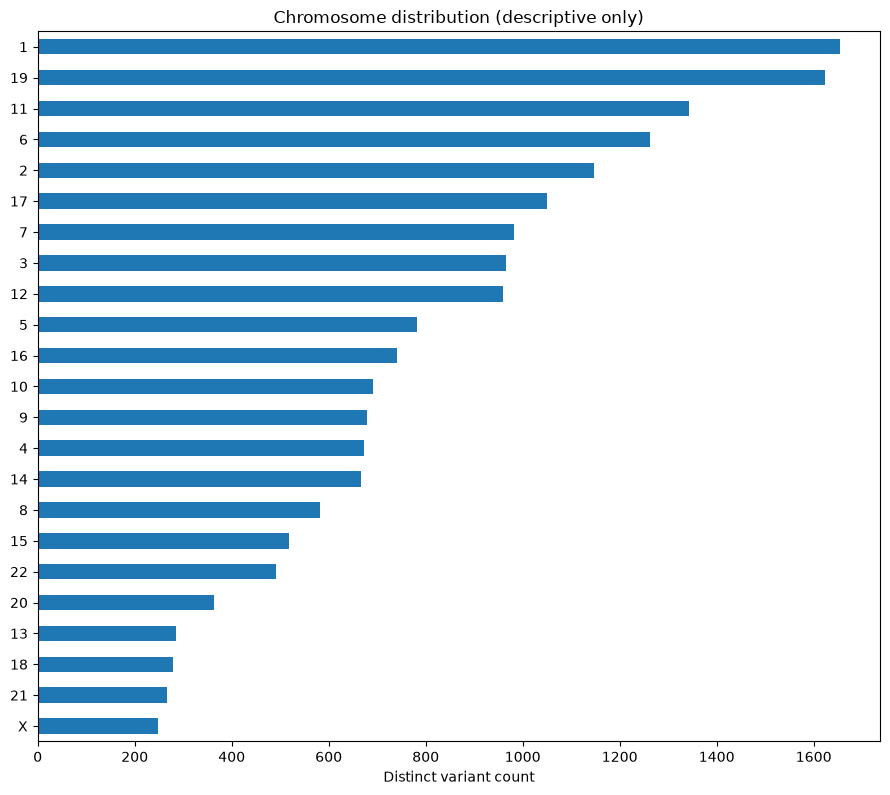

In [5]:
def ma_variant_type(ma_record):
    ma_ref, ma_alt = str(ma_record["REF"]), str(ma_record["ALT"])
    if any(ma_mark in ma_ref + ma_alt for ma_mark in "<>[]*"):
        return "symbolic/other"
    if len(ma_ref) == len(ma_alt) == 1:
        return "SNV"
    if len(ma_ref) < len(ma_alt):
        return "insertion"
    if len(ma_ref) > len(ma_alt):
        return "deletion"
    if len(ma_ref) == len(ma_alt) > 1:
        return "equal-length multi-base"
    return "symbolic/other"


ma_variants["ma_variant_type"] = ma_variants.apply(ma_variant_type, axis=1)
ma_plot_counts(ma_variants["ma_variant_type"], "Variant forms")
ma_plot_counts(ma_variants["IMPACT"].astype("string").str.upper(), "VEP impact labels")

ma_consequences = (
    ma_variants[["VARIANT_KEY", "CONSEQUENCE"]]
    .assign(ma_consequence=lambda ma_x: ma_x["CONSEQUENCE"].astype("string").str.split("&"))
    .explode("ma_consequence")
)
ma_consequences["ma_consequence"] = ma_consequences["ma_consequence"].astype("string").str.strip()
ma_consequence_counts = (
    ma_consequences.dropna(subset=["ma_consequence"])
    .drop_duplicates(["VARIANT_KEY", "ma_consequence"])
    .groupby("ma_consequence")["VARIANT_KEY"].nunique()
    .sort_values(ascending=False)
)
ma_show_table(ma_consequence_counts.rename("distinct_variants").reset_index(), "Consequence terms", n=ma_top_n)
ma_plot_counts(ma_variants["CHROM_NORM"], "Chromosome distribution (descriptive only)")

**Interpretation after execution.** Read every bar as “among distinct variants already retained in this CSV.” Equal-length multi-base changes are not SNVs. A key contributing multiple consequence terms appears once in each relevant term, so term totals may exceed global variants. No chromosome plot supports mosaicism or a cytogenetic diagnosis.

## 3. Population evidence

**Question.** Which variants have numeric frequency evidence, and where do sources or imported flags disagree? `ma_review_af` is the row-wise maximum of validated `AF_POPULATION`, `GNOMAD_AF`, and `GNOMAD_GRPMAX_AF`: a conservative research-triage summary, **not** a gnomAD field. `GNOMAD_GRPMAX_AF` is retained as raw group-maximum AF from this workflow—not filtering AF/FAF or a confidence bound ([gnomAD clarification](https://discuss.gnomad.broadinstitute.org/t/difference-between-popmax-in-the-vcf-and-popmax-grpmaxfaf-in-the-website/63)).

Bins use distinct variants: zero, $(0,10^{-5}]$, $(10^{-5},10^{-4}]$, $(10^{-4},10^{-3}]$, $(10^{-3},10^{-2}]$, $>10^{-2}$, and unknown. Positive values alone use a log x-axis; zero and unknown are counted separately. Lower AF can support rarity triage but is not pathogenicity. `not_found` means reported not found with coverage/provenance unverified; it is not zero and does not assign PM2. Counts and homozygotes describe a reference cohort, not the patient ([gnomAD v4 context](https://gnomad.broadinstitute.org/news/2023-11-gnomad-v4-0/)).

**Frequency bins** — showing 7 of 7 rows.

,review_af_bin,distinct_variants
0,zero,4
1,"(0,1e-5]",25
2,"(1e-5,1e-4]",67
3,"(1e-4,1e-3]",214
4,"(1e-3,1e-2]",443
5,>1e-2,16187
6,unknown,1312


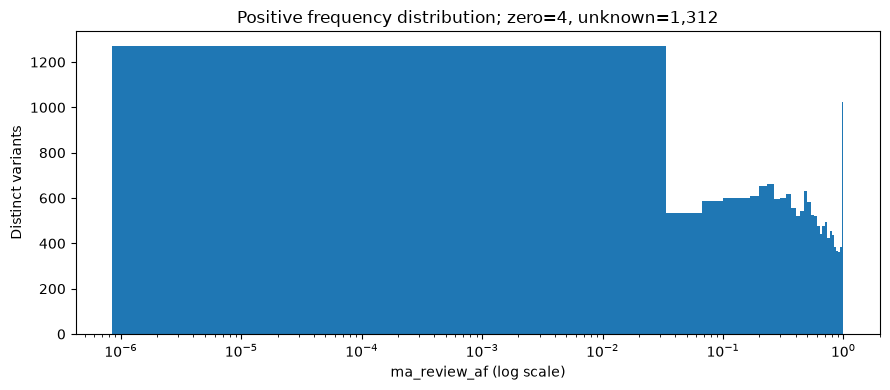

**Global versus group-maximum AF** — showing 30 of 1,230 rows.

,VARIANT_KEY,SYMBOL,GNOMAD_AF,GNOMAD_GRPMAX_AF,absolute_difference
8335,1:146974762:C:A,NBPF12,0.430771,0.998033,0.567262
5109,16:8645986:C:CGCCTGCTCCGTGGCTGACGTGTTGTCTAACTA...,METTL22,0.378380,0.895526,0.517146
7240,19:41577497:A:C,CEACAM21,0.292761,0.804456,0.511695
8268,1:120460621:C:A,NBPF8,0.203052,0.684213,0.481161
18159,X:2221145:C:T,DHRSX,0.298395,0.773341,0.474946
2866,12:7190512:GGCCTCTGAGGCAGTGAGTGTTCTTGAGGTGGAAA...,PEX5,0.269699,0.715869,0.446170
6210,17:82160327:AAGACAGGCCAGGTGCAGTGACTCATACCTGTAA...,ENSG00000266654,0.452506,0.869956,0.417450
8327,1:145872788:G:C,ANKRD35,0.417535,0.827877,0.410342
7665,19:54222365:G:C,LILRB3,0.162175,0.567474,0.405299
5350,17:21702953:C:A,KCNJ18,0.443561,0.847508,0.403947


**Imported rarity-flag discrepancies versus ma_review_af ≤ 0.001** — showing 30 of 15,565 rows.

,VARIANT_KEY,SYMBOL,ma_review_af,GNOMAD_RARE_FLAG,GNOMAD_RARITY,GNOMAD_STATUS
0,10:100199101:-:G,CHUK,0.0078,True,ABSENT,not_found
1,10:100356554:-:C,SCD,0.3890,True,ABSENT,not_found
2,10:100442889:-:C,OLMALINC,0.2804,True,ABSENT,not_found
3,10:100536079:-:G,HIF1AN,0.1807,True,ABSENT,not_found
4,10:100924623:-:A,SLF2,0.3187,True,ABSENT,not_found
5,10:100984574:-:T,SEMA4G,0.2556,True,ABSENT,not_found
6,10:101010325:-:G,PDZD7,0.7730,True,ABSENT,not_found
7,10:101010536:-:GCTGCG,PDZD7,0.2468,True,ABSENT,not_found
8,10:101017704:-:C,PDZD7,0.5455,True,ABSENT,not_found
9,10:101023921:-:C,PDZD7,0.5960,True,ABSENT,not_found


**Exploratory rarity sensitivity** — showing 3 of 3 rows.

,exploratory_cutoff,distinct_variants_at_or_below,numeric_af_denominator
0,0.0001,96,16940
1,0.0010,310,16940
2,0.0100,753,16940


In [6]:
ma_af_columns = ["AF_POPULATION", "GNOMAD_AF", "GNOMAD_GRPMAX_AF"]
ma_variants["ma_review_af"] = ma_variants[ma_af_columns].max(axis=1, skipna=True)
ma_variants.loc[ma_variants[ma_af_columns].notna().sum(axis=1).eq(0), "ma_review_af"] = ma_np.nan

ma_af_bins = [-ma_np.inf, 0, 1e-5, 1e-4, 1e-3, 1e-2, ma_np.inf]
ma_af_labels = ["zero", "(0,1e-5]", "(1e-5,1e-4]", "(1e-4,1e-3]", "(1e-3,1e-2]", ">1e-2"]
ma_variants["ma_af_bin"] = ma_pd.cut(
    ma_variants["ma_review_af"], bins=ma_af_bins, labels=ma_af_labels,
    include_lowest=True, right=True,
).astype("string").fillna("unknown")
ma_af_bin_counts = (
    ma_variants["ma_af_bin"].value_counts()
    .reindex(ma_af_labels + ["unknown"], fill_value=0)
    .rename_axis("review_af_bin").reset_index(name="distinct_variants")
)
ma_show_table(ma_af_bin_counts, "Frequency bins", n=len(ma_af_bin_counts))

ma_positive_af = ma_variants.loc[ma_variants["ma_review_af"].gt(0), "ma_review_af"]
if ma_positive_af.empty:
    ma_display(ma_Markdown("**Positive-frequency plot:** no positive validated AF values."))
else:
    ma_fig, ma_ax = ma_plt.subplots(figsize=(9, 4))
    ma_ax.hist(ma_positive_af, bins=30)
    ma_ax.set_xscale("log")
    ma_ax.set_xlabel("ma_review_af (log scale)")
    ma_ax.set_ylabel("Distinct variants")
    ma_ax.set_title(
        f"Positive frequency distribution; zero={(ma_variants['ma_review_af'] == 0).sum():,}, "
        f"unknown={ma_variants['ma_review_af'].isna().sum():,}"
    )
    ma_plt.tight_layout()
    ma_plt.show()

ma_af_comparison = ma_variants.loc[
    ma_variants["GNOMAD_AF"].notna() & ma_variants["GNOMAD_GRPMAX_AF"].notna(),
    ["VARIANT_KEY", "SYMBOL", "GNOMAD_AF", "GNOMAD_GRPMAX_AF"],
].copy()
ma_af_comparison["absolute_difference"] = (
    ma_af_comparison["GNOMAD_GRPMAX_AF"] - ma_af_comparison["GNOMAD_AF"]
).abs()
ma_show_table(
    ma_af_comparison.sort_values("absolute_difference", ascending=False),
    "Global versus group-maximum AF", n=ma_top_n,
)

ma_variants["ma_numeric_rare_001"] = ma_variants["ma_review_af"].le(0.001)
ma_flag_discrepancies = ma_variants.loc[
    ma_variants["GNOMAD_RARE_FLAG"].notna()
    & ma_variants["ma_review_af"].notna()
    & ma_variants["GNOMAD_RARE_FLAG"].ne(ma_variants["ma_numeric_rare_001"]),
    ["VARIANT_KEY", "SYMBOL", "ma_review_af", "GNOMAD_RARE_FLAG", "GNOMAD_RARITY", "GNOMAD_STATUS"],
]
ma_show_table(ma_flag_discrepancies, "Imported rarity-flag discrepancies versus ma_review_af ≤ 0.001", n=ma_top_n)
ma_sensitivity = ma_pd.DataFrame({
    "exploratory_cutoff": [1e-4, 1e-3, 1e-2],
    "distinct_variants_at_or_below": [
        int(ma_variants["ma_review_af"].le(ma_cutoff).sum()) for ma_cutoff in [1e-4, 1e-3, 1e-2]
    ],
    "numeric_af_denominator": [int(ma_variants["ma_review_af"].notna().sum())] * 3,
})
ma_show_table(ma_sensitivity, "Exploratory rarity sensitivity", n=len(ma_sensitivity))

**Interpretation after execution.** Threshold counts are sensitivity views, not disease-specific cutoffs. Large global/group-max differences may be ancestry-relevant and need original gnomAD provenance. `AN=0`, `AC>AN`, homozygote/count inconsistencies, and AF-versus-AC/AN discrepancies are already listed in `ma_issues`; never repair them by substituting derived AF.

## 4. Clinical annotations

**Question.** How do imported `CLIN_SIG` and `ACMG_CLASSIFICATION` labels compare? Each source is normalized independently into conflict, mixed P/LP with benign/VUS, P/LP, VUS, B/LB, other, or missing. Exact tokens/phrases are recognized after underscore/space normalization; “pathogenic” inside a conflicting phrase never becomes definitive P/LP.

Cross-tab cells count distinct representative variants. High concordance reflects imported text agreement, not valid ACMG reclassification. Discordance examples retain `ACMG_CRITERIA`. ClinVar review stars, evaluation date, condition, submitter context, and allele-condition mapping are unavailable—not zero or negative evidence ([ClinVar significance](https://www.ncbi.nlm.nih.gov/clinvar/docs/clinsig/), [review status](https://www.ncbi.nlm.nih.gov/clinvar/docs/review_status/)).

In [7]:
ma_variants["ma_clin_sig_category"] = ma_variants["CLIN_SIG"].map(ma_clinical_category)
ma_variants["ma_acmg_category"] = ma_variants["ACMG_CLASSIFICATION"].map(ma_clinical_category)
ma_clinical_crosstab = ma_pd.crosstab(
    ma_variants["ma_clin_sig_category"], ma_variants["ma_acmg_category"],
    margins=True,
)
ma_show_table(ma_clinical_crosstab.reset_index(), "Clinical-label cross-tab", n=len(ma_clinical_crosstab))

ma_clinical_discordance = ma_variants.loc[
    ma_variants["ma_clin_sig_category"].ne(ma_variants["ma_acmg_category"])
    & ~(
        ma_variants["ma_clin_sig_category"].eq("missing")
        & ma_variants["ma_acmg_category"].eq("missing")
    ),
    [
        "VARIANT_KEY", "SYMBOL", "CLIN_SIG", "ma_clin_sig_category",
        "ACMG_CLASSIFICATION", "ma_acmg_category", "ACMG_CRITERIA",
    ],
]
ma_show_table(ma_clinical_discordance, "Clinical-source discordances", n=ma_top_n)

**Clinical-label cross-tab** — showing 7 of 7 rows.

ma_acmg_category,ma_clin_sig_category,B/LB,P/LP,other,All
0,B/LB,3780,28,149,3957
1,P/LP,0,5,0,5
2,VUS,38,16,93,147
3,conflict,17,25,0,42
4,mixed P/LP with benign/VUS,25,7,0,32
5,other,11428,671,1970,14069
6,All,15288,752,2212,18252


**Clinical-source discordances** — showing 30 of 12,497 rows.

,VARIANT_KEY,SYMBOL,CLIN_SIG,ma_clin_sig_category,ACMG_CLASSIFICATION,ma_acmg_category,ACMG_CRITERIA
1,10:100356554:-:C,SCD,-,other,Benign,B/LB,BA1; BP4
2,10:100442889:-:C,OLMALINC,-,other,Benign,B/LB,BA1; PVS1
3,10:100536079:-:G,HIF1AN,-,other,Benign,B/LB,BA1; BP4
4,10:100924623:-:A,SLF2,-,other,Benign,B/LB,BA1; PP3
5,10:100984574:-:T,SEMA4G,-,other,Benign,B/LB,BA1
7,10:101010536:-:GCTGCG,PDZD7,-,other,Benign,B/LB,BA1; PM3
10,10:101064592:-:C,KAZALD1,-,other,Benign,B/LB,BA1; BP4
15,10:1019517:-:A,IDI2,-,other,Benign,B/LB,BA1
16,10:102039785:-:T,ARMH3,-,other,Benign,B/LB,BA1
17,10:102367414:-:A,GBF1,-,other,Benign,B/LB,BA1; PVS1; PM3


**Interpretation after execution.** A P/LP label is a review prompt, not a final classification in this case. Mixed/conflicting labels should be traced to current ClinVar records and condition context. Criteria strings are reported, never recomputed or treated as independently verified.

## 5. CADD, SIFT, and PolyPhen

**Question.** What broad coding-deleteriousness evidence is present, and where do score/category fields disagree? CADD raw and PHRED distributions are shown by consequence. CADD PHRED markers 10/20/30 denote approximately the top 10%/1%/0.1% of possible reference SNVs, not disease probability; there is no universal clinical cutoff ([CADD documentation](https://cadd.gs.washington.edu/info)).

Lower SIFT scores and higher PolyPhen scores generally indicate stronger predicted damage, but this report uses supplied prediction categories rather than inventing unverified cutoffs. Missing score/category is unavailable evidence. A supplied damaging category paired with a missing score, for example, is a provenance check—not grounds to overwrite either field.

**CADD by consequence** — showing 30 of 78 rows.

,ma_consequence,distinct_variants,cadd_raw_available,cadd_raw_median,cadd_phred_available,cadd_phred_median
0,missense_variant,13758,750,0.216144,750,2.4315
1,"missense_variant,NMD_transcript_variant",1293,35,0.251705,35,2.7680
2,frameshift_variant,517,152,2.743102,152,20.0800
3,"splice_donor_variant,non_coding_transcript_var...",423,25,0.532679,25,5.7960
4,"missense_variant,splice_region_variant",301,15,0.943023,15,9.6890
5,"splice_acceptor_variant,non_coding_transcript_...",262,18,0.368986,18,4.0420
6,inframe_deletion,257,60,0.748868,60,7.8215
7,stop_gained,221,24,6.681408,24,35.0000
8,inframe_insertion,196,59,0.657856,59,6.9980
9,splice_donor_variant,169,6,1.571313,6,13.4820


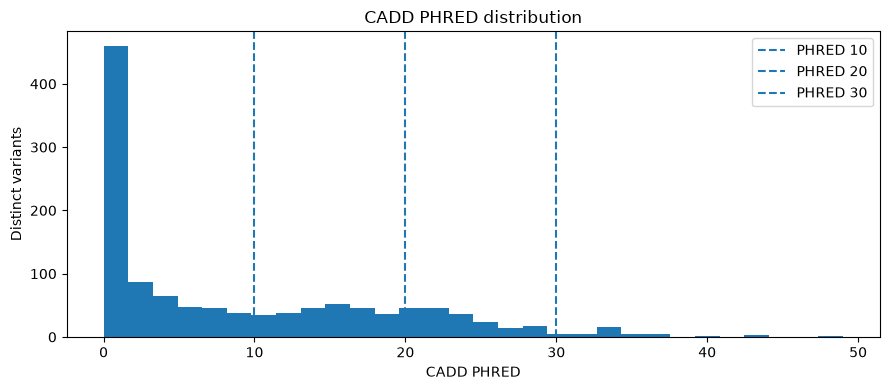

**SIFT category/score availability disagreements** — showing 0 of 0 rows.

_No rows meet this definition._

**PolyPhen category/score availability disagreements** — showing 0 of 0 rows.

_No rows meet this definition._

In [8]:
ma_coding_long = (
    ma_variants[["VARIANT_KEY", "CONSEQUENCE", "CADD_RAW", "CADD_PHRED"]]
    .assign(ma_consequence=lambda ma_x: ma_x["CONSEQUENCE"].astype("string").str.split("&"))
    .explode("ma_consequence")
)
ma_coding_long["ma_consequence"] = ma_coding_long["ma_consequence"].astype("string").str.strip()
ma_coding_summary = (
    ma_coding_long.groupby("ma_consequence", dropna=False)
    .agg(
        distinct_variants=("VARIANT_KEY", "nunique"),
        cadd_raw_available=("CADD_RAW", "count"),
        cadd_raw_median=("CADD_RAW", "median"),
        cadd_phred_available=("CADD_PHRED", "count"),
        cadd_phred_median=("CADD_PHRED", "median"),
    )
    .sort_values("distinct_variants", ascending=False)
)
ma_show_table(ma_coding_summary.reset_index(), "CADD by consequence", n=ma_top_n)

ma_cadd = ma_variants["CADD_PHRED"].dropna()
if ma_cadd.empty:
    ma_display(ma_Markdown("**CADD PHRED plot:** no values available."))
else:
    ma_fig, ma_ax = ma_plt.subplots(figsize=(9, 4))
    ma_ax.hist(ma_cadd, bins=30)
    for ma_cutoff in [10, 20, 30]:
        ma_ax.axvline(ma_cutoff, linestyle="--", label=f"PHRED {ma_cutoff}")
    ma_ax.set_xlabel("CADD PHRED")
    ma_ax.set_ylabel("Distinct variants")
    ma_ax.set_title("CADD PHRED distribution")
    ma_ax.legend()
    ma_plt.tight_layout()
    ma_plt.show()

ma_sift_text = ma_variants["SIFT_PRED"].astype("string").str.lower()
ma_polyphen_text = ma_variants["POLYPHEN_PRED"].astype("string").str.lower()
ma_sift_disagreement = ma_variants.loc[
    ma_sift_text.str.contains("deleterious", na=False) & ma_variants["SIFT_SCORE"].isna(),
    ["VARIANT_KEY", "SYMBOL", "SIFT_PRED", "SIFT_SCORE"],
]
ma_polyphen_disagreement = ma_variants.loc[
    ma_polyphen_text.str.contains("damaging", na=False) & ma_variants["POLYPHEN_SCORE"].isna(),
    ["VARIANT_KEY", "SYMBOL", "POLYPHEN_PRED", "POLYPHEN_SCORE"],
]
ma_show_table(ma_sift_disagreement, "SIFT category/score availability disagreements", n=ma_top_n)
ma_show_table(ma_polyphen_disagreement, "PolyPhen category/score availability disagreements", n=ma_top_n)

**Interpretation after execution.** Consequence-stratified distributions expose selection effects and annotation availability. CADD, SIFT, and PolyPhen share biological inputs and are not independent clinical votes. Review original transcripts and source versions where labels and scores do not align.

## 6. Missense predictors

**Question.** Among missense variants, how do REVEL, AlphaMissense, and CADD compare? Histograms use predictor-native units; scatter axes are labeled scores. REVEL 0.5/0.75 are exploratory legacy thresholds, not clinical PP3 bands. AlphaMissense 0.34/0.564 mark developer categories; supplied `AM_CLASS` is retained, especially at rounded boundaries ([AlphaMissense score guide](https://www.ebi.ac.uk/training/online/courses/alphafold/classifying-the-effects-of-missense-variants-using-alphamissense/understanding-pathogenicity-scores-from-alphamissense/), [paper](https://doi.org/10.1126/science.adg7492)).

AlphaMissense “likely pathogenic” is not ACMG “likely pathogenic,” and its score is not this patient’s disease probability. Missing predictors reduce pairwise sample size. Transcript comparison strips version suffixes only; discordance warrants transcript review.

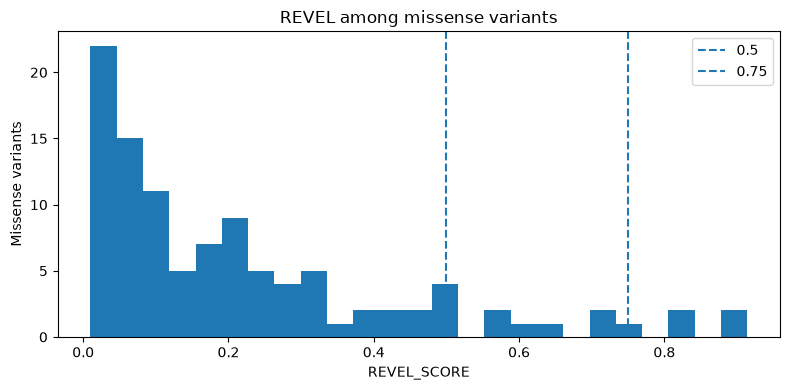

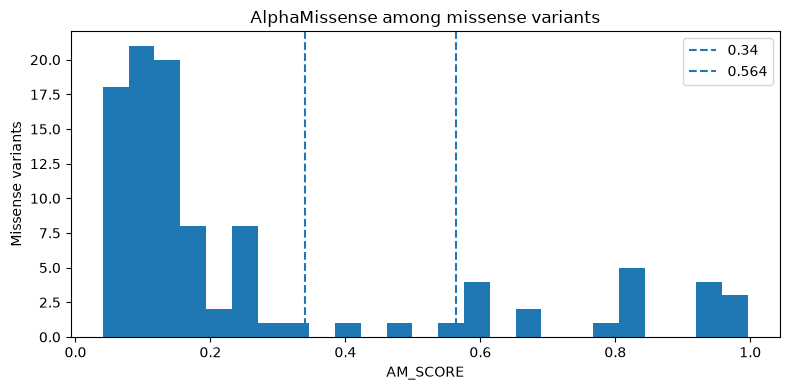

**REVEL versus AlphaMissense:** pairwise complete $n=98$.

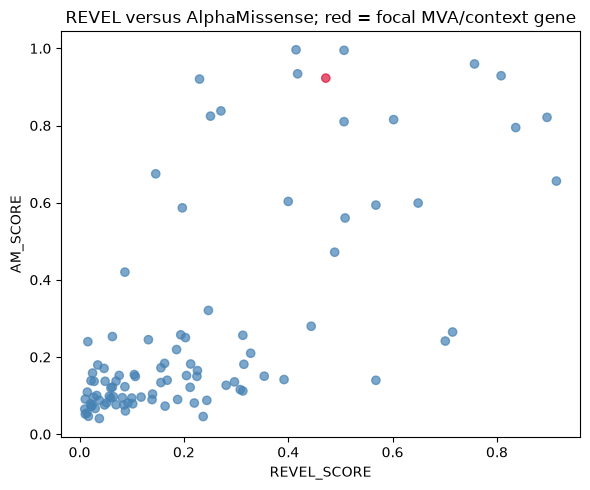

**CADD PHRED versus REVEL:** pairwise complete $n=105$.

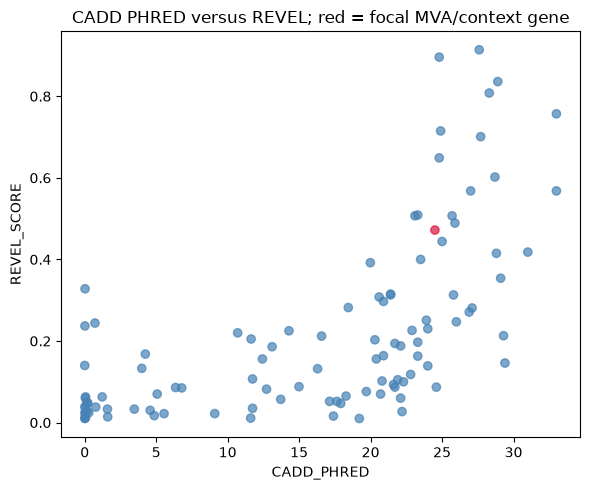

**Feature/AlphaMissense transcript discordances** — showing 30 of 13,687 rows.

,VARIANT_KEY,SYMBOL,FEATURE_TRANSCRIPT,AM_TRANSCRIPT,AM_SCORE,AM_CLASS
1,10:100356554:-:C,SCD,ENST00000370355,,NaN,
3,10:100536079:-:G,HIF1AN,ENST00000299163,,NaN,
4,10:100924623:-:A,SLF2,ENST00000238961,,NaN,
5,10:100984574:-:T,SEMA4G,ENST00000517724,,NaN,
6,10:101010325:-:G,PDZD7,ENST00000619208,,NaN,
8,10:101017704:-:C,PDZD7,ENST00001048511,,NaN,
10,10:101064592:-:C,KAZALD1,ENST00000370200,,NaN,
11,10:101580299:-:A,POLL,ENST00000370162,,NaN,
12,10:101580387:-:G,POLL,ENST00001035442,,NaN,
13,10:101608897:-:C,DPCD,ENST00000370151,,NaN,


In [9]:
ma_missense = ma_variants.loc[ma_missense_mask].copy()
ma_mva_symbol_mask = ma_missense["SYMBOL"].isin(ma_focal_genes)

for ma_col, ma_markers, ma_title in [
    ("REVEL_SCORE", [0.5, 0.75], "REVEL among missense variants"),
    ("AM_SCORE", [0.34, 0.564], "AlphaMissense among missense variants"),
]:
    ma_values = ma_missense[ma_col].dropna()
    if ma_values.empty:
        ma_display(ma_Markdown(f"**{ma_title}:** no values available."))
    else:
        ma_fig, ma_ax = ma_plt.subplots(figsize=(8, 4))
        ma_ax.hist(ma_values, bins=25)
        for ma_marker in ma_markers:
            ma_ax.axvline(ma_marker, linestyle="--", label=str(ma_marker))
        ma_ax.set_xlabel(ma_col)
        ma_ax.set_ylabel("Missense variants")
        ma_ax.set_title(ma_title)
        ma_ax.legend()
        ma_plt.tight_layout()
        ma_plt.show()

for ma_x, ma_y, ma_title in [
    ("REVEL_SCORE", "AM_SCORE", "REVEL versus AlphaMissense"),
    ("CADD_PHRED", "REVEL_SCORE", "CADD PHRED versus REVEL"),
]:
    ma_pair = ma_missense.loc[ma_missense[[ma_x, ma_y]].notna().all(axis=1)]
    ma_display(ma_Markdown(f"**{ma_title}:** pairwise complete $n={len(ma_pair):,}$."))
    if not ma_pair.empty:
        ma_fig, ma_ax = ma_plt.subplots(figsize=(6, 5))
        ma_ax.scatter(
            ma_pair[ma_x], ma_pair[ma_y],
            c=ma_pair["SYMBOL"].isin(ma_focal_genes).map({True: "crimson", False: "steelblue"}),
            alpha=0.7,
        )
        ma_ax.set_xlabel(ma_x)
        ma_ax.set_ylabel(ma_y)
        ma_ax.set_title(f"{ma_title}; red = focal MVA/context gene")
        ma_plt.tight_layout()
        ma_plt.show()

ma_feature_tx = ma_missense["FEATURE_TRANSCRIPT"].astype("string").str.replace(r"\.\d+$", "", regex=True)
ma_am_tx = ma_missense["AM_TRANSCRIPT"].astype("string").str.replace(r"\.\d+$", "", regex=True)
ma_transcript_discordance = ma_missense.loc[
    ma_feature_tx.notna() & ma_am_tx.notna() & ma_feature_tx.ne(ma_am_tx),
    ["VARIANT_KEY", "SYMBOL", "FEATURE_TRANSCRIPT", "AM_TRANSCRIPT", "AM_SCORE", "AM_CLASS"],
]
ma_show_table(ma_transcript_discordance, "Feature/AlphaMissense transcript discordances", n=ma_top_n)

**Interpretation after execution.** Scatter agreement may reflect shared training features and preselection. Red focal points identify review priority, not causality. Use pairwise $n$ beside every plot; missing values must not be treated as zero. Transcript mismatches can explain apparent predictor disagreement.

## 7. Predictor agreement and discordance

**Question.** Which numeric predictors move together, and which missense variants show explicit REVEL/AlphaMissense disagreement? Spearman correlation is computed as Pearson correlation of pandas ranks, with pairwise-complete counts. Constant columns and pairs with fewer than three observations are omitted.

Large absolute correlations are descriptive, not independent-vote evidence. Correlated tools, shared annotations, missingness, and HIGH/MODERATE preselection bias interpretation. Discordance queues use REVEL ≥0.75 or <0.5 and the **supplied** AlphaMissense categories; no additive score is created.

In [10]:
ma_agreement_columns = [
    "CADD_RAW", "CADD_PHRED", "SIFT_SCORE", "POLYPHEN_SCORE",
    "REVEL_SCORE", "AM_SCORE", "SPLICEAI_MAX_DS",
]
ma_agreement_data = ma_variants[ma_agreement_columns]
ma_nonconstant = [
    ma_col for ma_col in ma_agreement_columns
    if ma_agreement_data[ma_col].dropna().nunique() > 1
]
ma_ranked = ma_agreement_data[ma_nonconstant].rank()
ma_correlation = ma_ranked.corr()
ma_pair_counts = ma_pd.DataFrame(index=ma_nonconstant, columns=ma_nonconstant, dtype="Int64")
for ma_left in ma_nonconstant:
    for ma_right in ma_nonconstant:
        ma_n = int(ma_agreement_data[[ma_left, ma_right]].notna().all(axis=1).sum())
        ma_pair_counts.loc[ma_left, ma_right] = ma_n
        if ma_n < 3:
            ma_correlation.loc[ma_left, ma_right] = ma_np.nan
ma_show_table(ma_correlation.reset_index(names="predictor"), "Pairwise Spearman correlations", n=len(ma_correlation))
ma_show_table(ma_pair_counts.reset_index(names="predictor"), "Pairwise complete sample counts", n=len(ma_pair_counts))

ma_am_class_text = ma_missense["AM_CLASS"].astype("string").str.strip().str.lower().str.replace(" ", "_")
ma_high_revel_low_am = ma_missense.loc[
    ma_missense["REVEL_SCORE"].ge(0.75)
    & ma_am_class_text.isin(["likely_benign", "ambiguous"]),
    ["VARIANT_KEY", "SYMBOL", "HGVS_P", "REVEL_SCORE", "AM_SCORE", "AM_CLASS", "CADD_PHRED"],
]
ma_low_revel_high_am = ma_missense.loc[
    ma_missense["REVEL_SCORE"].lt(0.5)
    & ma_am_class_text.isin(["likely_pathogenic"]),
    ["VARIANT_KEY", "SYMBOL", "HGVS_P", "REVEL_SCORE", "AM_SCORE", "AM_CLASS", "CADD_PHRED"],
]
ma_show_table(ma_high_revel_low_am, "High REVEL / low-or-ambiguous AlphaMissense", n=ma_top_n)
ma_show_table(ma_low_revel_high_am, "Low REVEL / likely-pathogenic AlphaMissense", n=ma_top_n)

**Pairwise Spearman correlations** — showing 7 of 7 rows.

,predictor,CADD_RAW,CADD_PHRED,SIFT_SCORE,POLYPHEN_SCORE,REVEL_SCORE,AM_SCORE,SPLICEAI_MAX_DS
0,CADD_RAW,1.000000,0.999994,-0.586907,0.478706,0.606709,0.589653,0.047762
1,CADD_PHRED,0.999994,1.000000,-0.586816,0.478606,0.606383,0.589723,0.047426
2,SIFT_SCORE,-0.586907,-0.586816,1.000000,-0.597641,-0.530861,-0.723189,-0.078472
3,POLYPHEN_SCORE,0.478706,0.478606,-0.597641,1.000000,0.493383,0.623204,-0.119137
4,REVEL_SCORE,0.606709,0.606383,-0.530861,0.493383,1.000000,0.676362,0.156441
5,AM_SCORE,0.589653,0.589723,-0.723189,0.623204,0.676362,1.000000,0.093798
6,SPLICEAI_MAX_DS,0.047762,0.047426,-0.078472,-0.119137,0.156441,0.093798,1.000000


**Pairwise complete sample counts** — showing 7 of 7 rows.

,predictor,CADD_RAW,CADD_PHRED,SIFT_SCORE,POLYPHEN_SCORE,REVEL_SCORE,AM_SCORE,SPLICEAI_MAX_DS
0,CADD_RAW,1218,1218,774,717,110,105,155
1,CADD_PHRED,1218,1218,774,717,110,105,155
2,SIFT_SCORE,774,774,14428,11981,109,104,118
3,POLYPHEN_SCORE,717,717,11981,12393,103,98,101
4,REVEL_SCORE,110,110,109,103,110,102,99
5,AM_SCORE,105,105,104,98,102,105,95
6,SPLICEAI_MAX_DS,155,155,118,101,99,95,158


**High REVEL / low-or-ambiguous AlphaMissense** — showing 0 of 0 rows.

_No rows meet this definition._

**Low REVEL / likely-pathogenic AlphaMissense** — showing 9 of 9 rows.

,VARIANT_KEY,SYMBOL,HGVS_P,REVEL_SCORE,AM_SCORE,AM_CLASS,CADD_PHRED
304,10:29463555:C:T,SVIL,p.Ala2072Thr,0.271,0.8378,likely_pathogenic,26.9
2315,12:123009897:C:T,PITPNM2,p.Arg199His,0.418,0.9340,likely_pathogenic,31.0
4057,15:40220612:T:G,BUB1B,p.Asn1002Lys,0.472,0.9229,likely_pathogenic,24.5
4632,16:2118216:C:T,PKD1,p.Cys259Tyr,0.400,0.6032,likely_pathogenic,23.5
5661,17:44967463:T:C,C1QL1,p.Lys196Glu,0.415,0.9963,likely_pathogenic,28.8
6815,19:19515378:G:A,TSSK6,p.Thr17Ile,0.146,0.6748,likely_pathogenic,29.4
10255,21:33772180:C:T,ITSN1,p.Arg388Trp,0.251,0.8243,likely_pathogenic,23.9
13145,4:125448901:T:C,FAT4,p.Phe2631Leu,0.230,0.9204,likely_pathogenic,24.0
14541,6:112068335:G:A,CCN6,p.Met240Ile,0.197,0.5866,likely_pathogenic,23.3


**Interpretation after execution.** Compare each coefficient with its pair-count cell. A visually large coefficient based on few variants is fragile. Discordance is a prompt to check transcript, amino-acid change, predictor version, and source record—not a reason to select whichever score supports a preferred conclusion.

## 8. Splice events

**Question.** Do event-specific SpliceAI scores agree with the imported maximum, and where is the strongest predicted event? The four DS columns are recomputed without treating missing values as zero. Rows with some but not all event scores are marked partial; differences above $10^{-6}$ from imported `SPLICEAI_MAX_DS` are displayed.

The 0.2/0.5/0.8 lines correspond to high-recall/recommended/high-precision characterization in the [SpliceAI documentation](https://github.com/Illumina/SpliceAI), not clinical proof. Tied strongest events are preserved. `POS + DP` is a 1-based genomic site relative to the variant; it does not infer transcript strand. Missing scores are unknown, and predicted disruption needs RNA or functional confirmation.

**Partial or imported/recomputed splice-score discrepancies** — showing 0 of 0 rows.

_No rows meet this definition._

**Strongest splice events (ties retained)** — showing 30 of 429 rows.

,VARIANT_KEY,SYMBOL,SPLICEAI_GENE,event,delta_score,delta_position,predicted_genomic_site
10504,22:20996720:C:G,LZTR1,LZTR1,DS_AG,0.92,1.0,20996721.0
48108,2:233807853:C:T,MROH2A,MROH2A,DS_DG,0.81,-2.0,233807851.0
11236,2:178450414:G:GAAGGTCCCACTGTCCTCGCGCTCCAGCGGCG...,PRKRA,PRKRA,DS_AG,0.78,0.0,178450414.0
47013,22:21633009:G:T,CCDC116,CCDC116,DS_DG,0.26,-2.0,21633007.0
48901,3:160411998:G:A,SMC4,SMC4,DS_DG,0.19,-21.0,160411977.0
31751,4:56523792:CCTGA:C,ARL9,ARL9,DS_AL,0.11,-95.0,56523697.0
6325,18:26292354:A:G,TAF4B,TAF4B,DS_AG,0.07,-104.0,26292250.0
70431,6:72307353:C:T,RIMS1,RIMS1,DS_DL,0.07,17.0,72307370.0
17698,9:137185989:C:T,ANAPC2,ANAPC2,DS_AG,0.07,16.0,137186005.0
113,10:121851411:C:A,ATE1,ATE1,DS_AG,0.06,1.0,121851412.0


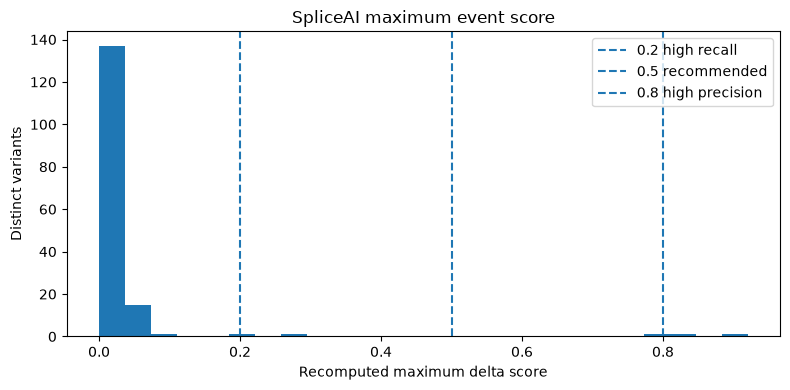

**SYMBOL versus SPLICEAI_GENE mismatches** — showing 30 of 18,107 rows.

,VARIANT_KEY,SYMBOL,SPLICEAI_GENE,ma_splice_max
0,10:100199101:-:G,CHUK,,NaN
1,10:100356554:-:C,SCD,,NaN
2,10:100442889:-:C,OLMALINC,,NaN
3,10:100536079:-:G,HIF1AN,,NaN
4,10:100924623:-:A,SLF2,,NaN
5,10:100984574:-:T,SEMA4G,,NaN
6,10:101010325:-:G,PDZD7,,NaN
7,10:101010536:-:GCTGCG,PDZD7,,NaN
8,10:101017704:-:C,PDZD7,,NaN
9,10:101023921:-:C,PDZD7,,NaN


In [11]:
ma_ds_columns = ["DS_AG", "DS_AL", "DS_DG", "DS_DL"]
ma_dp_map = {"DS_AG": "DP_AG", "DS_AL": "DP_AL", "DS_DG": "DP_DG", "DS_DL": "DP_DL"}
ma_variants["ma_splice_max"] = ma_variants[ma_ds_columns].max(axis=1, skipna=True)
ma_variants.loc[ma_variants[ma_ds_columns].notna().sum(axis=1).eq(0), "ma_splice_max"] = ma_np.nan
ma_variants["ma_splice_partial"] = ma_variants[ma_ds_columns].notna().sum(axis=1).between(1, 3)
ma_variants["ma_splice_max_difference"] = (
    ma_variants["ma_splice_max"] - ma_variants["SPLICEAI_MAX_DS"]
).abs()

ma_splice_discrepancy = ma_variants.loc[
    ma_variants["ma_splice_partial"]
    | ma_variants["ma_splice_max_difference"].gt(1e-6),
    ["VARIANT_KEY", "SYMBOL", *ma_ds_columns, "SPLICEAI_MAX_DS", "ma_splice_max", "ma_splice_partial"],
]
ma_show_table(ma_splice_discrepancy, "Partial or imported/recomputed splice-score discrepancies", n=ma_top_n)

ma_splice_long = ma_variants[
    ["VARIANT_KEY", "SYMBOL", "SPLICEAI_GENE", "POS", *ma_ds_columns, *ma_dp_map.values()]
].melt(
    id_vars=["VARIANT_KEY", "SYMBOL", "SPLICEAI_GENE", "POS", *ma_dp_map.values()],
    value_vars=ma_ds_columns, var_name="event", value_name="delta_score",
)
ma_splice_long["ma_is_strongest"] = ma_splice_long["delta_score"].eq(
    ma_splice_long["VARIANT_KEY"].map(ma_variants.set_index("VARIANT_KEY")["ma_splice_max"])
)
ma_splice_strongest = ma_splice_long.loc[ma_splice_long["ma_is_strongest"] & ma_splice_long["delta_score"].notna()].copy()
ma_splice_strongest["delta_position"] = [
    ma_variants.set_index("VARIANT_KEY").at[ma_key, ma_dp_map[ma_event]]
    for ma_key, ma_event in zip(ma_splice_strongest["VARIANT_KEY"], ma_splice_strongest["event"])
]
ma_splice_strongest["predicted_genomic_site"] = (
    ma_splice_strongest["POS"] + ma_splice_strongest["delta_position"]
)
ma_show_table(
    ma_splice_strongest[
        ["VARIANT_KEY", "SYMBOL", "SPLICEAI_GENE", "event", "delta_score", "delta_position", "predicted_genomic_site"]
    ].sort_values("delta_score", ascending=False),
    "Strongest splice events (ties retained)", n=ma_top_n,
)

ma_splice_values = ma_variants["ma_splice_max"].dropna()
if ma_splice_values.empty:
    ma_display(ma_Markdown("**Splice score plot:** no event scores available."))
else:
    ma_fig, ma_ax = ma_plt.subplots(figsize=(8, 4))
    ma_ax.hist(ma_splice_values, bins=25)
    for ma_cutoff, ma_label in [(0.2, "high recall"), (0.5, "recommended"), (0.8, "high precision")]:
        ma_ax.axvline(ma_cutoff, linestyle="--", label=f"{ma_cutoff} {ma_label}")
    ma_ax.set_xlabel("Recomputed maximum delta score")
    ma_ax.set_ylabel("Distinct variants")
    ma_ax.set_title("SpliceAI maximum event score")
    ma_ax.legend()
    ma_plt.tight_layout()
    ma_plt.show()

ma_splice_gene_mismatch = ma_variants.loc[
    ma_variants["SYMBOL"].notna() & ma_variants["SPLICEAI_GENE"].notna()
    & ma_variants["SYMBOL"].astype("string").str.upper().ne(
        ma_variants["SPLICEAI_GENE"].astype("string").str.upper()
    ),
    ["VARIANT_KEY", "SYMBOL", "SPLICEAI_GENE", "ma_splice_max"],
]
ma_show_table(ma_splice_gene_mismatch, "SYMBOL versus SPLICEAI_GENE mismatches", n=ma_top_n)

**Interpretation after execution.** Use the recomputed maximum for review queues while preserving the imported value. Partial rows need source inspection because the maximum may be incomplete. A splice-target mismatch can be biologically valid or a join/transcript problem; do not overwrite `SYMBOL`.

## 9. MVA-focused evidence

**Question.** Are any variants associated with canonical MVA genes, additional reported chromosomal-instability genes, related Atelis syndrome genes, or spindle-checkpoint mechanism-context genes? Matches include `SYMBOL` and, separately, `SPLICEAI_GENE`; every focal association is retained regardless of rarity, impact, or score. Frequency is annotated rare (`ma_review_af ≤ 0.001`), commoner, or unknown—not used to remove rows.

These analytical groups are not formal ClinGen validity grades and are not exhaustive. Canonical `BUB1B`, `CEP57`, and `TRIP13` disease is recessive; the table cannot establish zygosity, phase, or causality ([MedlinePlus overview](https://medlineplus.gov/genetics/condition/mosaic-variegated-aneuploidy-syndrome/), [BUB1B](https://doi.org/10.1038/ng1449), [CEP57](https://doi.org/10.1038/ng.822), [TRIP13](https://doi.org/10.1038/ng.3883)). Tumor susceptibility differs by gene and report; no individual cancer risk is inferred, and limited CEP57 reports do not establish zero risk.

**MVA literature framework** — showing 4 of 4 rows.

,analytical_group,genes,mechanism_context,association_qualifier,required_inheritance_evidence,source
0,Canonical MVA,"BUB1B, CEP57, TRIP13",BUB1B/TRIP13 checkpoint timing and attachment ...,Established canonical MVA genes; phenotype and...,"Two disease-relevant alleles with genotype, ph...",MedlinePlus; Hanks 2004; Snape 2011; Yost 2017
1,Additional reported MVA/chromosomal-instabilit...,"CENATAC, MAD1L1",Reported chromosome-segregation/chromosomal-in...,Limited primary reports; no prevalence or form...,"Variant-level evidence, inheritance matching t...",CENATAC PMC8280824; MAD1L1 doi:10.1126/sciadv....
2,Related overlapping Atelis syndrome,"SLF2, SMC5",Genome stability and reported mosaic variegate...,"Related syndrome, distinct from classical chec...","Disease-relevant alleles, segregation, phenoty...",doi:10.1038/s41467-022-34349-8
3,Mechanism-context genes,"BUB1, MAD2L1, CDC20, CENPE, KNL1, NDC80, PLK1,...","Spindle checkpoint, kinetochore attachment or ...",Pathway membership alone is not MVA causation;...,Independent gene–disease validity plus variant...,BUB1 doi:10.1126/sciadv.abk0114; review doi:10...


**Focal-gene presence/absence** — showing 15 of 15 rows.

,gene,analytical_group,distinct_symbol_variants,distinct_splice_target_variants,status
0,AURKB,Mechanism-context genes,1,0,represented
1,BUB1,Mechanism-context genes,0,0,not represented in this filtered CSV
2,BUB1B,Canonical MVA,2,0,represented
3,CDC20,Mechanism-context genes,0,0,not represented in this filtered CSV
4,CENATAC,Additional reported MVA/chromosomal-instabilit...,1,0,represented
5,CENPE,Mechanism-context genes,2,0,represented
6,CEP57,Canonical MVA,0,0,not represented in this filtered CSV
7,KNL1,Mechanism-context genes,5,0,represented
8,MAD1L1,Additional reported MVA/chromosomal-instabilit...,3,0,represented
9,MAD2L1,Mechanism-context genes,0,0,not represented in this filtered CSV


**All focal-gene evidence (unfiltered)** — showing 16 of 16 rows.

,PRIORITY_SCORE,SYMBOL,HGVS_P,HGVS_C,ACMG_CLASSIFICATION,ACMG_CRITERIA,INHERITANCE_MODEL,PHENOTYPE_PANEL,CHROM,POS,...,_ma_order,_ma_canonical,_ma_priority,ma_review_af,ma_splice_max,ma_match_basis,ma_focal_gene,ma_gene_group,ma_frequency_context,ma_group_rank
2,170.0,BUB1B,p.Leu737*,c.2210T>G,Pathogenic,PVS1; PM2; PM3; PM1; PP5,Compound_Het_Candidate (2_hits),MVA_SAC_CORE,15,40209701,...,4056,True,170.0,9.830390e-05,0.03,SYMBOL,BUB1B,Canonical MVA,rare (≤0.001),0
3,150.0,BUB1B,p.Asn1002Lys,c.3006T>G,Likely Pathogenic,PM2; PM3; PM1; PP3,Compound_Het_Candidate (2_hits),MVA_SAC_CORE,15,40220612,...,4057,True,150.0,8.474300e-07,0.02,SYMBOL,BUB1B,Canonical MVA,rare (≤0.001),0
1,35.0,CENATAC,p.Phe242Leu,-,Uncertain Significance (VUS),PM2,Single_Hit,Genome-wide,11,119014984,...,876,False,35.0,7.200000e-03,NaN,SYMBOL,CENATAC,Additional reported MVA/chromosomal-instabilit...,commoner (>0.001),1
12,50.0,MAD1L1,p.Ala700Pro,-,Benign,BA1; PM3,Compound_Het_Candidate (3_hits),MVA_SAC_CORE,7,1889026,...,16330,False,50.0,7.464000e-01,NaN,SYMBOL,MAD1L1,Additional reported MVA/chromosomal-instabilit...,commoner (>0.001),1
13,50.0,MAD1L1,p.Val430Ala,-,Benign,BA1; PM3,Compound_Het_Candidate (3_hits),MVA_SAC_CORE,7,2042755,...,16334,False,50.0,9.962000e-01,NaN,SYMBOL,MAD1L1,Additional reported MVA/chromosomal-instabilit...,commoner (>0.001),1
14,160.0,MAD1L1,p.Arg59Cys,-,Pathogenic,PM2; PM3; PP5,Compound_Het_Candidate (3_hits),MVA_SAC_CORE,7,2225526,...,16346,True,160.0,6.000000e-04,NaN,SYMBOL,MAD1L1,Additional reported MVA/chromosomal-instabilit...,rare (≤0.001),1
0,-15.0,SLF2,p.Ser541Tyr,-,Benign,BA1; PP3,Single_Hit,Genome-wide,10,100924623,...,4,True,-15.0,3.187000e-01,NaN,SYMBOL,SLF2,Related overlapping Atelis syndrome,commoner (>0.001),2
15,-25.0,SMC5,p.Val306Ile,-,Benign,BA1; BP4,Single_Hit,Genome-wide,9,70282518,...,17886,True,-25.0,8.550000e-01,NaN,SYMBOL,SMC5,Related overlapping Atelis syndrome,commoner (>0.001),2
9,20.0,AURKB,p.Met298Thr,-,Benign,BA1; BP4,Single_Hit,MVA_SAC_CORE,17,8205013,...,6207,True,20.0,7.360000e-01,NaN,SYMBOL,AURKB,Mechanism-context genes,commoner (>0.001),3
10,50.0,CENPE,p.Thr2090Met,-,Benign,BA1; PM3; BP4; BP6,Compound_Het_Candidate (2_hits),MVA_SAC_CORE,4,103138385,...,13075,True,50.0,1.098000e-01,NaN,SYMBOL,CENPE,Mechanism-context genes,commoner (>0.001),3


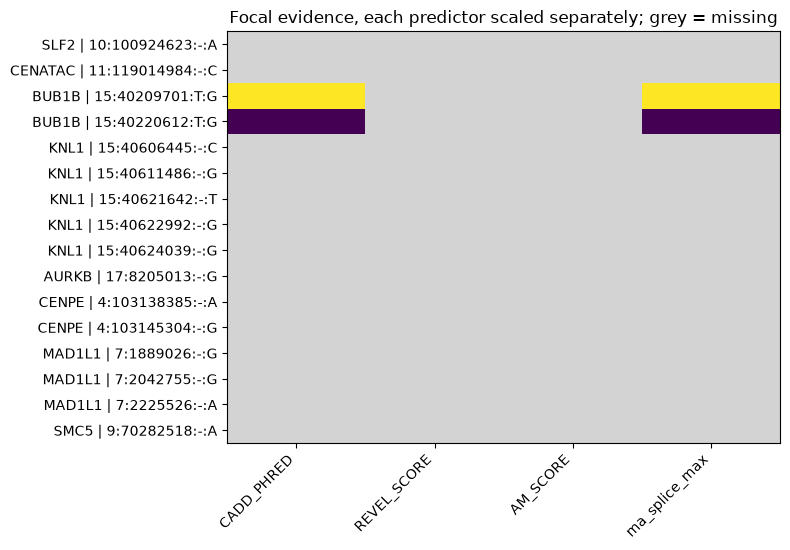

**Raw focal predictor values** — showing 16 of 16 rows.

,ma_focal_gene,VARIANT_KEY,CADD_PHRED,REVEL_SCORE,AM_SCORE,ma_splice_max
0,SLF2,10:100924623:-:A,NaN,NaN,NaN,NaN
1,CENATAC,11:119014984:-:C,NaN,NaN,NaN,NaN
2,BUB1B,15:40209701:T:G,36.0,NaN,NaN,0.03
3,BUB1B,15:40220612:T:G,24.5,0.472,0.9229,0.02
4,KNL1,15:40606445:-:C,NaN,NaN,NaN,NaN
5,KNL1,15:40611486:-:G,NaN,NaN,NaN,NaN
6,KNL1,15:40621642:-:T,NaN,NaN,NaN,NaN
7,KNL1,15:40622992:-:G,NaN,NaN,NaN,NaN
8,KNL1,15:40624039:-:G,NaN,NaN,NaN,NaN
9,AURKB,17:8205013:-:G,NaN,NaN,NaN,NaN


In [12]:
ma_gene_to_group = {ma_gene: ma_group for ma_group, ma_genes in ma_focal_groups.items() for ma_gene in ma_genes}
ma_symbol_hits = ma_gene_rows.loc[ma_gene_rows["SYMBOL"].isin(ma_focal_genes)].copy()
ma_symbol_hits["ma_review_af"] = ma_symbol_hits[ma_af_columns].max(axis=1, skipna=True)
ma_symbol_hits.loc[ma_symbol_hits[ma_af_columns].notna().sum(axis=1).eq(0), "ma_review_af"] = ma_np.nan
ma_symbol_hits["ma_splice_max"] = ma_symbol_hits[ma_ds_columns].max(axis=1, skipna=True)
ma_symbol_hits.loc[ma_symbol_hits[ma_ds_columns].notna().sum(axis=1).eq(0), "ma_splice_max"] = ma_np.nan
ma_symbol_hits["ma_match_basis"] = "SYMBOL"
ma_symbol_hits["ma_focal_gene"] = ma_symbol_hits["SYMBOL"]
ma_splice_associations = (
    ma_rows.loc[
        ma_rows["SPLICEAI_GENE"].notna()
        & ma_rows["SPLICEAI_GENE"].astype("string").str.strip().ne("")
    ]
    .sort_values(
        ["_ma_canonical", "_ma_priority", "_ma_order"],
        ascending=[False, False, True], kind="stable", na_position="last",
    )
    .drop_duplicates(["VARIANT_KEY", "SPLICEAI_GENE"], keep="first")
)
ma_splice_hits = ma_splice_associations.loc[
    ma_splice_associations["SPLICEAI_GENE"].isin(ma_focal_genes)
    & ~ma_splice_associations["SPLICEAI_GENE"].eq(ma_splice_associations["SYMBOL"])
].copy()
ma_splice_hits["ma_review_af"] = ma_splice_hits[ma_af_columns].max(axis=1, skipna=True)
ma_splice_hits.loc[ma_splice_hits[ma_af_columns].notna().sum(axis=1).eq(0), "ma_review_af"] = ma_np.nan
ma_splice_hits["ma_splice_max"] = ma_splice_hits[ma_ds_columns].max(axis=1, skipna=True)
ma_splice_hits.loc[ma_splice_hits[ma_ds_columns].notna().sum(axis=1).eq(0), "ma_splice_max"] = ma_np.nan
ma_splice_hits["ma_match_basis"] = "SPLICEAI_GENE"
ma_splice_hits["ma_focal_gene"] = ma_splice_hits["SPLICEAI_GENE"]
ma_mva_all = ma_pd.concat([ma_symbol_hits, ma_splice_hits], ignore_index=True, sort=False)
ma_mva_all["ma_gene_group"] = ma_mva_all["ma_focal_gene"].map(ma_gene_to_group)
ma_mva_all["ma_frequency_context"] = ma_np.select(
    [ma_mva_all["ma_review_af"].isna(), ma_mva_all["ma_review_af"].le(0.001)],
    ["unknown", "rare (≤0.001)"], default="commoner (>0.001)",
)
ma_group_rank = {ma_group: ma_rank for ma_rank, ma_group in enumerate(ma_focal_groups)}
ma_mva_all["ma_group_rank"] = ma_mva_all["ma_gene_group"].map(ma_group_rank)

ma_mva_literature = ma_pd.DataFrame([
    {
        "analytical_group": "Canonical MVA", "genes": "BUB1B, CEP57, TRIP13",
        "mechanism_context": "BUB1B/TRIP13 checkpoint timing and attachment surveillance; CEP57 spindle organization",
        "association_qualifier": "Established canonical MVA genes; phenotype and tumor spectrum differ by gene",
        "required_inheritance_evidence": "Two disease-relevant alleles with genotype, phase/segregation and phenotype/cytogenetic fit",
        "source": "MedlinePlus; Hanks 2004; Snape 2011; Yost 2017",
    },
    {
        "analytical_group": "Additional reported MVA/chromosomal-instability associations",
        "genes": "CENATAC, MAD1L1", "mechanism_context": "Reported chromosome-segregation/chromosomal-instability phenotypes",
        "association_qualifier": "Limited primary reports; no prevalence or formal validity grade asserted",
        "required_inheritance_evidence": "Variant-level evidence, inheritance matching the report, segregation, phenotype and cytogenetics",
        "source": "CENATAC PMC8280824; MAD1L1 doi:10.1126/sciadv.abq5914",
    },
    {
        "analytical_group": "Related overlapping Atelis syndrome", "genes": "SLF2, SMC5",
        "mechanism_context": "Genome stability and reported mosaic variegated hyperploidy overlap",
        "association_qualifier": "Related syndrome, distinct from classical checkpoint-related MVA",
        "required_inheritance_evidence": "Disease-relevant alleles, segregation, phenotype and cytogenetic concordance",
        "source": "doi:10.1038/s41467-022-34349-8",
    },
    {
        "analytical_group": "Mechanism-context genes", "genes": "BUB1, MAD2L1, CDC20, CENPE, KNL1, NDC80, PLK1, AURKB",
        "mechanism_context": "Spindle checkpoint, kinetochore attachment or chromosome segregation",
        "association_qualifier": "Pathway membership alone is not MVA causation; BUB1 has a distinct reported recessive developmental disorder",
        "required_inheritance_evidence": "Independent gene–disease validity plus variant, inheritance, segregation and phenotype evidence",
        "source": "BUB1 doi:10.1126/sciadv.abk0114; review doi:10.1038/s41576-024-00762-6",
    },
])
ma_show_table(ma_mva_literature, "MVA literature framework", n=len(ma_mva_literature))

ma_presence = ma_pd.DataFrame({"gene": sorted(ma_focal_genes)})
ma_presence["analytical_group"] = ma_presence["gene"].map(ma_gene_to_group)
ma_presence["distinct_symbol_variants"] = ma_presence["gene"].map(
    ma_symbol_hits.groupby("SYMBOL")["VARIANT_KEY"].nunique()
).fillna(0).astype(int)
ma_presence["distinct_splice_target_variants"] = ma_presence["gene"].map(
    ma_splice_hits.groupby("SPLICEAI_GENE")["VARIANT_KEY"].nunique()
).fillna(0).astype(int)
ma_presence["status"] = ma_np.where(
    ma_presence[["distinct_symbol_variants", "distinct_splice_target_variants"]].sum(axis=1).gt(0),
    "represented", "not represented in this filtered CSV",
)
ma_show_table(ma_presence, "Focal-gene presence/absence", n=len(ma_presence))

ma_mva_columns = [
    "VARIANT_KEY", "ma_focal_gene", "ma_gene_group", "ma_match_basis", "SYMBOL",
    "SPLICEAI_GENE", "HGVS_C", "HGVS_P", "FEATURE_TRANSCRIPT", "CONSEQUENCE",
    "IMPACT", "ma_frequency_context", "ma_review_af", "CLIN_SIG",
    "ACMG_CLASSIFICATION", "CADD_PHRED", "REVEL_SCORE", "AM_SCORE", "AM_CLASS",
    "ma_splice_max", "PRIORITY_SCORE",
]
ma_show_table(
    ma_mva_all.sort_values(["ma_group_rank", "ma_focal_gene", "POS", "VARIANT_KEY"]),
    "All focal-gene evidence (unfiltered)", n=ma_top_n,
)

ma_heatmap_columns = ["CADD_PHRED", "REVEL_SCORE", "AM_SCORE", "ma_splice_max"]
ma_heatmap = ma_mva_all.drop_duplicates(["VARIANT_KEY", "ma_focal_gene"]).set_index(
    ["ma_focal_gene", "VARIANT_KEY"]
)[ma_heatmap_columns]
if ma_heatmap.empty:
    ma_display(ma_Markdown("**MVA evidence heatmap:** no focal variants represented."))
else:
    ma_scaled_heatmap = ma_heatmap.copy()
    for ma_col in ma_heatmap_columns:
        ma_col_values = ma_scaled_heatmap[ma_col]
        ma_min, ma_max = ma_col_values.min(), ma_col_values.max()
        ma_scaled_heatmap[ma_col] = (
            (ma_col_values - ma_min) / (ma_max - ma_min)
            if ma_pd.notna(ma_min) and ma_pd.notna(ma_max) and ma_max > ma_min
            else ma_np.nan
        )
    ma_fig, ma_ax = ma_plt.subplots(figsize=(8, max(3, len(ma_scaled_heatmap) * 0.35)))
    ma_masked = ma_np.ma.masked_invalid(ma_scaled_heatmap.to_numpy(dtype=float))
    ma_cmap = ma_plt.cm.viridis.copy()
    ma_cmap.set_bad("lightgrey")
    ma_ax.imshow(ma_masked, aspect="auto", interpolation="nearest", cmap=ma_cmap, vmin=0, vmax=1)
    ma_ax.set_xticks(range(len(ma_heatmap_columns)), ma_heatmap_columns, rotation=45, ha="right")
    ma_ax.set_yticks(range(len(ma_scaled_heatmap)), [f"{ma_gene} | {ma_key}" for ma_gene, ma_key in ma_scaled_heatmap.index])
    ma_ax.set_title("Focal evidence, each predictor scaled separately; grey = missing")
    ma_plt.tight_layout()
    ma_plt.show()
    ma_show_table(ma_heatmap.reset_index(), "Raw focal predictor values", n=ma_top_n)

**Interpretation after execution.** Presence means only that an annotation row or splice-target association is present. A single row does not establish a heterozygous carrier because genotype is absent; two variants may be cis, artifacts, or transcript duplicates. `BUB1B` can involve hypomorphic alleles, so no blanket loss-of-function rule is applied. Follow-up requires raw-read QC, genotype, phase/segregation, phenotype, and cytogenetics.

## 10. Gene patterns

**Question.** Which genes have multiple distinct keys or LoF-like annotation categories? `ma_gene_summary` counts variant–gene associations, consequence classes, numeric rare and unknown-frequency variants, predictor coverage, and imported inheritance labels. Genes can overlap global totals because one key may associate with multiple genes.

“LoF-like” means only `stop_gained`, `frameshift_variant`, `splice_acceptor_variant`, or `splice_donor_variant` appears in the annotation. It is not validated loss of function and does not assign PVS1. Multiple keys do not establish biallelic, compound-heterozygous, carrier, de novo, or mosaic status.

In [13]:
ma_gene_rows["ma_review_af"] = ma_gene_rows[ma_af_columns].max(axis=1, skipna=True)
ma_gene_rows.loc[ma_gene_rows[ma_af_columns].notna().sum(axis=1).eq(0), "ma_review_af"] = ma_np.nan
ma_gene_rows["ma_consequence_set"] = ma_gene_rows["CONSEQUENCE"].astype("string").str.replace("&", ", ")
ma_lof_terms = {"stop_gained", "frameshift_variant", "splice_acceptor_variant", "splice_donor_variant"}
ma_gene_rows["ma_lof_like"] = ma_gene_rows["CONSEQUENCE"].astype("string").map(
    lambda ma_value: bool(set(str(ma_value).split("&")) & ma_lof_terms)
)

ma_gene_summary = (
    ma_gene_rows.groupby("SYMBOL", dropna=True)
    .agg(
        distinct_variants=("VARIANT_KEY", "nunique"),
        consequence_classes=("ma_consequence_set", lambda ma_values: "; ".join(sorted(set(ma_values.dropna())))),
        numeric_rare_variants=("ma_review_af", lambda ma_values: int(ma_values.le(0.001).sum())),
        unknown_af_variants=("ma_review_af", lambda ma_values: int(ma_values.isna().sum())),
        cadd_coverage=("CADD_PHRED", "count"), revel_coverage=("REVEL_SCORE", "count"),
        am_coverage=("AM_SCORE", "count"), splice_coverage=("SPLICEAI_MAX_DS", "count"),
        lof_like_annotations=("ma_lof_like", "sum"),
        imported_inheritance_labels=("INHERITANCE_MODEL", lambda ma_values: "; ".join(sorted(set(ma_values.dropna().astype(str))))),
    )
    .sort_values(["distinct_variants", "numeric_rare_variants"], ascending=False)
)
ma_multi_variant_genes = ma_gene_summary.loc[ma_gene_summary["distinct_variants"].ge(2)].copy()
ma_show_table(ma_gene_summary.reset_index(), "Gene-association summary", n=ma_top_n)
ma_show_table(ma_multi_variant_genes.reset_index(), "Genes with at least two distinct keys", n=ma_top_n)

**Gene-association summary** — showing 30 of 8,876 rows.

,SYMBOL,distinct_variants,consequence_classes,numeric_rare_variants,unknown_af_variants,cadd_coverage,revel_coverage,am_coverage,splice_coverage,lof_like_annotations,imported_inheritance_labels
0,HLA-DRB1,105,frameshift_variant; inframe_deletion; missense...,0,75,9,0,0,0,13,Compound_Het_Candidate (105_hits)
1,ZNF717,91,frameshift_variant; inframe_deletion; missense...,2,72,12,0,0,0,8,Compound_Het_Candidate (91_hits)
2,MUC19,74,frameshift_variant; inframe_deletion; inframe_...,0,3,0,0,0,0,7,Compound_Het_Candidate (74_hits)
3,MUC3A,64,frameshift_variant; inframe_deletion; inframe_...,3,30,28,0,0,0,5,Compound_Het_Candidate (64_hits)
4,HLA-C,58,"missense_variant; missense_variant,NMD_transcr...",0,9,0,0,0,0,0,Compound_Het_Candidate (58_hits)
5,MUC16,56,"missense_variant; missense_variant,splice_regi...",0,0,0,0,0,0,0,Compound_Het_Candidate (56_hits)
6,HLA-DQA1,50,"frameshift_variant; frameshift_variant,NMD_tra...",0,12,5,0,0,0,9,Compound_Het_Candidate (50_hits)
7,HLA-DRB5,50,frameshift_variant; missense_variant; splice_d...,0,30,5,0,0,0,8,Compound_Het_Candidate (50_hits)
8,MUC6,49,frameshift_variant; missense_variant,7,28,7,2,2,2,2,Compound_Het_Candidate (49_hits)
9,MUC4,46,frameshift_variant; inframe_deletion; inframe_...,4,9,8,2,0,3,2,Compound_Het_Candidate (46_hits)


**Genes with at least two distinct keys** — showing 30 of 3,825 rows.

,SYMBOL,distinct_variants,consequence_classes,numeric_rare_variants,unknown_af_variants,cadd_coverage,revel_coverage,am_coverage,splice_coverage,lof_like_annotations,imported_inheritance_labels
0,HLA-DRB1,105,frameshift_variant; inframe_deletion; missense...,0,75,9,0,0,0,13,Compound_Het_Candidate (105_hits)
1,ZNF717,91,frameshift_variant; inframe_deletion; missense...,2,72,12,0,0,0,8,Compound_Het_Candidate (91_hits)
2,MUC19,74,frameshift_variant; inframe_deletion; inframe_...,0,3,0,0,0,0,7,Compound_Het_Candidate (74_hits)
3,MUC3A,64,frameshift_variant; inframe_deletion; inframe_...,3,30,28,0,0,0,5,Compound_Het_Candidate (64_hits)
4,HLA-C,58,"missense_variant; missense_variant,NMD_transcr...",0,9,0,0,0,0,0,Compound_Het_Candidate (58_hits)
5,MUC16,56,"missense_variant; missense_variant,splice_regi...",0,0,0,0,0,0,0,Compound_Het_Candidate (56_hits)
6,HLA-DQA1,50,"frameshift_variant; frameshift_variant,NMD_tra...",0,12,5,0,0,0,9,Compound_Het_Candidate (50_hits)
7,HLA-DRB5,50,frameshift_variant; missense_variant; splice_d...,0,30,5,0,0,0,8,Compound_Het_Candidate (50_hits)
8,MUC6,49,frameshift_variant; missense_variant,7,28,7,2,2,2,2,Compound_Het_Candidate (49_hits)
9,MUC4,46,frameshift_variant; inframe_deletion; inframe_...,4,9,8,2,0,3,2,Compound_Het_Candidate (46_hits)


**Interpretation after execution.** High counts prioritize gene-level review but cannot determine allelic configuration. Unknown AF remains separate from rare AF. Review LoF-like rows against transcript relevance, NMD context, variant quality, and gene mechanism before any clinical criterion is considered.

## 11. Protein positions

**Question.** Where do focal variants fall along each protein transcript? Plots are separated by `SYMBOL` **and** `FEATURE_TRANSCRIPT`, use only simple integral `PROTEIN_POS`, color by consequence, and label `HGVS_P`. X-axis is annotated residue position; no protein length or domain is fabricated.

Missing, ranges, uncertain, or nonintegral positions are counted and skipped. Visible clustering is descriptive—not a hotspot significance test. Different isoforms are never combined.

Protein-position plotting retains **16** focal rows and skips **0** missing/nonintegral/range positions.

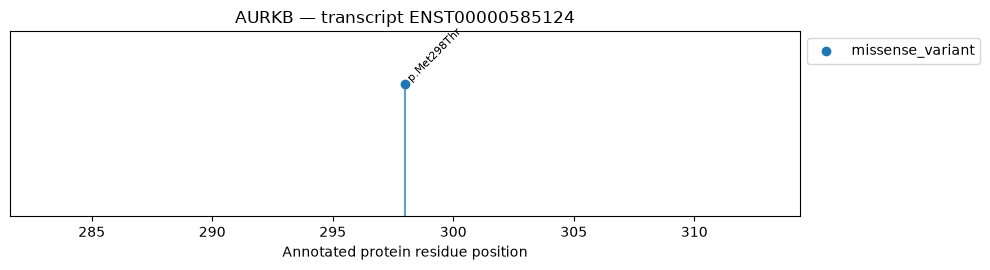

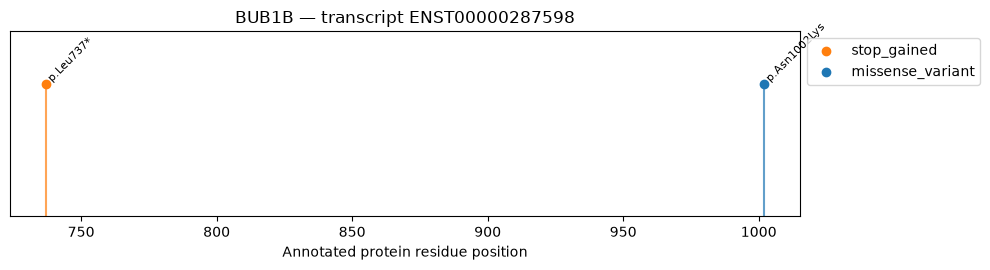

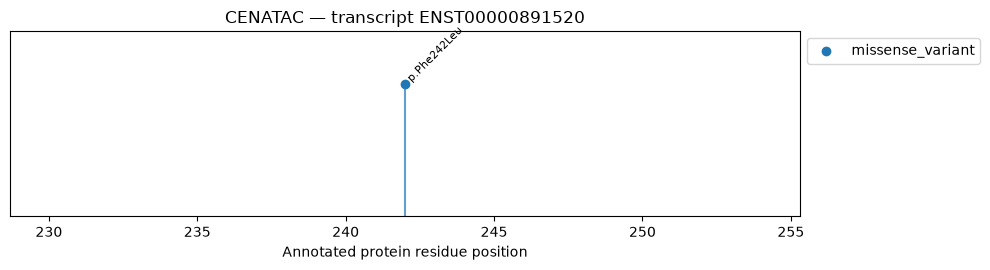

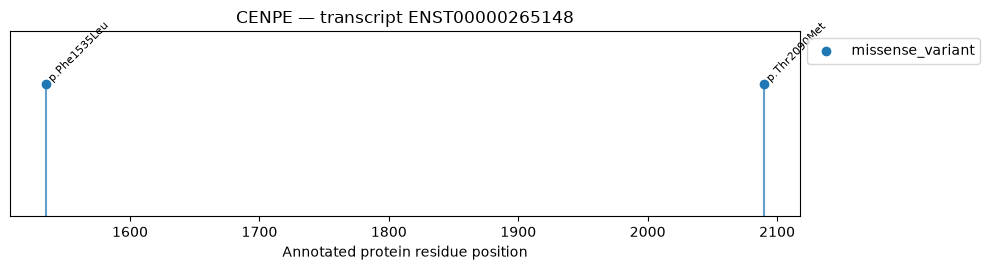

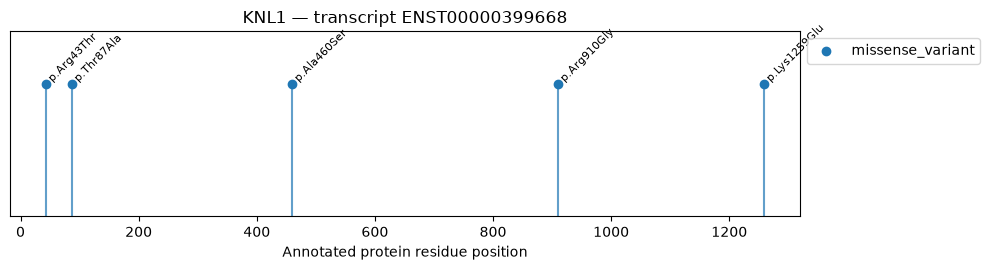

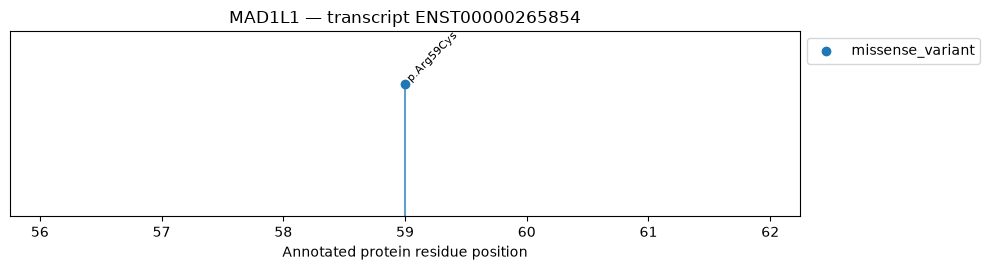

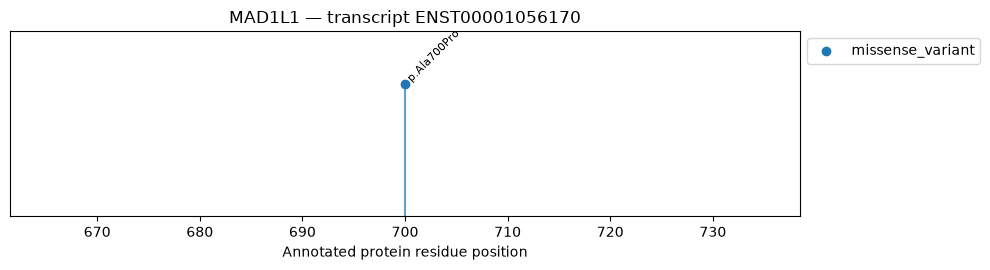

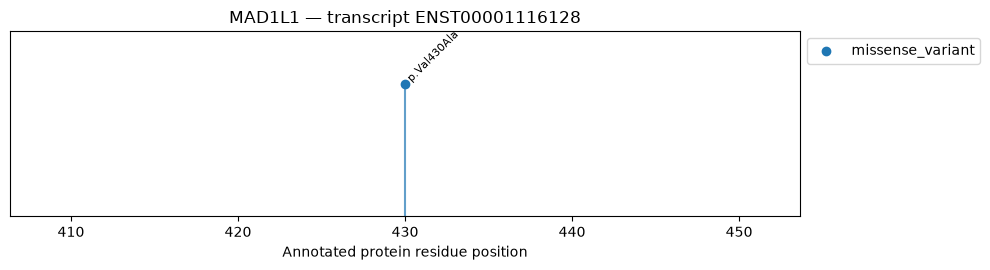

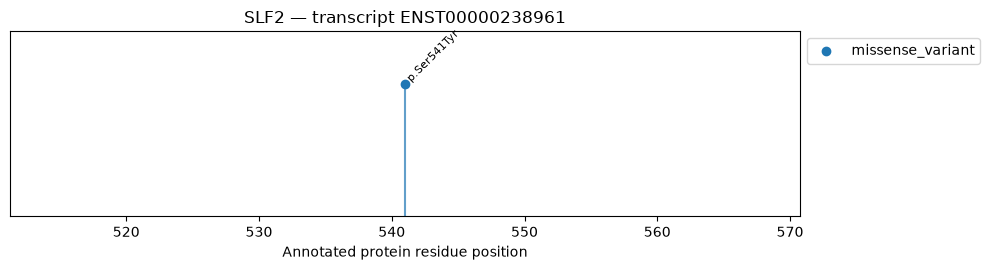

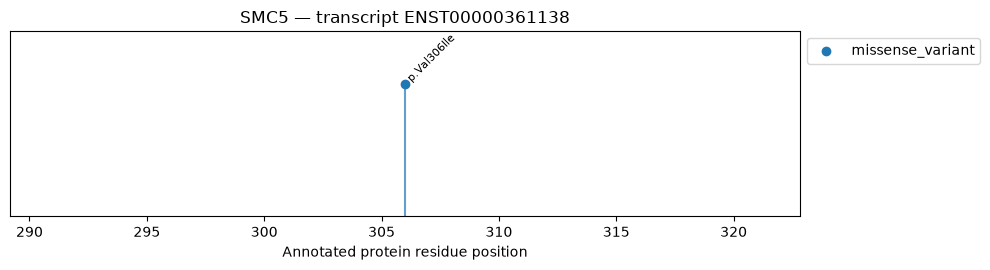

In [14]:
ma_protein_source = ma_mva_all.loc[ma_mva_all["ma_match_basis"].eq("SYMBOL")].copy()
ma_protein_token = ma_protein_source["PROTEIN_POS"].astype("string").str.strip()
ma_protein_valid = ma_protein_token.str.fullmatch(r"[1-9]\d*", na=False)
ma_protein_skipped = int((~ma_protein_valid).sum())
ma_display(ma_Markdown(
    f"Protein-position plotting retains **{int(ma_protein_valid.sum()):,}** focal rows and skips "
    f"**{ma_protein_skipped:,}** missing/nonintegral/range positions."
))
ma_protein_plot = ma_protein_source.loc[ma_protein_valid].copy()
ma_protein_plot["ma_protein_position"] = ma_protein_token.loc[ma_protein_valid].astype(int)
for (ma_gene, ma_transcript), ma_group_frame in ma_protein_plot.groupby(
    ["SYMBOL", "FEATURE_TRANSCRIPT"], dropna=False, sort=True
):
    ma_fig, ma_ax = ma_plt.subplots(figsize=(10, 2.8))
    ma_categories = sorted(ma_group_frame["CONSEQUENCE"].astype("string").unique())
    ma_color_map = {ma_category: ma_plt.cm.tab10(ma_index % 10) for ma_index, ma_category in enumerate(ma_categories)}
    for ma_row_number, (ma_index, ma_record) in enumerate(ma_group_frame.iterrows()):
        ma_x = ma_record["ma_protein_position"]
        ma_color = ma_color_map[str(ma_record["CONSEQUENCE"])]
        ma_ax.vlines(ma_x, 0, 1, color=ma_color, alpha=0.7)
        ma_ax.scatter(ma_x, 1, color=ma_color, label=str(ma_record["CONSEQUENCE"]))
        if not ma_is_missing(ma_record["HGVS_P"]):
            ma_ax.annotate(str(ma_record["HGVS_P"]), (ma_x, 1), rotation=45, ha="left", va="bottom", fontsize=8)
    ma_handles, ma_labels = ma_ax.get_legend_handles_labels()
    ma_unique_legend = dict(zip(ma_labels, ma_handles))
    ma_ax.legend(ma_unique_legend.values(), ma_unique_legend.keys(), loc="upper left", bbox_to_anchor=(1, 1))
    ma_ax.set_ylim(0, 1.4)
    ma_ax.set_yticks([])
    ma_ax.set_xlabel("Annotated protein residue position")
    ma_ax.set_title(f"{ma_gene} — transcript {ma_transcript}")
    ma_plt.tight_layout()
    ma_plt.show()

**Interpretation after execution.** Read each panel independently. A repeated position may reflect multiple alleles or annotations; inspect the raw table. Domain mapping and statistical hotspot assessment require verified transcript/protein resources not present here.

## 12. Phenotype-annotation context

**Question.** Which imported panels and inheritance labels are attached to retained variants? Counts use distinct variants. Empty/NA and `Genome-wide` are excluded from the specific-panel view. These are upstream annotations—not observed symptoms or confirmed inheritance.

High counts may reflect panel design and annotation reuse. No HPO terms are inferred from panel names. Conditional follow-up should compare documented patient findings against MVA literature: prenatal/postnatal growth, microcephaly and neurodevelopment, congenital findings, tumor history, and cytogenetic evidence of variegated aneuploidy ([MedlinePlus](https://medlineplus.gov/genetics/condition/mosaic-variegated-aneuploidy-syndrome/)).

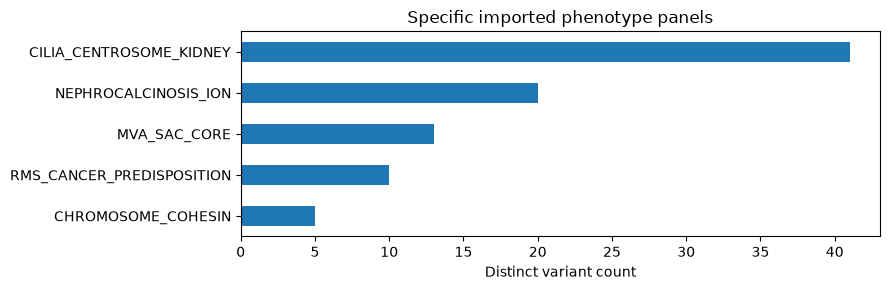

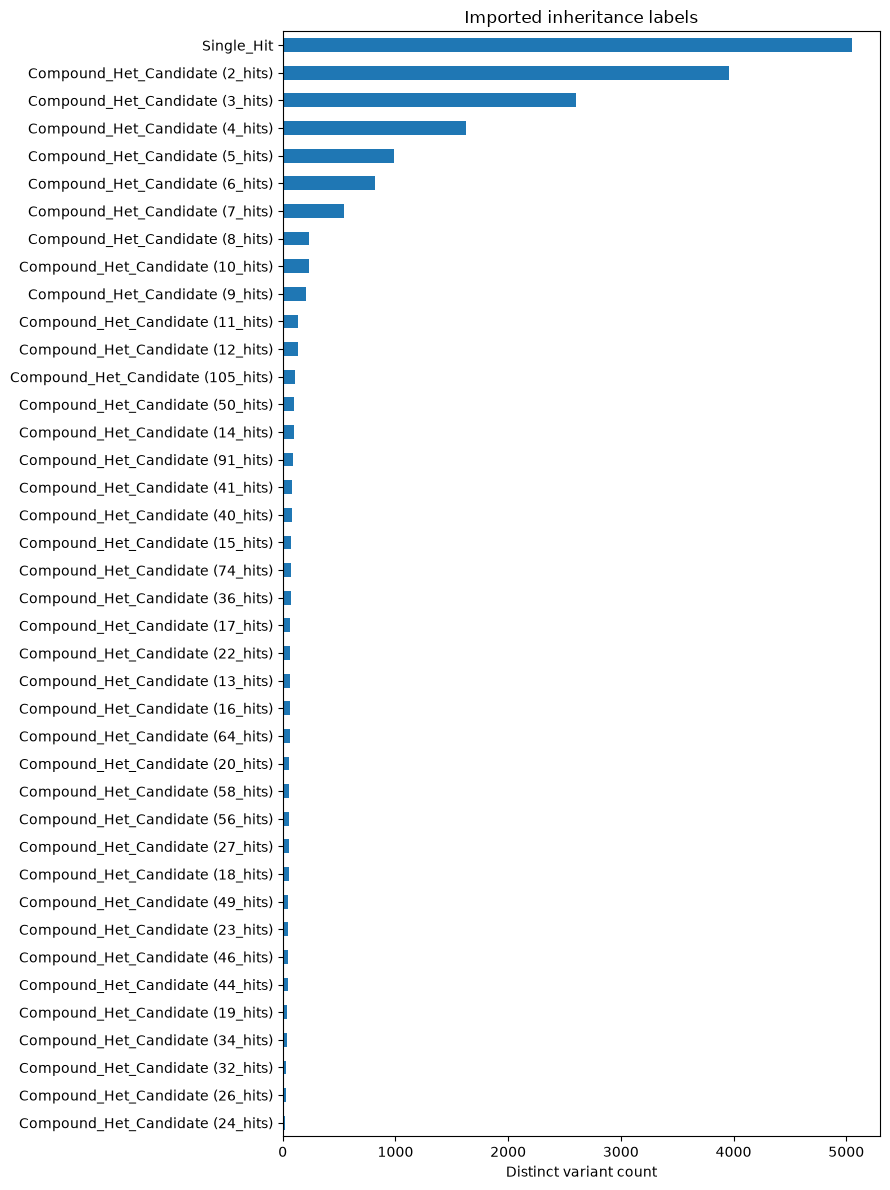

**Conditional phenotype review checklist** — showing 5 of 5 rows.

,review_domain,conditional_evidence_needed,status_here
0,Growth,Documented prenatal and postnatal growth measu...,unavailable
1,Neurodevelopment/head growth,"Measured head circumference, developmental his...",unavailable
2,Congenital findings,Clinical examination and organ-specific records,unavailable
3,Tumor history,Age-appropriate personal/family tumor history;...,unavailable
4,Cytogenetics,"Tissue, method, cell count, chromosome finding...",unavailable


In [15]:
ma_panel_text = ma_variants["PHENOTYPE_PANEL"].astype("string").str.strip()
ma_specific_panel_mask = (
    ma_panel_text.notna()
    & ~ma_panel_text.str.lower().isin(["", "na", "nan", "none", "genome-wide", "genome wide"])
)
ma_plot_counts(ma_panel_text.loc[ma_specific_panel_mask], "Specific imported phenotype panels")
ma_plot_counts(ma_variants["INHERITANCE_MODEL"].astype("string").str.strip(), "Imported inheritance labels")

ma_phenotype_checklist = ma_pd.DataFrame({
    "review_domain": ["Growth", "Neurodevelopment/head growth", "Congenital findings", "Tumor history", "Cytogenetics"],
    "conditional_evidence_needed": [
        "Documented prenatal and postnatal growth measurements",
        "Measured head circumference, developmental history, neurologic findings",
        "Clinical examination and organ-specific records",
        "Age-appropriate personal/family tumor history; gene-specific literature context",
        "Tissue, method, cell count, chromosome findings and mosaic distribution",
    ],
    "status_here": ["unavailable"] * 5,
})
ma_show_table(ma_phenotype_checklist, "Conditional phenotype review checklist", n=len(ma_phenotype_checklist))

**Interpretation after execution.** Panel and inheritance labels can guide chart review but cannot substitute for patient phenotype, pedigree, segregation, or cytogenetics. No clinical management recommendation follows from this table.

## 13. Overlapping review queues

**Question.** Which rows merit targeted manual review under transparent definitions? Queues overlap and remain complete in memory; display is limited to `ma_top_n`, never forced into a 10–30 candidate cutoff.

- `ma_mva_all`: all focal associations, unfiltered.
- `ma_rare_missense`: missense with numeric `ma_review_af ≤ 0.001`.
- `ma_splice_review`: recomputed maximum DS ≥0.2.
- `ma_clinical_review`: P/LP, VUS, conflict, or mixed in either source.
- `ma_unknown_frequency`: no validated review AF.
- `ma_multi_variant_genes`: at least two distinct keys per gene.

Sort order is evidence-specific. Original `PRIORITY_SCORE` remains visible but is not treated as calibrated and is never overwritten.

In [16]:
ma_rare_missense = ma_missense.loc[ma_missense["ma_review_af"].le(0.001)].sort_values(
    ["REVEL_SCORE", "AM_SCORE", "CADD_PHRED", "VARIANT_KEY"],
    ascending=[False, False, False, True], na_position="last",
)
ma_splice_review = ma_variants.loc[ma_variants["ma_splice_max"].ge(0.2)].sort_values(
    ["ma_splice_max", "VARIANT_KEY"], ascending=[False, True],
)
ma_clinical_review = ma_variants.loc[
    ma_variants["ma_clin_sig_category"].isin(["P/LP", "VUS", "conflict", "mixed P/LP with benign/VUS"])
    | ma_variants["ma_acmg_category"].isin(["P/LP", "VUS", "conflict", "mixed P/LP with benign/VUS"])
].sort_values(["ma_clin_sig_category", "ma_acmg_category", "VARIANT_KEY"])
ma_unknown_frequency = ma_variants.loc[ma_variants["ma_review_af"].isna()].sort_values(
    ["CADD_PHRED", "REVEL_SCORE", "AM_SCORE", "VARIANT_KEY"],
    ascending=[False, False, False, True], na_position="last",
)

ma_queue_summary = ma_pd.DataFrame({
    "queue": ["ma_mva_all", "ma_rare_missense", "ma_splice_review", "ma_clinical_review", "ma_unknown_frequency", "ma_multi_variant_genes"],
    "rows_or_genes": [len(ma_mva_all), len(ma_rare_missense), len(ma_splice_review), len(ma_clinical_review), len(ma_unknown_frequency), len(ma_multi_variant_genes)],
})
ma_show_table(ma_queue_summary, "Review-queue sizes", n=len(ma_queue_summary))
ma_show_table(
    ma_mva_all.sort_values(["ma_group_rank", "ma_focal_gene", "POS", "VARIANT_KEY"])[ma_mva_columns],
    "MVA focal queue", n=ma_top_n,
)
ma_show_table(ma_rare_missense, "Rare missense queue", n=ma_top_n)
ma_show_table(ma_splice_review, "Splice queue", n=ma_top_n)
ma_show_table(ma_clinical_review, "Clinical-annotation queue", n=ma_top_n)
ma_show_table(ma_unknown_frequency, "Unknown-frequency queue", n=ma_top_n)
ma_show_table(ma_multi_variant_genes.reset_index(), "Multi-variant gene queue", n=ma_top_n)

**Review-queue sizes** — showing 6 of 6 rows.

,queue,rows_or_genes
0,ma_mva_all,16
1,ma_rare_missense,251
2,ma_splice_review,4
3,ma_clinical_review,925
4,ma_unknown_frequency,1312
5,ma_multi_variant_genes,3825


**MVA focal queue** — showing 16 of 16 rows.

,VARIANT_KEY,ma_focal_gene,ma_gene_group,ma_match_basis,SYMBOL,SPLICEAI_GENE,HGVS_C,HGVS_P,FEATURE_TRANSCRIPT,CONSEQUENCE,...,ma_frequency_context,ma_review_af,CLIN_SIG,ACMG_CLASSIFICATION,CADD_PHRED,REVEL_SCORE,AM_SCORE,AM_CLASS,ma_splice_max,PRIORITY_SCORE
2,15:40209701:T:G,BUB1B,Canonical MVA,SYMBOL,BUB1B,BUB1B,c.2210T>G,p.Leu737*,ENST00000287598,stop_gained,...,rare (≤0.001),9.830390e-05,"pathogenic,likely_pathogenic",Pathogenic,36.0,NaN,NaN,,0.03,170.0
3,15:40220612:T:G,BUB1B,Canonical MVA,SYMBOL,BUB1B,PAK6,c.3006T>G,p.Asn1002Lys,ENST00000287598,missense_variant,...,rare (≤0.001),8.474300e-07,-,Likely Pathogenic,24.5,0.472,0.9229,likely_pathogenic,0.02,150.0
1,11:119014984:-:C,CENATAC,Additional reported MVA/chromosomal-instabilit...,SYMBOL,CENATAC,,-,p.Phe242Leu,ENST00000891520,missense_variant,...,commoner (>0.001),7.200000e-03,-,Uncertain Significance (VUS),NaN,NaN,NaN,,NaN,35.0
12,7:1889026:-:G,MAD1L1,Additional reported MVA/chromosomal-instabilit...,SYMBOL,MAD1L1,,-,p.Ala700Pro,ENST00001056170,missense_variant,...,commoner (>0.001),7.464000e-01,-,Benign,NaN,NaN,NaN,,NaN,50.0
13,7:2042755:-:G,MAD1L1,Additional reported MVA/chromosomal-instabilit...,SYMBOL,MAD1L1,,-,p.Val430Ala,ENST00001116128,missense_variant,...,commoner (>0.001),9.962000e-01,-,Benign,NaN,NaN,NaN,,NaN,50.0
14,7:2225526:-:A,MAD1L1,Additional reported MVA/chromosomal-instabilit...,SYMBOL,MAD1L1,,-,p.Arg59Cys,ENST00000265854,missense_variant,...,rare (≤0.001),6.000000e-04,"likely_benign,pathogenic,benign",Pathogenic,NaN,NaN,NaN,,NaN,160.0
0,10:100924623:-:A,SLF2,Related overlapping Atelis syndrome,SYMBOL,SLF2,,-,p.Ser541Tyr,ENST00000238961,missense_variant,...,commoner (>0.001),3.187000e-01,-,Benign,NaN,NaN,NaN,,NaN,-15.0
15,9:70282518:-:A,SMC5,Related overlapping Atelis syndrome,SYMBOL,SMC5,,-,p.Val306Ile,ENST00000361138,missense_variant,...,commoner (>0.001),8.550000e-01,-,Benign,NaN,NaN,NaN,,NaN,-25.0
9,17:8205013:-:G,AURKB,Mechanism-context genes,SYMBOL,AURKB,,-,p.Met298Thr,ENST00000585124,missense_variant,...,commoner (>0.001),7.360000e-01,-,Benign,NaN,NaN,NaN,,NaN,20.0
10,4:103138385:-:A,CENPE,Mechanism-context genes,SYMBOL,CENPE,,-,p.Thr2090Met,ENST00000265148,missense_variant,...,commoner (>0.001),1.098000e-01,benign,Benign,NaN,NaN,NaN,,NaN,50.0


**Rare missense queue** — showing 30 of 251 rows.

...

,PRIORITY_SCORE,SYMBOL,HGVS_P,HGVS_C,ACMG_CLASSIFICATION,ACMG_CRITERIA,INHERITANCE_MODEL,PHENOTYPE_PANEL,CHROM,POS,...,_ma_priority,ma_variant_type,ma_review_af,ma_af_bin,ma_numeric_rare_001,ma_clin_sig_category,ma_acmg_category,ma_splice_max,ma_splice_partial,ma_splice_max_difference
107,105.0,DHTKD1,p.Val360Ala,-,Likely Pathogenic,PM2; PM3; PP3,Compound_Het_Candidate (7_hits),Genome-wide,10,12091604,...,105.0,SNV,0.001000,"(1e-4,1e-3]",True,B/LB,P/LP,NaN,False,NaN
575,125.0,LDB3,p.Arg354*,-,Pathogenic,PVS1; PM2; PM3,Compound_Het_Candidate (2_hits),Genome-wide,10,86726174,...,125.0,SNV,0.001400,"(1e-3,1e-2]",False,B/LB,P/LP,NaN,False,NaN
1037,105.0,ACAD8,p.Ser171Cys,-,Likely Pathogenic,PM2; PM3; PP3,Compound_Het_Candidate (2_hits),Genome-wide,11,134259029,...,105.0,SNV,0.006800,"(1e-3,1e-2]",False,B/LB,P/LP,NaN,False,NaN
1864,105.0,SHANK2,p.Tyr967Cys,-,Likely Pathogenic,PM2; PM3; PP3,Compound_Het_Candidate (2_hits),Genome-wide,11,70487393,...,105.0,SNV,0.009000,"(1e-3,1e-2]",False,B/LB,P/LP,NaN,False,NaN
2639,95.0,PRPH,-,-,Pathogenic,PVS1; PM2,Single_Hit,Genome-wide,12,49297274,...,95.0,SNV,0.000800,"(1e-4,1e-3]",True,B/LB,P/LP,NaN,False,NaN
3366,125.0,JAG2,p.Gln214*,-,Pathogenic,PVS1; PM2; PM3,Compound_Het_Candidate (3_hits),Genome-wide,14,105155823,...,125.0,SNV,0.000400,"(1e-4,1e-3]",True,B/LB,P/LP,NaN,False,NaN
4410,125.0,MESP1,p.Ala53AX,c.158-159C>CG,Pathogenic,PVS1; PM2; PM3,Compound_Het_Candidate (3_hits),Genome-wide,15,89751073,...,125.0,insertion,0.324200,>1e-2,False,B/LB,P/LP,NaN,False,NaN
4504,105.0,TXNDC11,p.Leu709Val,-,Likely Pathogenic,PM2; PM3; PP3,Compound_Het_Candidate (7_hits),Genome-wide,16,11687885,...,105.0,SNV,0.003800,"(1e-3,1e-2]",False,B/LB,P/LP,NaN,False,NaN
5109,125.0,METTL22,p.Arg161RLLRG*RVV*LLSLPAPWLTCCLTTLLX,c.481-482C>CGCCTGCTCCGTGGCTGACGTGTTGTCTAACTACT...,Pathogenic,PVS1; PM2; PM3,Compound_Het_Candidate (6_hits),Genome-wide,16,8645986,...,125.0,insertion,0.895526,>1e-2,False,B/LB,P/LP,NaN,False,NaN
7035,105.0,KMT2B,p.Arg1488Trp,c.4462C>T,Likely Pathogenic,PM2; PM3; PP3,Compound_Het_Candidate (3_hits),Genome-wide,19,35727950,...,105.0,SNV,0.000091,"(1e-5,1e-4]",True,B/LB,P/LP,0.01,False,0.0


**Unknown-frequency queue** — showing 30 of 1,312 rows.

,PRIORITY_SCORE,SYMBOL,HGVS_P,HGVS_C,ACMG_CLASSIFICATION,ACMG_CRITERIA,INHERITANCE_MODEL,PHENOTYPE_PANEL,CHROM,POS,...,_ma_priority,ma_variant_type,ma_review_af,ma_af_bin,ma_numeric_rare_001,ma_clin_sig_category,ma_acmg_category,ma_splice_max,ma_splice_partial,ma_splice_max_difference
12992,125.0,THUMPD3,p.Glu288*,c.862G>T,Pathogenic,PVS1; PM2; PM3,Compound_Het_Candidate (3_hits),Genome-wide,3,9374570,...,125.0,SNV,NaN,unknown,False,other,P/LP,0.00,False,0.0
11838,95.0,SOCS5,p.Gln410*,c.1228C>T,Pathogenic,PVS1; PM2,Single_Hit,Genome-wide,2,46759758,...,95.0,SNV,NaN,unknown,False,other,P/LP,0.00,False,0.0
5661,35.0,C1QL1,p.Lys196Glu,c.586T>C,Uncertain Significance (VUS),PM2,Single_Hit,Genome-wide,17,44967463,...,35.0,SNV,NaN,unknown,False,other,other,0.04,False,0.0
6376,35.0,PIK3C3,p.Met777Leu,c.2329A>T,Uncertain Significance (VUS),PM2,Single_Hit,Genome-wide,18,42057948,...,35.0,SNV,NaN,unknown,False,other,other,0.01,False,0.0
6313,65.0,LAMA3,p.Asn364His,c.1090A>C,Uncertain Significance (VUS),PM2; PM3,Compound_Het_Candidate (3_hits),Genome-wide,18,23763431,...,65.0,SNV,NaN,unknown,False,other,other,0.00,False,0.0
5387,65.0,GIT1,p.Val234Ala,c.701A>G,Uncertain Significance (VUS),PM2; PM3,Compound_Het_Candidate (2_hits),Genome-wide,17,29581755,...,65.0,SNV,NaN,unknown,False,other,other,0.00,False,0.0
9898,95.0,ENSG00000303040,-,-,Pathogenic,PVS1; PM2,Single_Hit,Genome-wide,20,29114913,...,95.0,SNV,NaN,unknown,False,other,P/LP,NaN,False,NaN
7972,65.0,FUT5,p.Pro45Leu,c.134G>A,Uncertain Significance (VUS),PM2; PM3; BP4,Compound_Het_Candidate (4_hits),Genome-wide,19,5867592,...,65.0,SNV,NaN,unknown,False,other,other,0.00,False,0.0
3922,55.0,SERPINA1,p.Ala308Val,c.923G>A,Likely Benign,PM2; PM3; BP4; BP6,Compound_Het_Candidate (18_hits),Genome-wide,14,94379606,...,55.0,SNV,NaN,unknown,False,B/LB,B/LB,0.00,False,0.0
1957,95.0,ENSG00000307436,-,-,Pathogenic,PVS1; PM2,Single_Hit,Genome-wide,11,81208842,...,95.0,SNV,NaN,unknown,False,other,P/LP,NaN,False,NaN


**Multi-variant gene queue** — showing 30 of 3,825 rows.

,SYMBOL,distinct_variants,consequence_classes,numeric_rare_variants,unknown_af_variants,cadd_coverage,revel_coverage,am_coverage,splice_coverage,lof_like_annotations,imported_inheritance_labels
0,HLA-DRB1,105,frameshift_variant; inframe_deletion; missense...,0,75,9,0,0,0,13,Compound_Het_Candidate (105_hits)
1,ZNF717,91,frameshift_variant; inframe_deletion; missense...,2,72,12,0,0,0,8,Compound_Het_Candidate (91_hits)
2,MUC19,74,frameshift_variant; inframe_deletion; inframe_...,0,3,0,0,0,0,7,Compound_Het_Candidate (74_hits)
3,MUC3A,64,frameshift_variant; inframe_deletion; inframe_...,3,30,28,0,0,0,5,Compound_Het_Candidate (64_hits)
4,HLA-C,58,"missense_variant; missense_variant,NMD_transcr...",0,9,0,0,0,0,0,Compound_Het_Candidate (58_hits)
5,MUC16,56,"missense_variant; missense_variant,splice_regi...",0,0,0,0,0,0,0,Compound_Het_Candidate (56_hits)
6,HLA-DQA1,50,"frameshift_variant; frameshift_variant,NMD_tra...",0,12,5,0,0,0,9,Compound_Het_Candidate (50_hits)
7,HLA-DRB5,50,frameshift_variant; missense_variant; splice_d...,0,30,5,0,0,0,8,Compound_Het_Candidate (50_hits)
8,MUC6,49,frameshift_variant; missense_variant,7,28,7,2,2,2,2,Compound_Het_Candidate (49_hits)
9,MUC4,46,frameshift_variant; inframe_deletion; inframe_...,4,9,8,2,0,3,2,Compound_Het_Candidate (46_hits)


**Interpretation after execution.** Queue membership is a transparent review rule, not a rank of causal probability. Unknown frequency is not rare. Overlap across queues may strengthen the case for manual review but does not make computational evidence independent.

## 14. Case worksheet, limitations, provenance, and next evidence

**Question.** What can a reviewer inspect now, and what evidence is unavailable? The worksheet keeps focal variant identity, transcript, gene group, population, clinical, missense, splice, and imported-priority fields together. Every unavailable case-level item is named rather than imputed.

Potential next evidence includes raw-read/variant QC, genotype, allele balance, phase and segregation, verified reference/transcript mapping, phenotype/HPO documentation, cytogenetics, and targeted RNA/functional work where justified. These are evidence needs—not clinical management recommendations.

In [17]:
ma_worksheet_columns = [
    "VARIANT_KEY", "CHROM_NORM", "POS", "REF", "ALT", "ma_focal_gene", "ma_gene_group",
    "ma_match_basis", "SYMBOL", "SPLICEAI_GENE", "FEATURE_TRANSCRIPT", "HGVS_C", "HGVS_P",
    "CONSEQUENCE", "IMPACT", "ma_review_af", "GNOMAD_STATUS", "GNOMAD_AC", "GNOMAD_AN",
    "GNOMAD_NHOMALT", "CLIN_SIG", "ACMG_CLASSIFICATION", "ACMG_CRITERIA", "CADD_RAW",
    "CADD_PHRED", "SIFT_PRED", "SIFT_SCORE", "POLYPHEN_PRED", "POLYPHEN_SCORE",
    "REVEL_SCORE", "AM_SCORE", "AM_CLASS", "ma_splice_max", "INHERITANCE_MODEL",
    "PHENOTYPE_PANEL", "PRIORITY_SCORE",
]
ma_case_worksheet = ma_mva_all.sort_values(
    ["ma_group_rank", "ma_focal_gene", "POS", "VARIANT_KEY"]
)[ma_worksheet_columns].copy()
ma_show_table(ma_case_worksheet, "MVA case worksheet", n=ma_top_n)

ma_unavailable = ma_pd.DataFrame({
    "evidence_item": [
        "Genotype and zygosity", "Allele depth/balance and read QC", "Phase",
        "Segregation/family data", "Observed HPO terms and phenotype confirmation",
        "Cytogenetic aneuploidy findings", "CNV/SV evidence", "Mosaic fraction",
        "ClinVar review stars/date/condition context", "AlphaGenome results",
        "Exomiser results", "Verified reference-build provenance",
    ],
    "status": ["unavailable in supplied header"] * 12,
    "consequence": [
        "Cannot call heterozygous, homozygous, carrier, or biallelic state",
        "Cannot assess support, artifacts, or mosaic allele balance", "Cannot establish cis/trans",
        "Cannot establish de novo status or familial segregation", "Cannot score phenotype fit",
        "Cannot establish mosaic variegated aneuploidy", "Cannot infer copy-number or structural causes",
        "Cannot infer mosaicism", "Cannot weight ClinVar assertions",
        "No AlphaGenome analysis is possible from this CSV", "No Exomiser analysis is possible from this CSV",
        "GRCh38 is claimed upstream but not independently verified here",
    ],
})
ma_show_table(ma_unavailable, "Unavailable evidence", n=len(ma_unavailable))

ma_provenance = ma_pd.DataFrame({
    "item": ["configured input", "reference assembly", "Python", "pandas", "numpy", "matplotlib", "rarity sensitivity", "splice review", "REVEL markers", "AlphaMissense markers", "exports"],
    "value": [
        str(ma_csv_path), "GRCh38 claimed upstream; not verified", ma_platform.python_version(),
        ma_pd.__version__, ma_np.__version__, ma_plt.matplotlib.__version__,
        "1e-4, 1e-3, 1e-2 exploratory", "recomputed max DS ≥0.2",
        "0.5 and 0.75 exploratory legacy", "0.34 and 0.564 developer categories", "none",
    ],
})
ma_show_table(ma_provenance, "Run provenance and thresholds", n=len(ma_provenance))

**MVA case worksheet** — showing 16 of 16 rows.

,VARIANT_KEY,CHROM_NORM,POS,REF,ALT,ma_focal_gene,ma_gene_group,ma_match_basis,SYMBOL,SPLICEAI_GENE,...,SIFT_SCORE,POLYPHEN_PRED,POLYPHEN_SCORE,REVEL_SCORE,AM_SCORE,AM_CLASS,ma_splice_max,INHERITANCE_MODEL,PHENOTYPE_PANEL,PRIORITY_SCORE
2,15:40209701:T:G,15,40209701,T,G,BUB1B,Canonical MVA,SYMBOL,BUB1B,BUB1B,...,NaN,-,NaN,NaN,NaN,,0.03,Compound_Het_Candidate (2_hits),MVA_SAC_CORE,170.0
3,15:40220612:T:G,15,40220612,T,G,BUB1B,Canonical MVA,SYMBOL,BUB1B,PAK6,...,0.01,probably_damaging,0.997,0.472,0.9229,likely_pathogenic,0.02,Compound_Het_Candidate (2_hits),MVA_SAC_CORE,150.0
1,11:119014984:-:C,11,119014984,-,C,CENATAC,Additional reported MVA/chromosomal-instabilit...,SYMBOL,CENATAC,,...,0.71,-,NaN,NaN,NaN,,NaN,Single_Hit,Genome-wide,35.0
12,7:1889026:-:G,7,1889026,-,G,MAD1L1,Additional reported MVA/chromosomal-instabilit...,SYMBOL,MAD1L1,,...,0.05,-,NaN,NaN,NaN,,NaN,Compound_Het_Candidate (3_hits),MVA_SAC_CORE,50.0
13,7:2042755:-:G,7,2042755,-,G,MAD1L1,Additional reported MVA/chromosomal-instabilit...,SYMBOL,MAD1L1,,...,0.33,-,NaN,NaN,NaN,,NaN,Compound_Het_Candidate (3_hits),MVA_SAC_CORE,50.0
14,7:2225526:-:A,7,2225526,-,A,MAD1L1,Additional reported MVA/chromosomal-instabilit...,SYMBOL,MAD1L1,,...,0.06,possibly_damaging,0.874,NaN,NaN,,NaN,Compound_Het_Candidate (3_hits),MVA_SAC_CORE,160.0
0,10:100924623:-:A,10,100924623,-,A,SLF2,Related overlapping Atelis syndrome,SYMBOL,SLF2,,...,0.00,possibly_damaging,0.677,NaN,NaN,,NaN,Single_Hit,Genome-wide,-15.0
15,9:70282518:-:A,9,70282518,-,A,SMC5,Related overlapping Atelis syndrome,SYMBOL,SMC5,,...,0.24,benign,0.000,NaN,NaN,,NaN,Single_Hit,Genome-wide,-25.0
9,17:8205013:-:G,17,8205013,-,G,AURKB,Mechanism-context genes,SYMBOL,AURKB,,...,0.27,benign,0.000,NaN,NaN,,NaN,Single_Hit,MVA_SAC_CORE,20.0
10,4:103138385:-:A,4,103138385,-,A,CENPE,Mechanism-context genes,SYMBOL,CENPE,,...,0.06,benign,0.015,NaN,NaN,,NaN,Compound_Het_Candidate (2_hits),MVA_SAC_CORE,50.0


**Unavailable evidence** — showing 12 of 12 rows.

,evidence_item,status,consequence
0,Genotype and zygosity,unavailable in supplied header,"Cannot call heterozygous, homozygous, carrier,..."
1,Allele depth/balance and read QC,unavailable in supplied header,"Cannot assess support, artifacts, or mosaic al..."
2,Phase,unavailable in supplied header,Cannot establish cis/trans
3,Segregation/family data,unavailable in supplied header,Cannot establish de novo status or familial se...
4,Observed HPO terms and phenotype confirmation,unavailable in supplied header,Cannot score phenotype fit
5,Cytogenetic aneuploidy findings,unavailable in supplied header,Cannot establish mosaic variegated aneuploidy
6,CNV/SV evidence,unavailable in supplied header,Cannot infer copy-number or structural causes
7,Mosaic fraction,unavailable in supplied header,Cannot infer mosaicism
8,ClinVar review stars/date/condition context,unavailable in supplied header,Cannot weight ClinVar assertions
9,AlphaGenome results,unavailable in supplied header,No AlphaGenome analysis is possible from this CSV


**Run provenance and thresholds** — showing 11 of 11 rows.

,item,value
0,configured input,/Users/macbookpro/Documents/RA/mva-hackathon/d...
1,reference assembly,GRCh38 claimed upstream; not verified
2,Python,3.13.8
3,pandas,3.0.5
4,numpy,2.5.3
5,matplotlib,3.11.2
6,rarity sensitivity,"1e-4, 1e-3, 1e-2 exploratory"
7,splice review,recomputed max DS ≥0.2
8,REVEL markers,0.5 and 0.75 exploratory legacy
9,AlphaMissense markers,0.34 and 0.564 developer categories


**Interpretation after execution.** This appendix supports descriptive research triage only. It cannot diagnose MVA, assign ACMG criteria, infer aneuploidy from chromosome counts, infer mosaicism/CNV/SV, establish inheritance, or estimate personal cancer risk. Saving an executed notebook persists sensitive outputs; clear outputs before sharing. No files are exported.

### Bibliography

- CADD score definition and limitations: [CADD documentation](https://cadd.gs.washington.edu/info).
- REVEL ensemble and correlated components: [official project](https://sites.google.com/site/revelgenomics/), [Ioannidis et al.](https://doi.org/10.1016/j.ajhg.2016.08.016).
- AlphaMissense: [reference repository](https://github.com/google-deepmind/alphamissense), [Science paper](https://doi.org/10.1126/science.adg7492), [EMBL-EBI score guide](https://www.ebi.ac.uk/training/online/courses/alphafold/classifying-the-effects-of-missense-variants-using-alphamissense/understanding-pathogenicity-scores-from-alphamissense/).
- SpliceAI DS/DP fields and 0.2/0.5/0.8 operating points: [official README](https://github.com/Illumina/SpliceAI).
- gnomAD group-maximum AF versus filtering AF: [maintainer clarification](https://discuss.gnomad.broadinstitute.org/t/difference-between-popmax-in-the-vcf-and-popmax-grpmaxfaf-in-the-website/63); [gnomAD v4 context](https://gnomad.broadinstitute.org/news/2023-11-gnomad-v4-0/).
- ClinVar classification and review context: [clinical significance](https://www.ncbi.nlm.nih.gov/clinvar/docs/clinsig/), [review status](https://www.ncbi.nlm.nih.gov/clinvar/docs/review_status/).
- MVA overview and canonical genes: [MedlinePlus](https://medlineplus.gov/genetics/condition/mosaic-variegated-aneuploidy-syndrome/); [Hanks et al., BUB1B](https://doi.org/10.1038/ng1449); [Snape et al., CEP57](https://doi.org/10.1038/ng.822); [Yost et al., TRIP13](https://doi.org/10.1038/ng.3883).
- Additional/related associations: [CENATAC](https://pmc.ncbi.nlm.nih.gov/articles/PMC8280824/), [SLF2/SMC5](https://doi.org/10.1038/s41467-022-34349-8), [MAD1L1](https://doi.org/10.1126/sciadv.abq5914), [BUB1](https://doi.org/10.1126/sciadv.abk0114), [chromosomal-instability review](https://doi.org/10.1038/s41576-024-00762-6).
- AlphaGenome documentation is relevant only as a future evidence source: [AlphaGenome docs](https://www.alphagenomedocs.com/). No AlphaGenome result columns are present here.

## Optional in-memory synthetic checks

This function is defined but **not called**. A researcher may run `ma_run_synthetic_checks()` only after executing the helper cells. It uses tiny in-memory frames and performs no file, network, subprocess, installation, or export operation. Expected result when explicitly called later: all assertions pass and the function returns `"synthetic checks passed"`.

In [18]:
def ma_run_synthetic_checks():
    ma_base = {ma_col: ma_pd.NA for ma_col in ma_expected_columns}
    ma_base.update({
        "CHROM": "chr1", "POS": "100", "REF": "A", "ALT": "G", "VARIANT_KEY": "1:100:A:G",
        "SYMBOL": "BUB1B", "CONSEQUENCE": "missense_variant", "IMPACT": "MODERATE",
        "CANONICAL": "YES", "PRIORITY_SCORE": "1", "GNOMAD_RARE_FLAG": "False",
        "GNOMAD_STATUS": "not_found", "AF_POPULATION": ".", "GNOMAD_AF": ".",
        "GNOMAD_GRPMAX_AF": ".", "CLIN_SIG": "conflicting_interpretations_of_pathogenicity",
        "DS_AG": ".1", "DS_AL": ".7", "DS_DG": ".2", "DS_DL": ".0",
        "DP_AG": "1", "DP_AL": "-2", "DP_DG": "3", "DP_DL": "4",
        "SPLICEAI_MAX_DS": ".7", "SIFT_SCORE": ".", "POLYPHEN_SCORE": ".",
        "REVEL_SCORE": ".", "AM_SCORE": ".",
    })
    ma_duplicate = ma_base.copy()
    ma_duplicate.update({"CANONICAL": "NO", "FEATURE_TRANSCRIPT": "ENST_ALT", "SYMBOL": "CEP57", "PRIORITY_SCORE": "0"})
    ma_frame = ma_pd.DataFrame([ma_base, ma_duplicate])
    ma_clean, ma_unique, ma_genes, ma_test_issues = ma_prepare(ma_frame)
    assert ma_clean.loc[0, "GNOMAD_RARE_FLAG"] == False
    assert ma_unique.loc[0, ["AF_POPULATION", "GNOMAD_AF", "GNOMAD_GRPMAX_AF"]].isna().all()
    assert ma_unique.loc[0, "GNOMAD_STATUS"] == "not_found"
    assert len(ma_unique) == 1
    assert set(ma_genes["SYMBOL"]) == {"BUB1B", "CEP57"}
    assert ma_clinical_category("conflicting_interpretations_of_pathogenicity") == "conflict"
    assert ma_unique.loc[0, ["SIFT_SCORE", "POLYPHEN_SCORE", "REVEL_SCORE", "AM_SCORE"]].isna().all()
    assert ma_unique.loc[0, ma_ds_columns].max() == 0.7
    assert ma_unique.loc[0, "POS"] + ma_unique.loc[0, "DP_AL"] == 98

    ma_missing_optional_frame = ma_pd.DataFrame([{
        "CHROM": "1", "POS": "101", "REF": "C", "ALT": "T", "VARIANT_KEY": "1:101:C:T",
        "SYMBOL": "GENE1", "CONSEQUENCE": "missense_variant", "IMPACT": "MODERATE",
    }])
    ma_missing_clean, ma_missing_unique, ma_missing_genes, ma_missing_issues = ma_prepare(ma_missing_optional_frame)
    assert ma_missing_unique["CADD_PHRED"].isna().all()
    assert (ma_missing_issues["reason"] == "optional column missing").any()

    ma_bad = ma_missing_optional_frame.copy()
    ma_bad.loc[0, "POS"] = "100.5"
    try:
        ma_prepare(ma_bad)
        raise AssertionError("Malformed POS must raise ValueError")
    except ValueError:
        pass
    ma_bad_key = ma_missing_optional_frame.copy()
    ma_bad_key.loc[0, "VARIANT_KEY"] = "1:999:C:T"
    try:
        ma_prepare(ma_bad_key)
        raise AssertionError("Inconsistent key must raise ValueError")
    except ValueError:
        pass

    ma_header_only = ma_pd.DataFrame(columns=list(ma_required_columns))
    ma_empty_clean, ma_empty_unique, ma_empty_genes, ma_empty_issues = ma_prepare(ma_header_only)
    assert ma_empty_unique.empty and ma_empty_genes.empty
    assert not ma_empty_issues.empty
    return "synthetic checks passed"